# Flujo de trabajo Bayesiano

In [ ]:
# ==========================
# Entorno PyMC + PreliZ para Colab actual
# ==========================

!pip uninstall -y \
    pymc \
    pytensor \
    preliz \
    arviz \
    arviz_stats \
    numba \
    llvmlite

!pip install -U --no-cache-dir \
    "numpy==2.0.2" \
    "scipy==1.16.1" \
    "pandas==2.3.0" \
    "matplotlib==3.10.0" \
    "arviz==0.22.0" \
    "pymc==5.28.5" \
    "preliz==0.20.0"

print("\n==============================")
print("INSTALACIÓN TERMINADA")
print("Ahora hacé Runtime > Restart session")
print("y recién después ejecutá las demás celdas.")
print("==============================")

In [ ]:
import arviz as az
import pymc as pm
import preliz as pz

import numpy as np
import scipy.stats as stats
import pandas as pd
import matplotlib.pyplot as plt

az.style.use("arviz-doc")

In [ ]:
#| code-fold: true

az.style.use('arviz-doc')

In [ ]:
#| code-fold: true

#import arviz as az
#import matplotlib.pyplot as plt
#import numpy as np
#import pandas as pd
#import pymc as pm
#!pip install preliz
#import preliz as pz

# **1. Interpretación de los datos:**

Los datos que reunimos y procesamos, no suelen ofrecer respuestas claras por sí mismos sino que necesitan de un proceso de organización, interpretación y contextualización para que sean una herramienta útil. El modelado es aquello que permite traducir supuestos en desafíos y estructuras concretas.

En el caso particular de la Estadística Bayesiana, los modelos probabilísticos que estuvimos conociendo hasta ahora son los que nos permiten realizar esta tarea, a través del planteo de creencias previas (priors), la definición de cómo se relacionan los datos con esas creencias (likelihoods) para luego aplicar el Teorema de Bayes que nospermite actualizar creencias para realizar inferencias.

Aunque este procedimiento resume la esencia de la inferencia bayesiana, deja fuera muchos aspectos prácticos y metodológicos del trabajo con modelos. Estos elementos —desde la formulación del problema hasta la validación y comunicación de resultados— todavía carecen, en muchos casos, de formalizaciones sólidas o herramientas consolidadas. Este capítulo se enfoca en ese flujo de trabajo bayesiano, abordando cómo pasar de datos y suposiciones a insights valiosos y accionables.

Trabajaremos con los aspectos metodológicos a tener en cuenta cuando aplicamos modelos probabilísticos bayesianos, explorando todos los pasos necesarios (desde modelizar hasta validar y comunicar los resultados), concepto conocido como <font color="orange"> *Flujo de trabajo bayesiano*.

El ***flujo de trabajo bayesiano*** es un proceso iterativo: se propone un modelo, se evalúa y, si es necesario, se modifica o se reemplaza. Los modelos son aproximaciones de la realidad, por lo que su utilidad debe comprobarse en cada etapa.

También es fundamental evaluar la calidad de las muestras obtenidas mediante los métodos computacionales utilizados para realizar la inferencia.

Construir un buen modelo requiere conocimientos estadísticos, comprensión del problema y manejo de herramientas computacionales. Es habitual tener que probar distintas alternativas, detectar errores y ajustar el modelo varias veces antes de llegar a una solución adecuada. La mejor forma de aprender este proceso es, justamente, mediante la práctica.

## 1.1. Pruebas predictivas




### <font color="pink"> **PASO A: pedictivas a priori**

La distribución predictiva a priori se define como:


$$
p(y^\ast) =  \int_{\Theta} p(y^\ast \mid \theta) \; p(\theta) \; d\theta
$$

donde $y^\ast$ representa datos no observados pero potencialmente observables, al menos de acuerdo a nuestro modelo. Los datos generados son predictivos ya que son los datos que el modelo espera ver, es decir son los datos no observados pero potencialmente observables.

Con esta idea "marginalizamos" el likelihood al integrar sobre todos los valores posibles del prior. Por lo tanto, desde la perspectiva de nuestro modelo, estamos describiendo la distribución marginal de los datos, es decir independientemente de los parámetros.Esto es, estamos generando predicciones del modelo "antes" de ver los datos. Esta distribución representa lo que el modelo "cree" sobre la cantidad modelada.



***Procedimiento de generación de muestras:***

Paso 1. Elegimos un valor de $\theta$ de acuerdo a la distribución a priori $p(\theta \mid y)$

Paso 2. Fijamos $\theta$ en la distribución que usamos como likelihood $p(y^\ast \mid \theta)$ y generamos una muestra aleatoria

Paso 3. Repetimos desde 1, tantas veces como muestras necesitemos



La distribución predictiva previa permite evaluar si las consecuencias del modelo son razonables antes de observar los datos. Para ello, se generan datos simulados y se comparan con valores o rangos considerados plausibles según el conocimiento del problema.

Por ejemplo, podemos preguntarnos: ¿los valores simulados se encuentran mayormente dentro de un rango razonable? ¿aparecen resultados extremos o poco realistas?

Esta evaluación no consiste en comparar directamente con los datos observados, sino con información de referencia, como registros históricos, valores mínimos y máximos esperados u otras características conocidas del fenómeno.

**Vamos con un ejemplo: Predadores y presas**

Modelicemos la relación entre las masas de organismos que cumplen el rol de presas, con la de aquellos organismos predadores. La idea es estudiar como las masas varían en órdenes de magnitud desde una célula de 1e-14 gramos a una ballena azul de 1.5e8 gramos.


\begin{align}
    \mu =& Normal(\cdots, \cdots) \\
    \sigma =& HalfNormal(\cdots) \\
    log(masas) =& Normal(\mu, \sigma)
\end{align}

Para el modelo planteado trabajaremos en  escala logarítmica, dada la pequeñez de los valores que manejaremos.


Nota:

* vamos a definir los valores del prior, con algunos priors de ejemplo y analizar la escala.

* Para el caso de la predictiva a priori usaremos `pm.sample_prior_predictive()` en vez de `sample`.

In [ ]:
pp_mass = pd.read_csv("pp_mass.csv")
pp_mass["predator_log"] = np.log(pp_mass["predator"])
pp_mass["prey_log"] = np.log(pp_mass["prey"])

# valores de referencia en escala log
refs = {"Planeta Tierra":np.log(5.97e+27),
        "Ballena Azul":np.log(1.5e8),
        "Célula más pequeña":np.log(1e-14)}

construcción del modelo

In [ ]:
with pm.Model() as model:
    α = pm.Normal("α", 0, 100)
    β = pm.Normal("β", 0, 100)
    σ = pm.HalfNormal("σ", 5)
    presa = pm.Normal("presa", α + β * pp_mass["prey_log"], σ, observed=pp_mass["predator_log"])
    idata = pm.sample_prior_predictive(samples=100)

*idata* no tiene grupo `posterior`, pero si tiene `prior` y `prior_predictive`, observen la estructura siguiente:

In [ ]:
idata

Inference data with groups:
	> prior
	> prior_predictive
	> observed_data

/tmp/ipykernel_285/1423550799.py:12: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


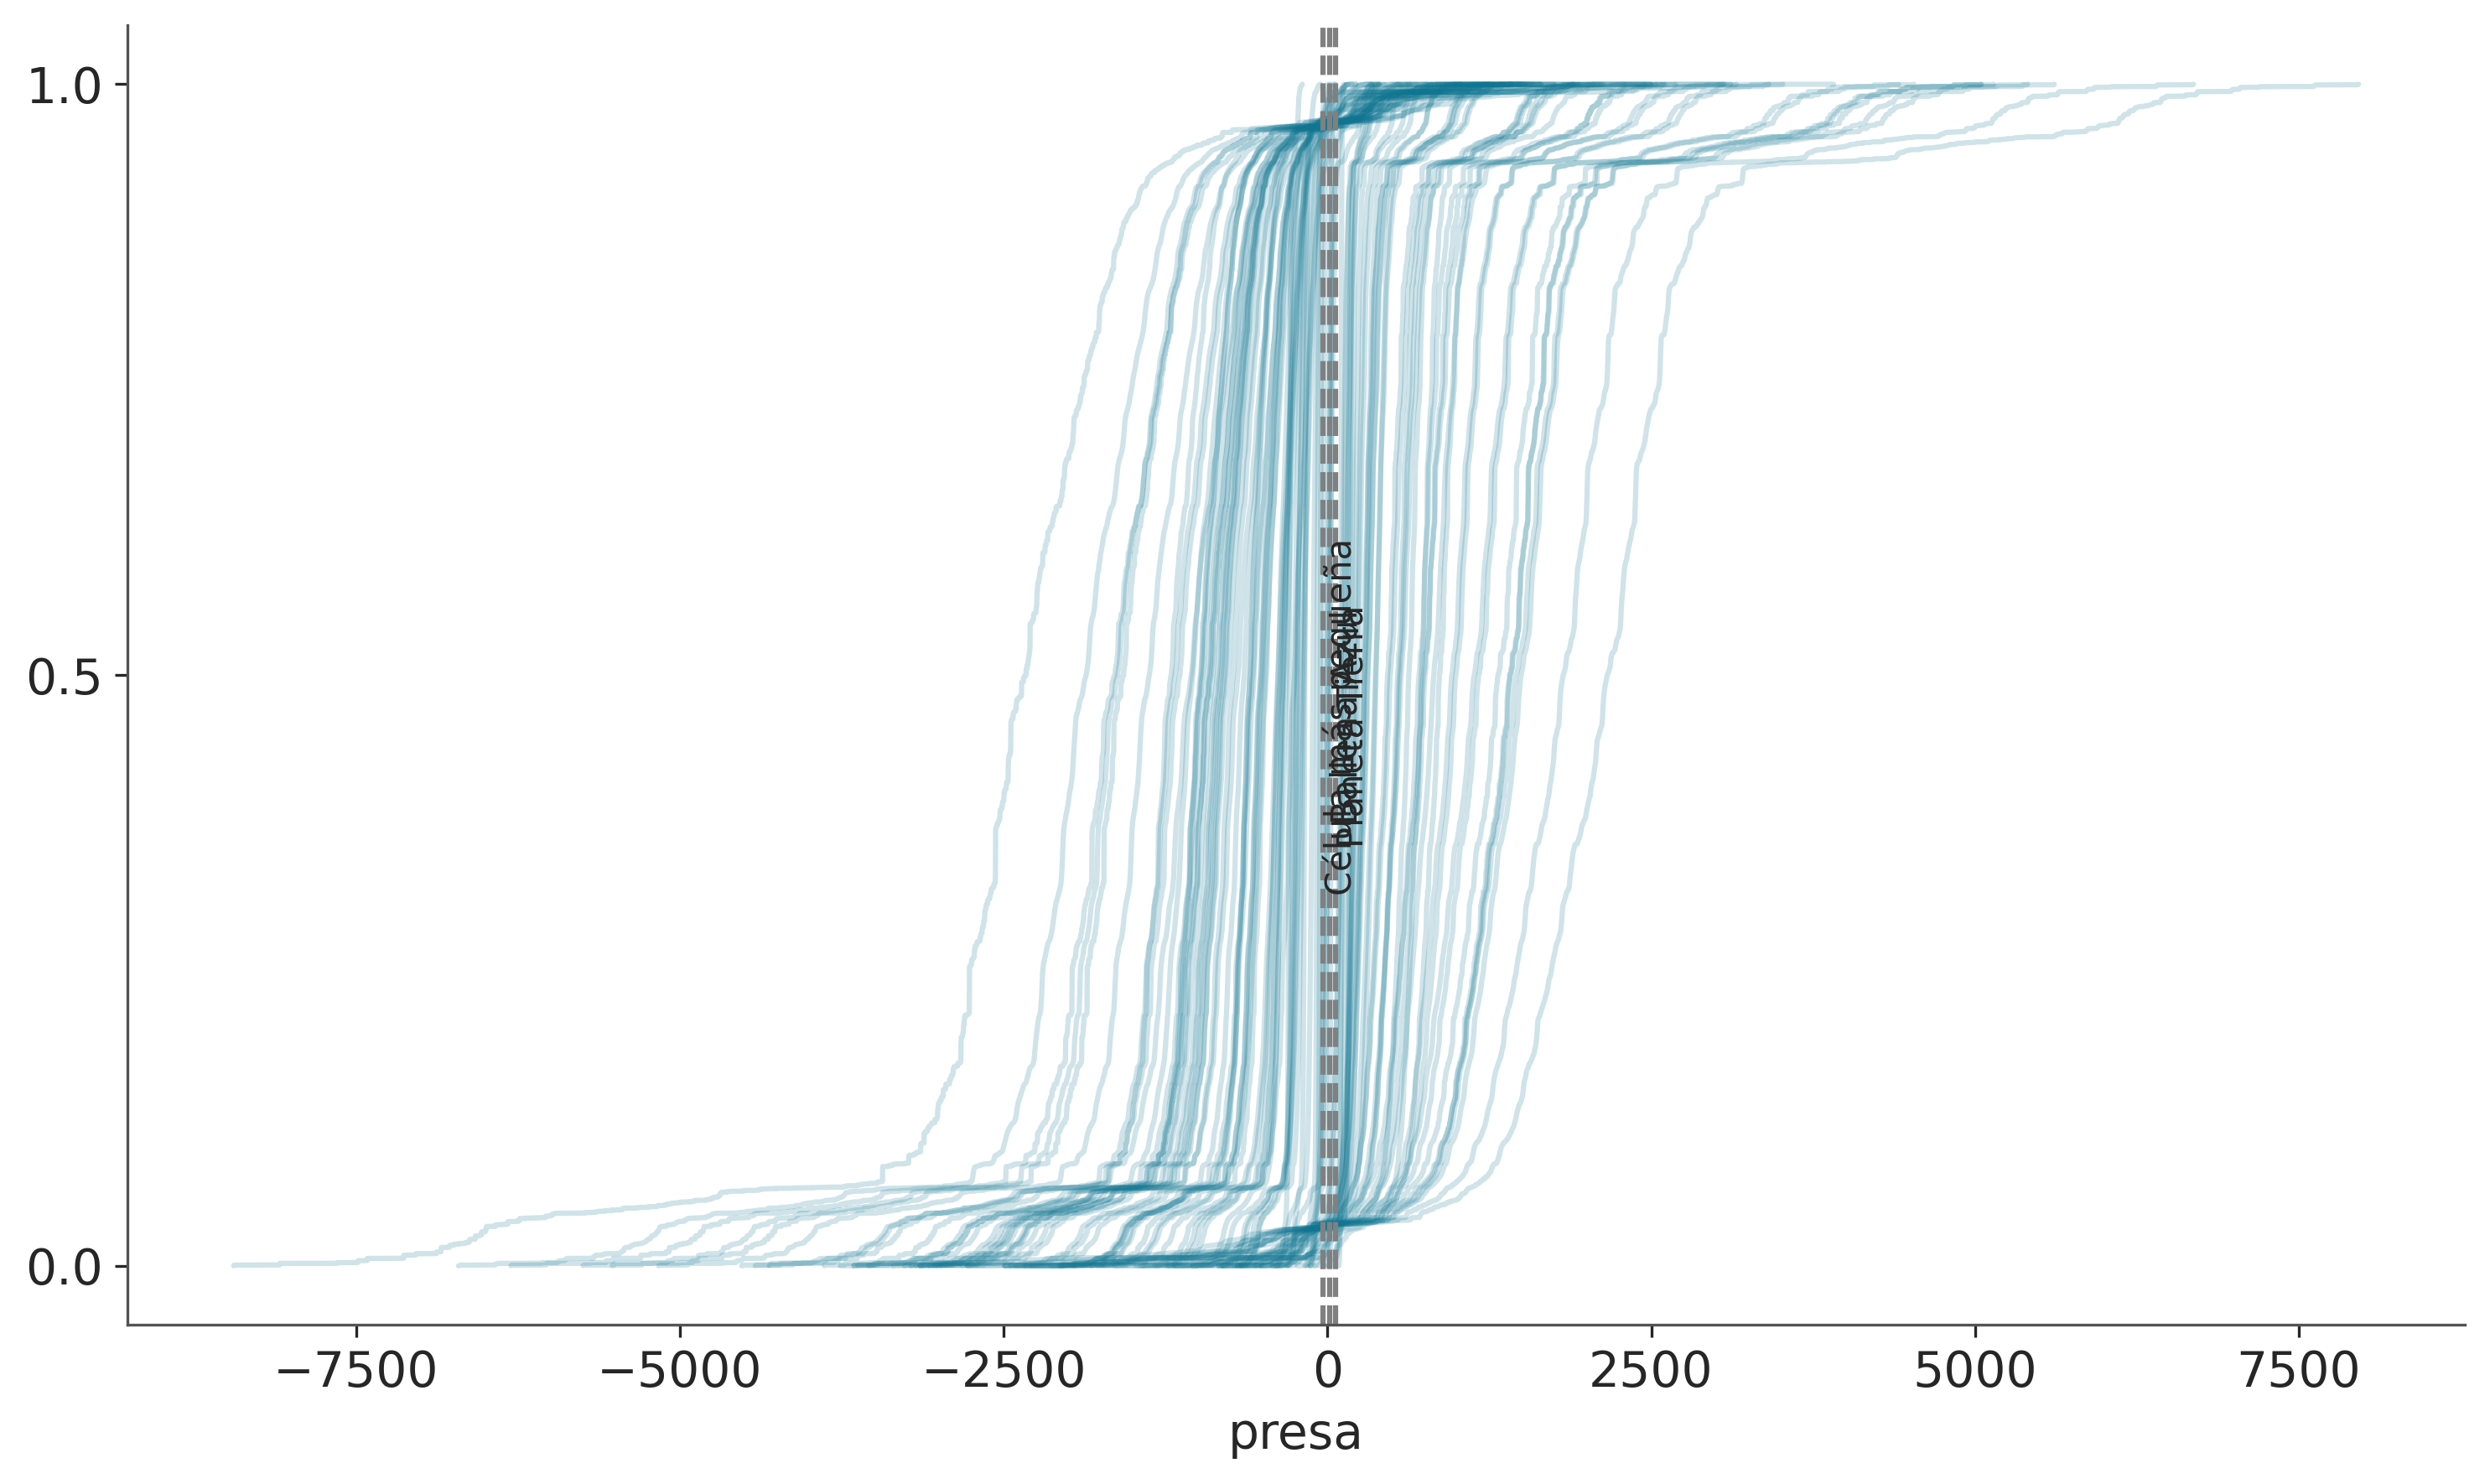

In [ ]:
# crear figura y ejes con tamaño personalizado
fig, ax = plt.subplots(figsize=(10, 6))  # ancho x alto en pulgadas

# dibujar ppc sobre ese eje
az.plot_ppc(idata, group="prior", kind="cumulative", mean=False, legend=False, ax=ax)

# luego tus líneas y textos
for key, val in refs.items():
    ax.axvline(val, ls="--", color="0.5")
    ax.text(val-7, 0.5-(len(key)/100), key, rotation=90)

plt.tight_layout()
plt.show()

In [ ]:
with pm.Model() as model:
    α = pm.Normal("α", 0, 1)
    β = pm.Normal("β", 0, 1)
    σ = pm.HalfNormal("σ", 5)
    presa = pm.Normal("presa", α + β * pp_mass["prey_log"], σ, observed=pp_mass["predator_log"])
    idata = pm.sample_prior_predictive(samples=100)


Luego de trabajar con los nuevos priors, la mayor parte de la masa de nuestras predicciones está dentro de rangos razonables, por lo que podemos proceder en el modelo:

/tmp/ipykernel_285/151859363.py:8: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


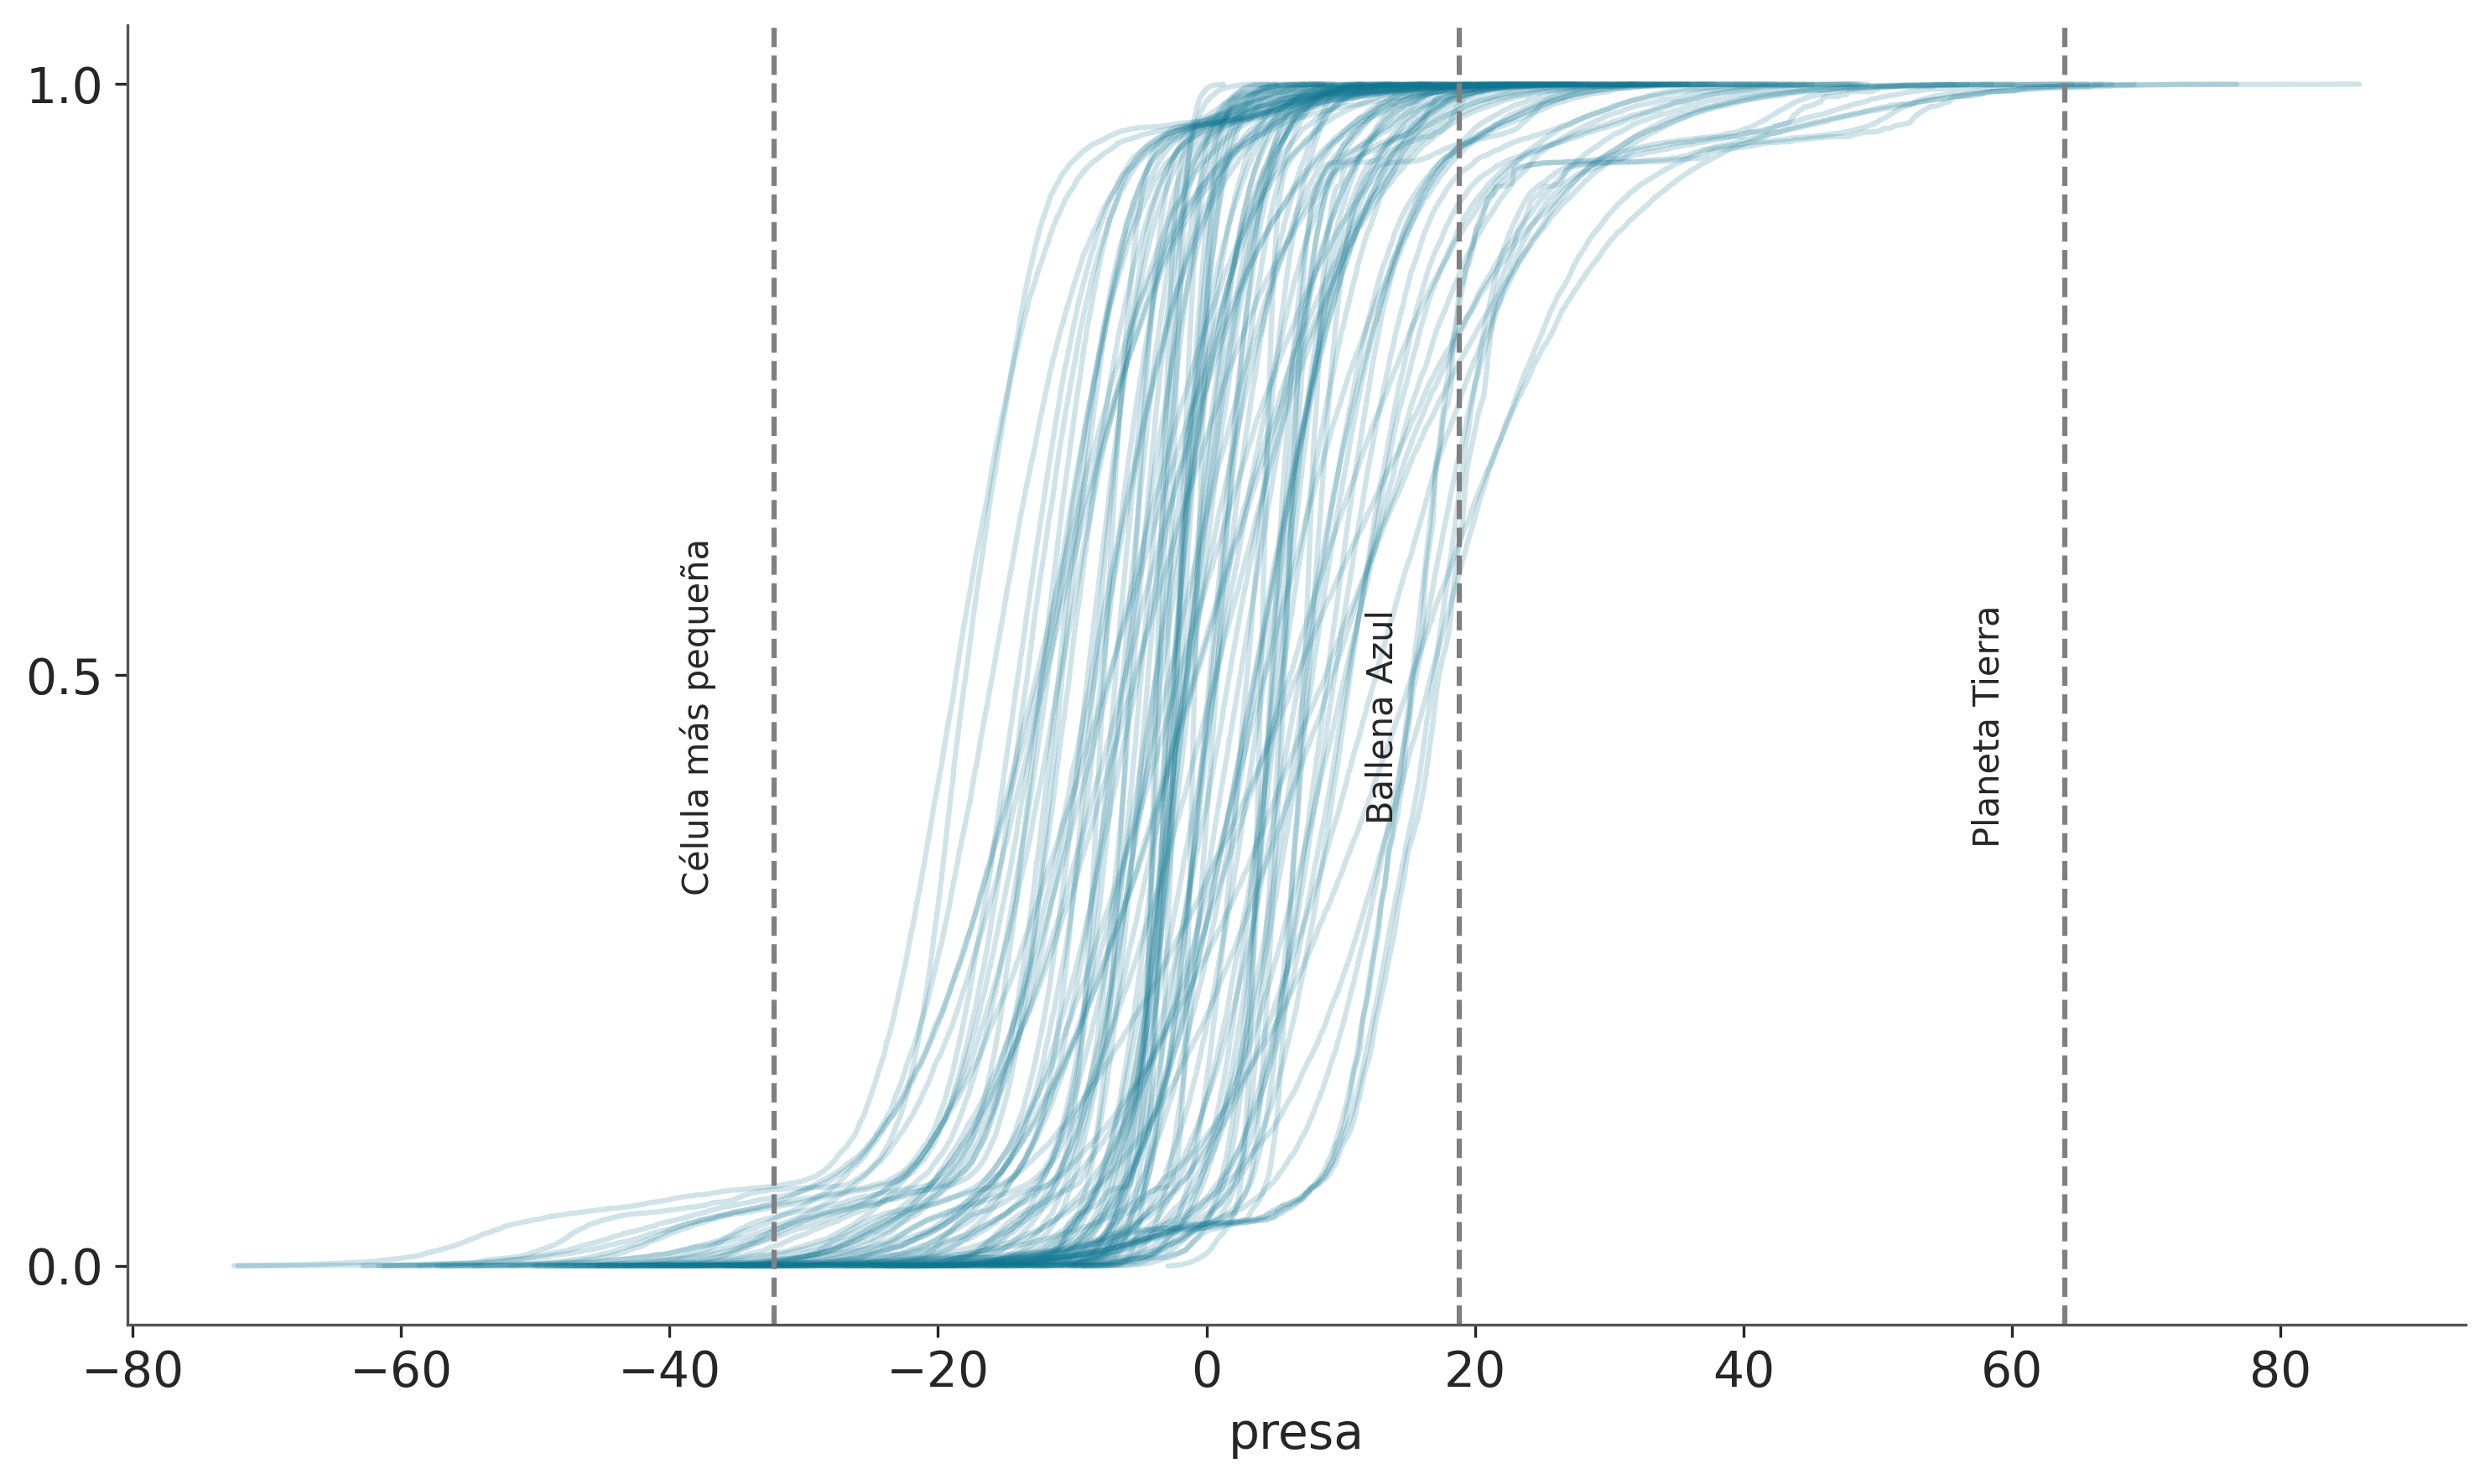

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))  # ancho x alto en pulgadas
az.plot_ppc(idata, group="prior", kind="cumulative", mean=False, legend=False, ax=ax)

for key, val in refs.items():
    ax.axvline(val, ls="--", color="0.5")
    ax.text(val-7, 0.5-(len(key)/100), key, rotation=90)

plt.tight_layout()
plt.show()

### <FONT COLOR="PINK"> **PASO B: predictivas a posteriori**

Se define como

$$
p(\tilde{y}  \mid  y) = \int p(\tilde{y} \mid \theta) p(\theta \mid y) d\theta
$$

donde $\tilde{y}$ representa nuevos datos generados a partir del modelo una vez actualizada la distribución de los parámetros con la información observada. A diferencia de la distribución predictiva a priori, aquí utilizamos la distribución a posteriori de $\theta$.

Para obtener muestras de esta distribución podemos seguir estos pasos:

Generamos un valor de $\theta$ a partir de $p(\theta \mid y)$.
Utilizamos ese valor en $p(\tilde{y} \mid \theta)$ y simulamos nuevos datos.
Repetimos el procedimiento tantas veces como sea necesario.

Las pruebas predictivas a posteriori son una herramienta muy utilizada para evaluar modelos bayesianos. En este caso, las simulaciones sí se comparan con los datos observados. Como el modelo fue ajustado utilizando esos datos, esta comparación permite verificar si es capaz de reproducir adecuadamente las principales características de la información observada.

Recordemos el ejemplo de los accidentes mineros entre los años 1851 y 1962, donde queríamos estudiar si la tasa de accidentes cambiaba significativamente luego de un cambio en las medidas de seguridad en las condiciones de trabajo.

Los datos eran los siguientes:

In [ ]:
accidentes = pd.Series([4, 5, 4, 0, 1, 4, 3, 4, 0, 6, 3, 3, 4, 0, 2, 6,
                       3, 3, 5, 4, 5, 3, 1, 4, 4, 1, 5, 5, 3, 4, 2, 5,
                       2, 2, 3, 4, 2, 1, 3, 2, 2, 1, 1, 1, 1, 3, 0, 0,
                       1, 0, 1, 1, 0, 0, 3, 1, 0, 3, 2, 2, 0, 1, 1, 1,
                       0, 1, 0, 1, 0, 0, 0, 2, 1, 0, 0, 0, 1, 1, 0, 2,
                       3, 3, 1, 1, 2, 1, 1, 1, 1, 2, 4, 2, 0, 0, 1, 4,
                       0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1])
años = np.arange(1851, 1962)

Nuestro modelo:

In [ ]:
with pm.Model() as modelo_cat:
    pc = pm.DiscreteUniform("pc", lower=años.min(), upper=años.max())

    t_0 = pm.Exponential("t_0", 1)
    t_1 = pm.Exponential("t_1", 1)

    tasa = pm.Deterministic("tasa", pm.math.switch(pc >= años, t_0, t_1))

    acc = pm.Poisson("acc", tasa, observed=accidentes)
    idata_cat = pm.sample(1000, random_seed=1791, progressbar=False)
    idata_cat.extend(pm.sample_posterior_predictive(idata_cat, progressbar=False))

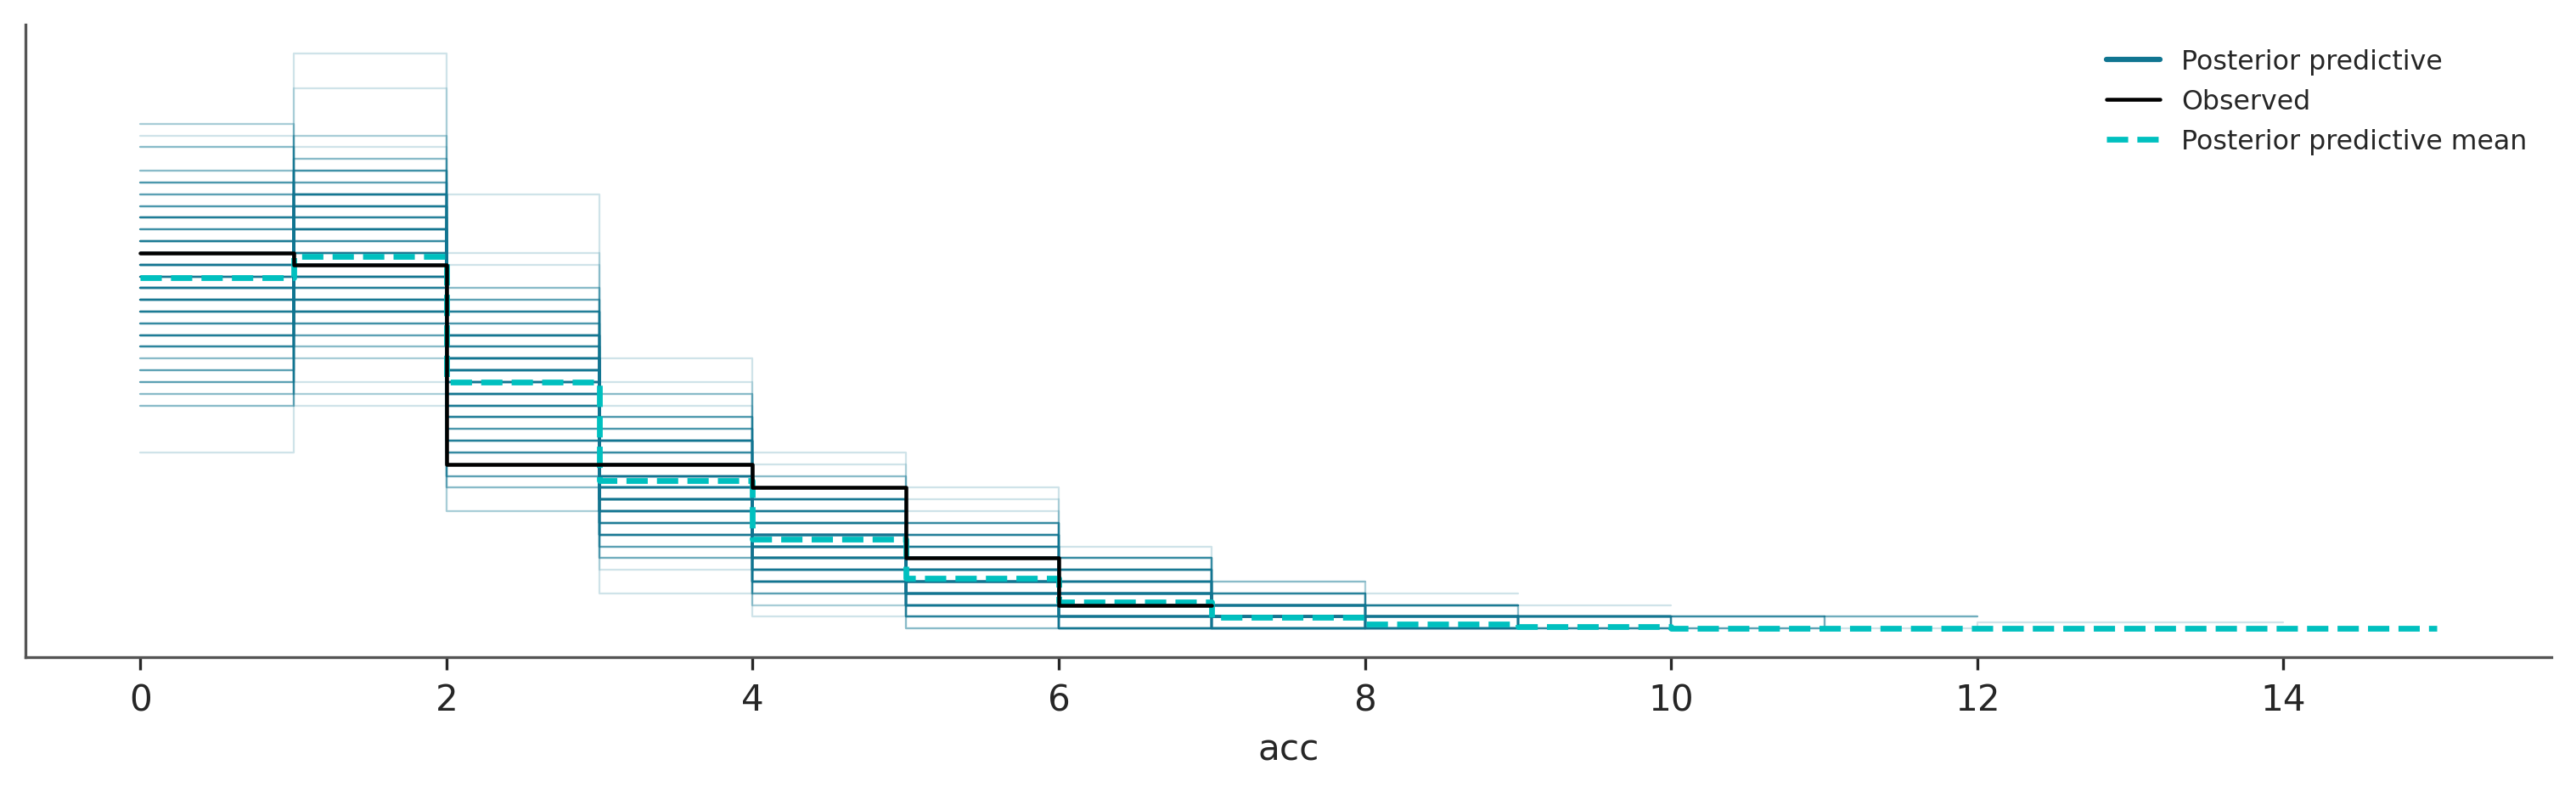

In [ ]:
ax = az.plot_ppc(idata_cat, figsize=(10, 3), num_pp_samples=200)
ax.set_xlabel("acc");

# **2. Comparación de modelos mediante técnicas bayesiana:**


### 2.1. Los valores de resumen:

Una estrategia para evaluar el ajuste de un modelo consiste en comparar alguna característica de los datos observados con la misma característica calculada sobre datos simulados por el modelo.

Se define entonces:

$$
\text{p-valorB } \triangleq p(T_{\text{sim}} \le T_{\text{obs}} \mid \tilde y)
$$


Aquí, $T$ representa un estadístico o medida resumen elegido para la comparación. Este puede ser, por ejemplo, la media, la mediana, la desviación estándar o cualquier otra cantidad relevante. $T_{\text{obs}}$ corresponde al valor calculado sobre los datos observados, mientras que $T_{\text{sim}}$ se obtiene a partir de los datos simulados.

Si el modelo reproduce razonablemente esa característica de los datos, el valor debería situarse cerca de $0,5$. En ese caso, aproximadamente la mitad de las simulaciones produce valores menores que el observado y la otra mitad, valores mayores.


<font color="pink"> **NOTA: la diferencia con $p-valor$ frecuentista es que no estamos utilizando una distribución muestral sino la distribución predictiva posterior, y no estamos haciendo una prueba de hipótesis nula ni tratando de declarar que una diferencia es “significativa”.**

Generemos gráficos de comparación predictiva a posteriori mediante Bayesian p-values (BPV) para el conjunto de datos categóricos *`idata_cat`*.

Estas comparaciones permiten evaluar si los datos simulados por el modelo son capaces de reproducir características relevantes de los datos observados. Para ello, se seleccionan distintos estadísticos resumen y se compara su valor observado con la distribución de valores obtenidos a partir de las simulaciones posteriores predictivas.

De esta manera, no evaluamos únicamente si el modelo reproduce los datos de forma general, sino también aspectos particulares de su distribución, como su tendencia central, dispersión o cualquier otra característica que resulte relevante para el problema.

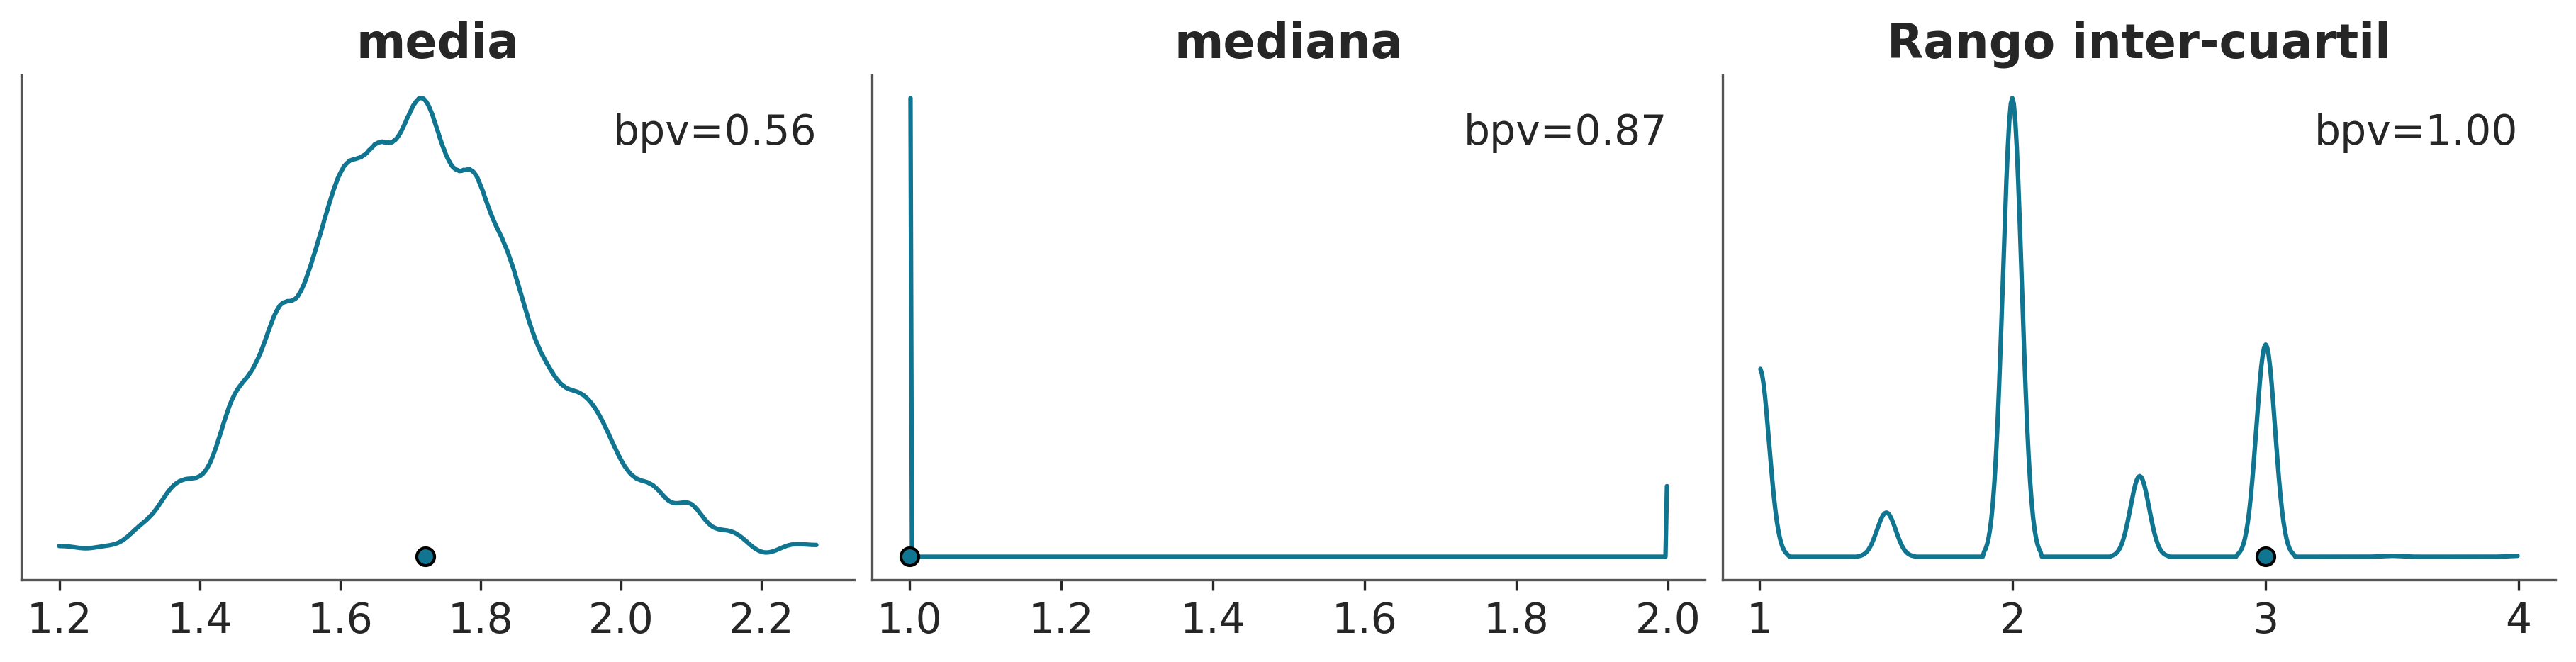

In [ ]:
_, ax = plt.subplots(1, 3, figsize=(12, 3))

def iqr(x, a=-1):
    """interquartile range"""
    return np.subtract(*np.percentile(x, [75, 25], axis=a))

az.plot_bpv(idata_cat, kind="t_stat", t_stat="mean", ax=ax[0])
az.plot_bpv(idata_cat, kind="t_stat", t_stat="median", ax=ax[1])
az.plot_bpv(idata_cat, kind="t_stat", t_stat=iqr, ax=ax[2])
ax[0].set_title("media")
ax[1].set_title("mediana")
ax[2].set_title("Rango inter-cuartil");

¿Qué observan?

Un caso especial se da al comparar si los valores simulados son menores que los observados, es decir

$$
p(\tilde y \le y_{\text{obs}} \mid y)
$$

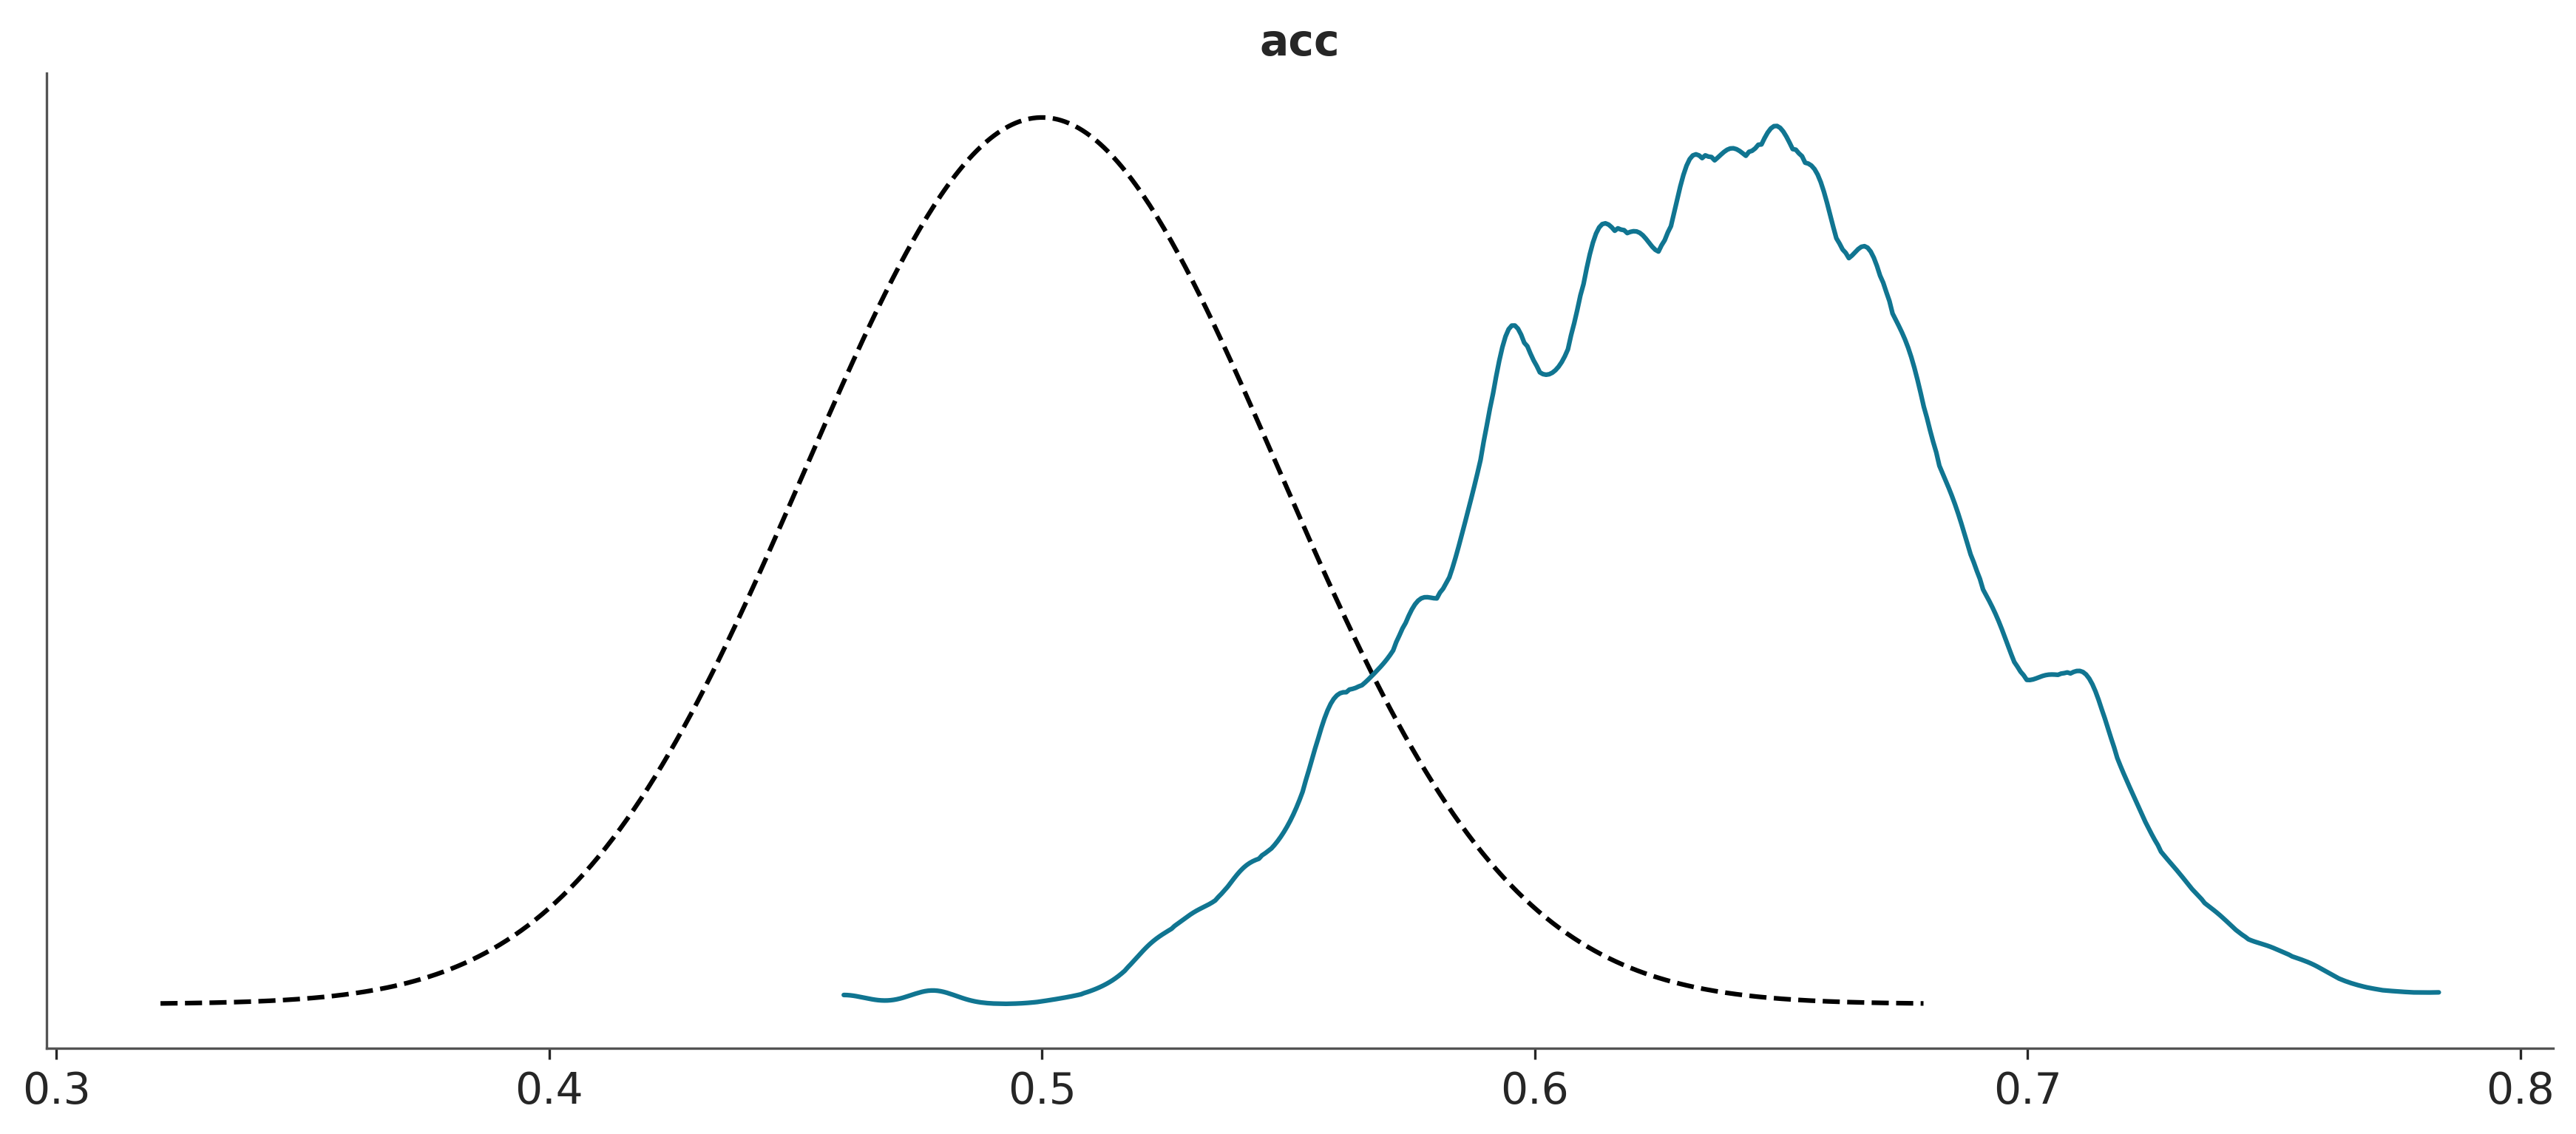

In [ ]:
az.plot_bpv(idata_cat, kind="p_value");

Otra alternativa consiste en realizar la comparación para cada observación individual. En este caso se considera:

$$
p(\tilde y_i \le y_i \mid y)
$$

Esta cantidad compara cada valor observado $y_i$ con las predicciones correspondientes generadas por el modelo. El resultado puede interpretarse como la posición relativa de la observación dentro de su distribución predictiva.

Estos valores suelen denominarse p-valores marginales. Si el modelo representa adecuadamente el mecanismo generador de los datos, esperamos que, en conjunto, estos valores se distribuyan aproximadamente como una uniforme estándar.

La línea blanca de la figura representa esta situación ideal, mientras que la banda gris muestra la variabilidad que puede esperarse simplemente debido al tamaño finito de la muestra. Por lo tanto, pequeñas desviaciones respecto de la línea no necesariamente indican un problema en el modelo.

Los valores del eje $x$ pueden interpretarse como cuantiles de la distribución. La región central permite evaluar el comportamiento del modelo en los valores más frecuentes, mientras que los extremos están relacionados con las colas. Desviaciones sistemáticas en determinadas zonas pueden indicar que el modelo reproduce bien algunas partes de la distribución, pero presenta dificultades en otras.

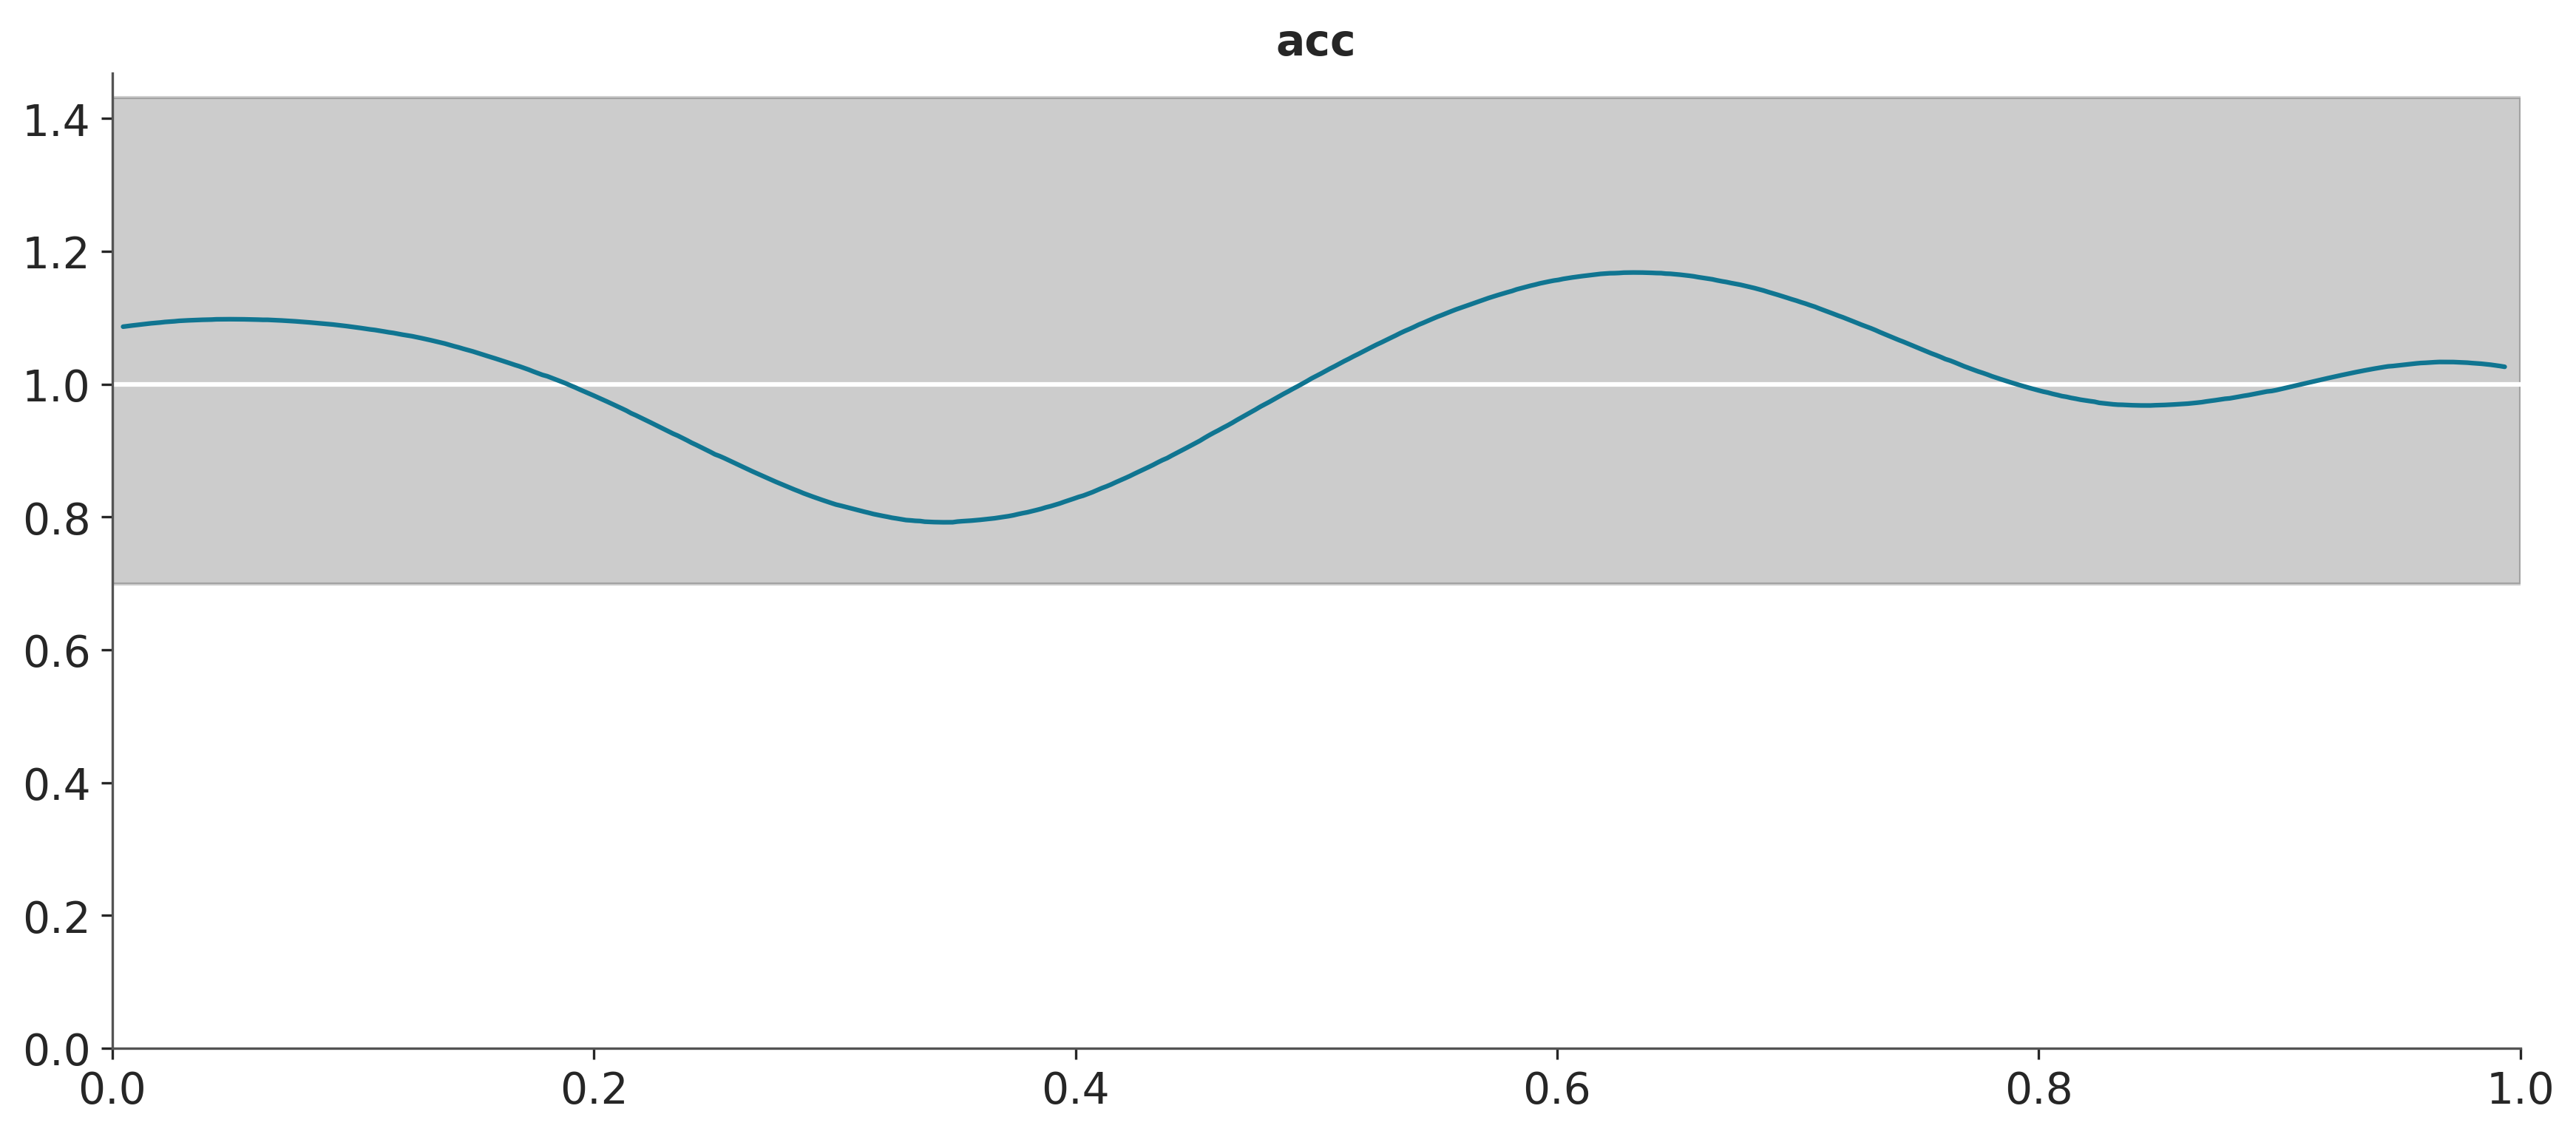

In [ ]:
az.plot_bpv(idata_cat);

¿Por qué esperamos observar una distribución uniforme? La respuesta se encuentra en una propiedad conocida como transformada integral de probabilidad (Probability Integral Transform, PIT).

Si $X$ es una variable aleatoria continua con función de distribución acumulada $F_X$, podemos definir:

$$
Y = F_X (X)
$$

Entonces, la nueva variable aleatoria cumple:

 $$Y \sim \mathcal{U}[0, 1]$$

Es decir, cuando una variable aleatoria continua se evalúa utilizando su propia función de distribución acumulada, el resultado se distribuye uniformemente entre 0 y 1.

Esta propiedad proporciona la intuición detrás de los p-valores marginales. Si las observaciones pueden considerarse compatibles con la distribución predictiva propuesta por el modelo, su posición relativa dentro de dicha distribución debería cubrir de manera aproximadamente uniforme todo el intervalo $[0,1]$.

Por el contrario, acumulaciones o desviaciones sistemáticas respecto de la uniforme pueden revelar discrepancias entre las predicciones del modelo y los datos observados. Empíricamente, podemos comprobar esta propiedad generando muestras de una distribución, aplicando su propia CDF y observando la distribución resultante.

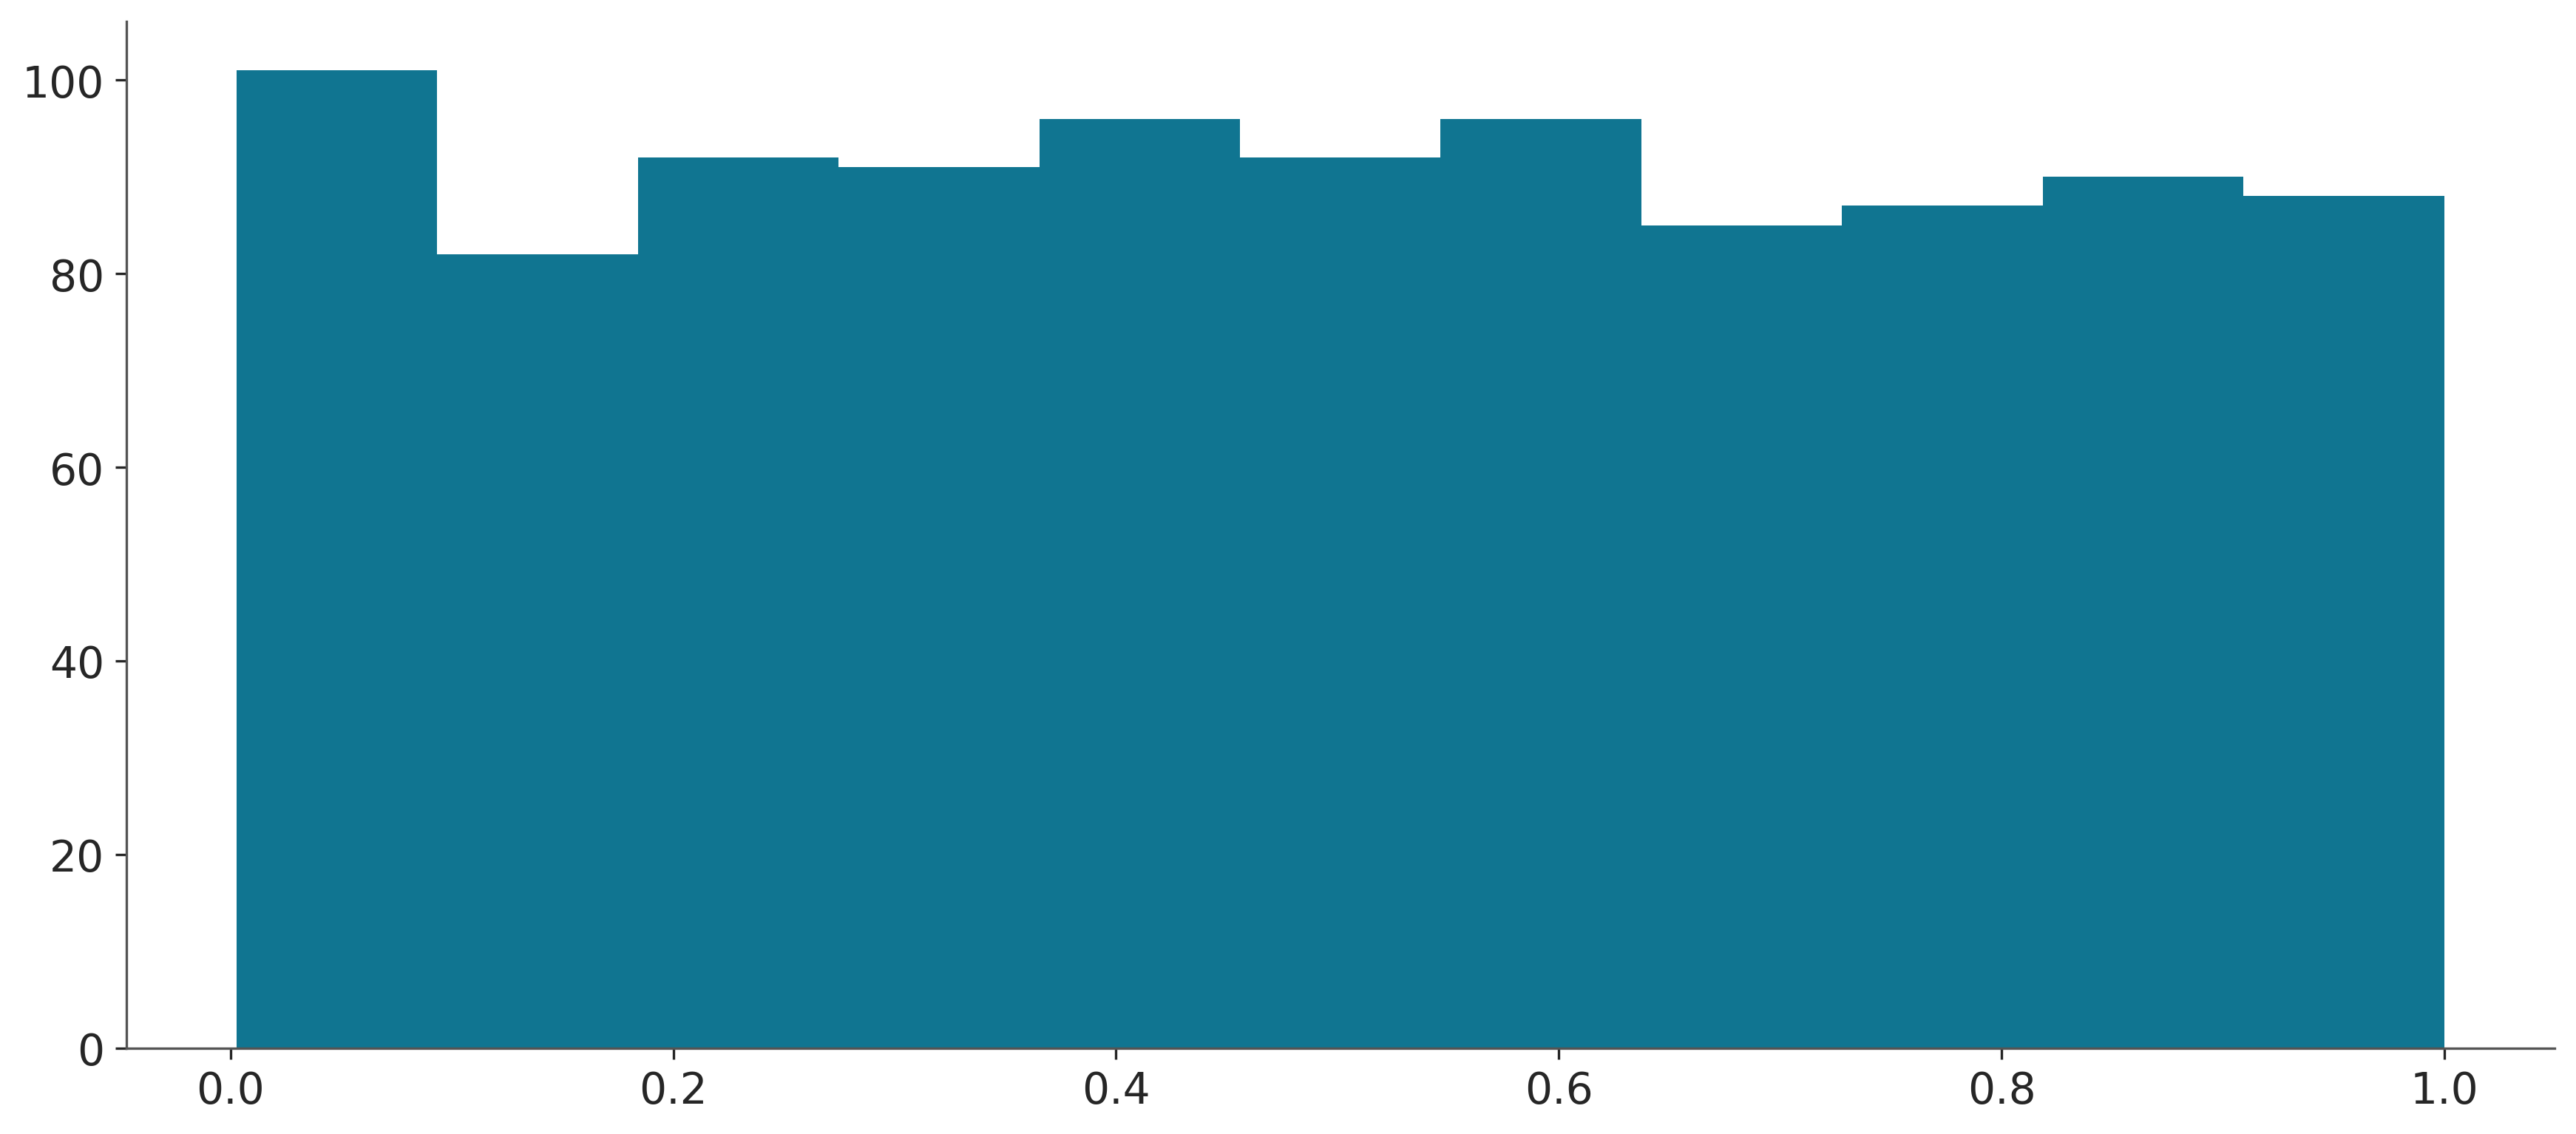

In [ ]:
dist = pz.Normal(0, 1)  # Probar con otras distribuciones
plt.hist(dist.cdf(dist.rvs(1000)), bins="auto");

Si desconocemos $F_X$, pero contamos con muestras de $X$, podemos usar la CDF empírica que es lo que estamos haciendo al calcular el valor-p marginal.


In [ ]:
dist = pz.Normal(0, 1)  # Probar con otras distribuciones
pred_f = np.exp(dist.rvs(1000))**0.3
obs_f = np.exp(dist.rvs(1000))**0.3

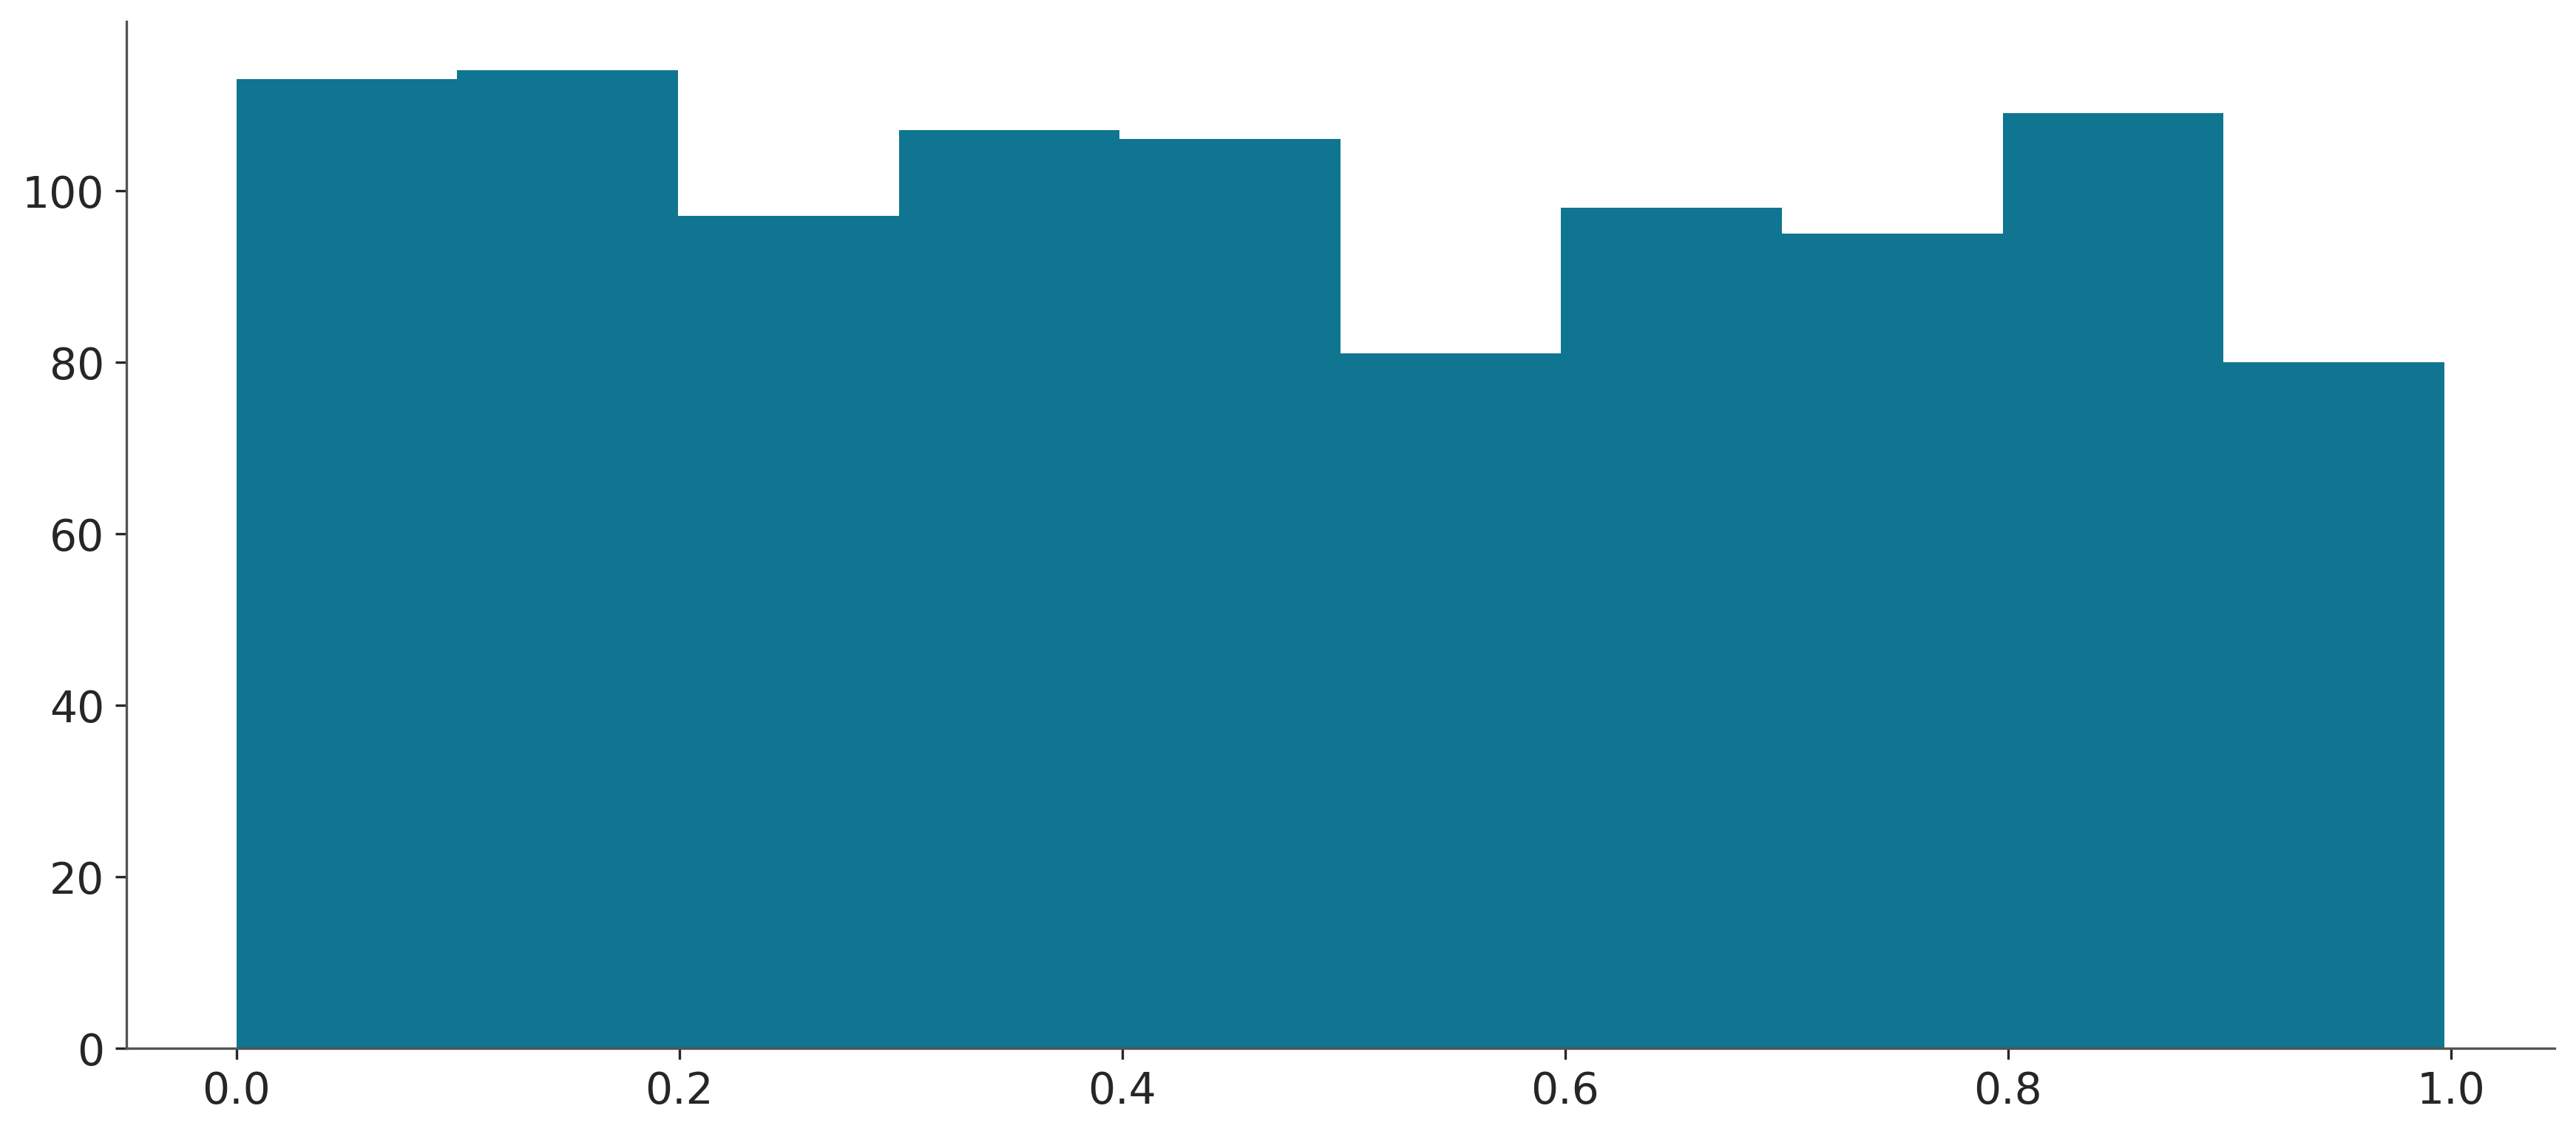

In [ ]:
pit = []
for m in obs_f:
    pit.append(np.mean(pred_f <= m))

plt.hist(pit);

### 2.2. **Comparación entre modelos:**

***El equilibrio entre simplicidad y capacidad predictiva:***

Al comparar modelos, no solo nos interesa qué tan bien se ajustan a los datos. También debemos considerar su complejidad. En general, preferimos modelos que expliquen adecuadamente la información disponible sin introducir parámetros o estructuras innecesarias.

Sin embargo, estos dos objetivos pueden entrar en conflicto. Un modelo más flexible puede adaptarse mejor a los datos utilizados para estimarlo, pero esa flexibilidad adicional no siempre se traduce en mejores predicciones. Por el contrario, un modelo demasiado simple puede ser incapaz de capturar patrones importantes.

Entonces surge una pregunta natural: ¿cómo podemos encontrar un equilibrio entre ajuste y complejidad?

Existen distintas herramientas para abordar este problema. Algunas se basan directamente en evaluar la capacidad predictiva del modelo y otras incorporan penalizaciones por complejidad. Antes de introducir estas medidas, resulta útil construir intuición mediante un ejemplo sencillo.

***Muchos parámetros pueden conducir al sobreajuste:***

Consideremos un conjunto de datos simple y ajustemos sobre él polinomios de complejidad creciente. A medida que aumenta el grado del polinomio, el modelo dispone de una mayor cantidad de parámetros y, por lo tanto, de una mayor capacidad para adaptarse a los datos.

Para simplificar el ejemplo, en lugar de utilizar un modelo bayesiano ajustaremos estos polinomios mediante mínimos cuadrados. Esto nos permitirá observar con claridad qué ocurre cuando incrementamos progresivamente la flexibilidad del modelo.

La intuición es sencilla: un modelo con pocos parámetros tiene una capacidad limitada para representar patrones complejos, mientras que uno muy flexible puede llegar a adaptarse prácticamente a cualquier conjunto de puntos. Sin embargo, como veremos, un ajuste perfecto sobre los datos disponibles no garantiza necesariamente un buen desempeño al enfrentarse a nuevos datos.

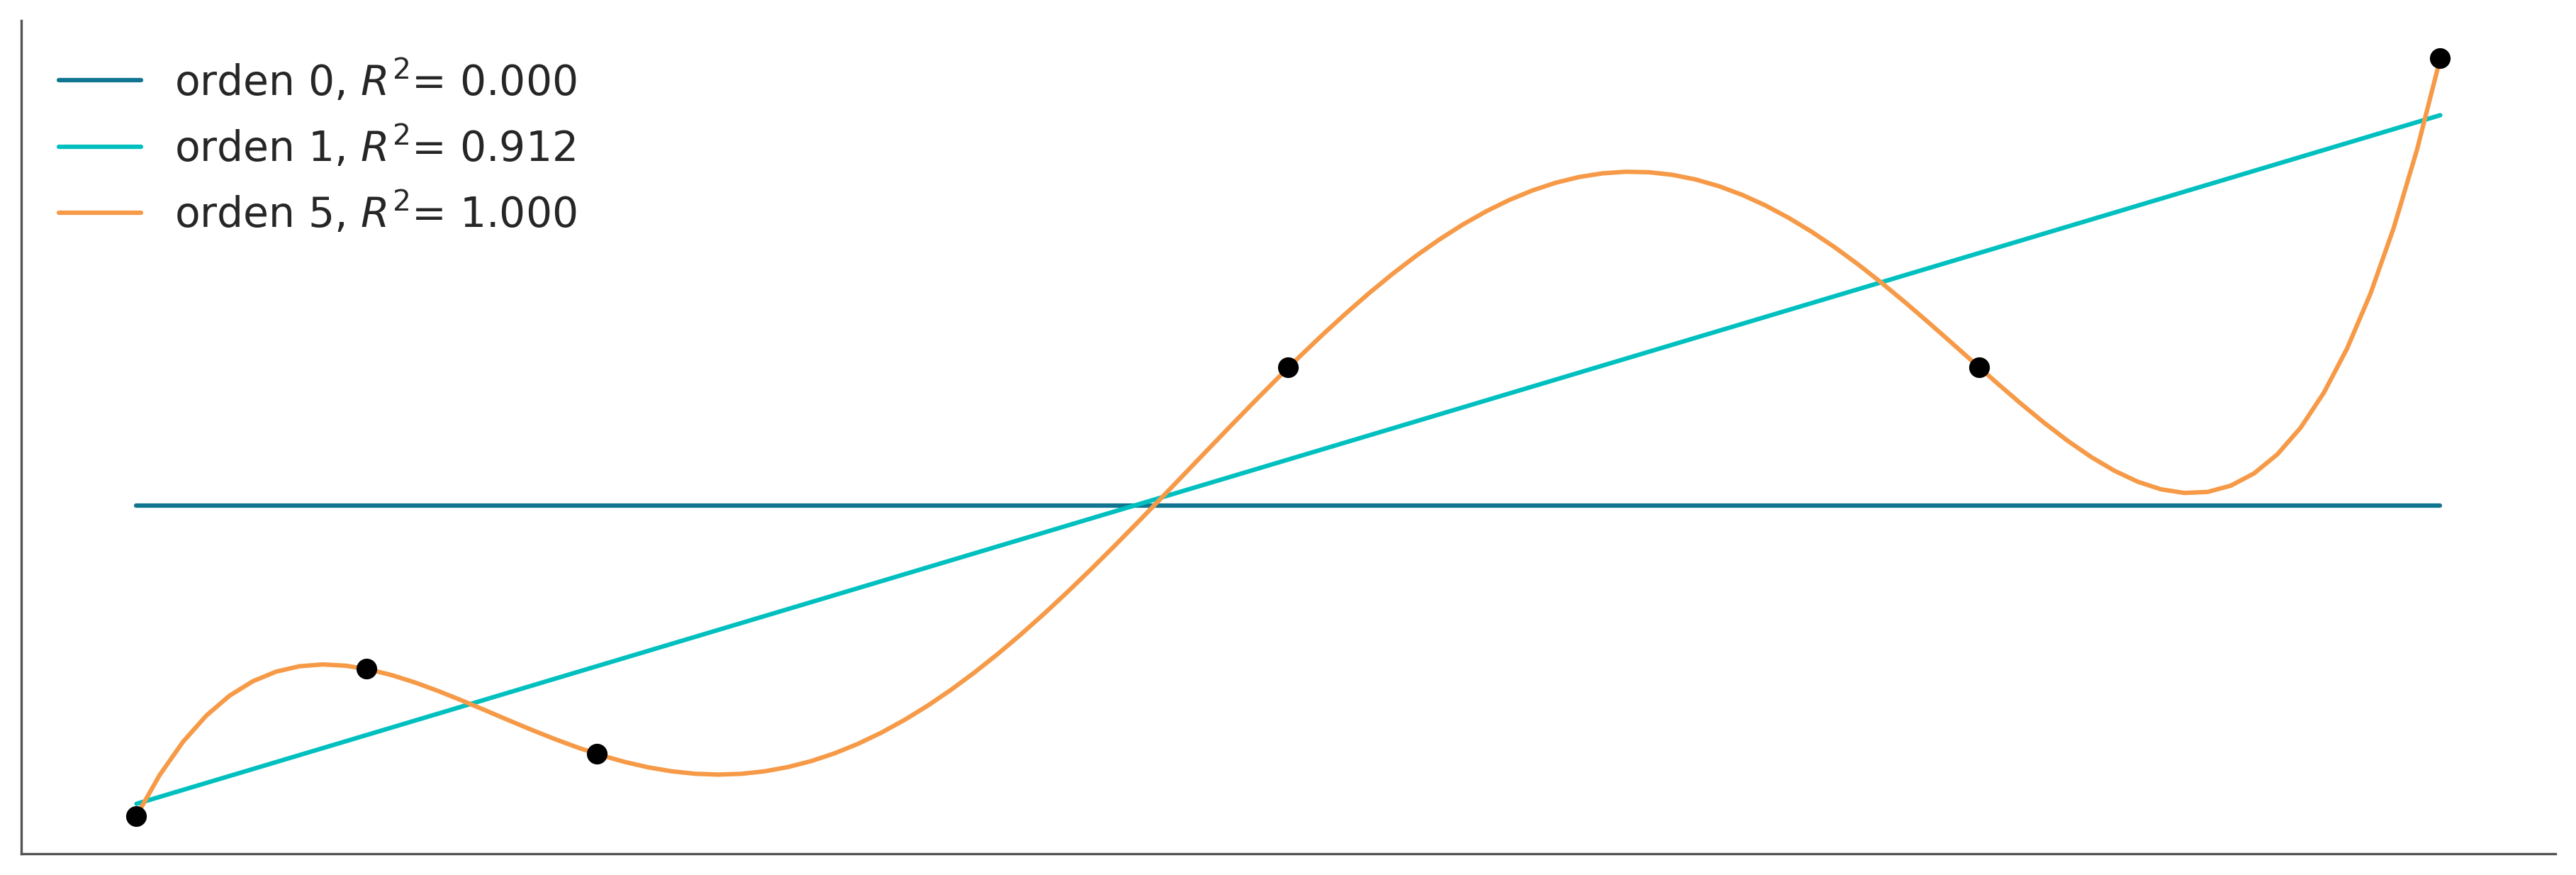

In [ ]:
#| code-fold: true

_, ax = plt.subplots(1, 1, figsize=(12, 4))


x0 = np.array([4., 5., 6., 9., 12, 14.])
y0 = np.array([4.2, 6.1, 5., 10., 10, 14.])

order = [0, 1, 5]
ax.plot(x0, y0, 'ko', zorder=3)


ax.set_yticks([])
ax.set_xticks([])

x_n = np.linspace(x0.min(), x0.max(), 100)
ps = []
for i in order:
    p = np.polynomial.Polynomial.fit(x0, y0, deg=i)
    ps.append(p)
    yhat = p(x0)
    ybar = np.mean(y0)
    ss_regression = np.sum((yhat-y0)**2)
    ss_total = np.sum((ybar-y0)**2)
    r2 = 1 - ss_regression / ss_total
    ax.plot(x_n, p(x_n), label=f'orden {i}, $R^2$= {r2:.3f}')


ax.legend(loc=2);

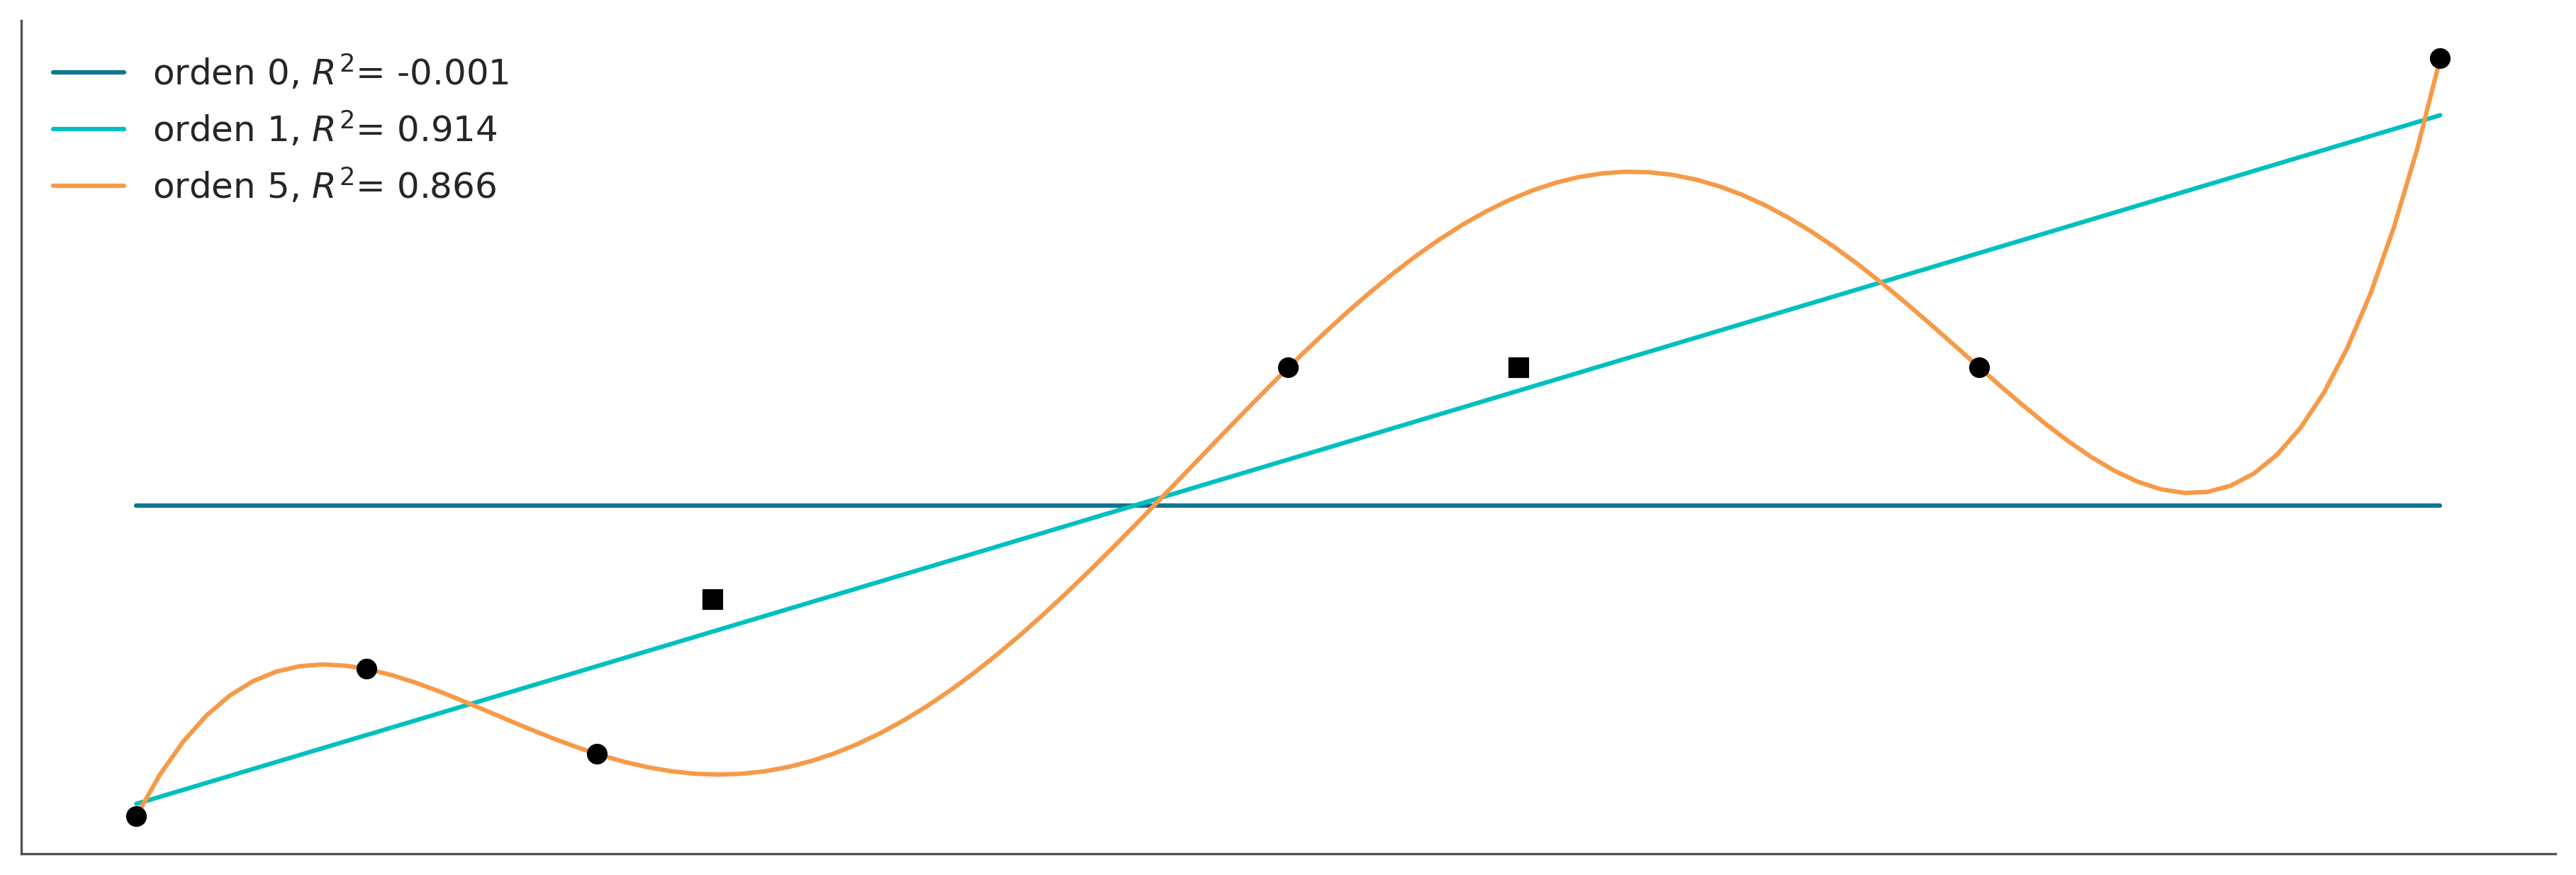

In [ ]:
#| code-fold: true

_, ax = plt.subplots( figsize=(12, 4))
x_ = np.array([6.5, 10])
y_ = np.array([7, 10])

ax.plot(x0, y0, 'ko', zorder=3)
ax.plot(x_, y_, 'ks', zorder=3)

ax.set_yticks([])
ax.set_xticks([])

x1 = np.concatenate((x0, x_))
y1 = np.concatenate((y0, y_))

for idx, i in enumerate(order):
    yhat = ps[idx](x1)
    ybar = np.mean(y1)
    ss_regression = np.sum((yhat-y1)**2)
    ss_total = np.sum((ybar-y1)**2)
    r2 = 1 - ss_regression / ss_total
    ax.plot(x_n, ps[idx](x_n), label=f'orden {i}, $R^2$= {r2:.3f}')


ax.legend(loc=2, fontsize=12);

A medida que aumenta la complejidad del polinomio, también mejora su capacidad para ajustarse a los datos utilizados durante la estimación. Esto puede observarse, por ejemplo, en el coeficiente de determinación $R^2$. En el extremo, el polinomio de grado 5 logra un ajuste perfecto, con $R^2=1$.

Sin embargo, este resultado no significa necesariamente que se trate del mejor modelo. En este ejemplo, el número de parámetros disponibles es suficiente para reproducir exactamente los seis puntos observados. En lugar de identificar únicamente el patrón subyacente, el modelo tiene la capacidad de adaptarse también a las particularidades de esta muestra.

Podemos pensar que los datos contienen, al menos conceptualmente, dos componentes: señal y ruido. La señal representa los patrones que nos interesa aprender y que esperamos que también se mantengan en futuras observaciones. El ruido, en cambio, incluye variaciones aleatorias, errores de medición u otras particularidades propias de los datos observados.

Un modelo demasiado flexible puede terminar ajustando ambos componentes. Cuando esto ocurre, puede alcanzar una excelente exactitud sobre los datos utilizados para estimarlo, pero perder capacidad para generalizar.

Esto se hace evidente al incorporar nuevas observaciones y evaluar los modelos sin volver a ajustarlos. El modelo que parecía superior dentro de la muestra no necesariamente mantiene ese desempeño sobre datos nuevos. En este caso, un modelo más simple puede realizar mejores predicciones que el polinomio de mayor grado.

A este fenómeno lo denominamos <font color="violet"> *sobreajuste (overfitting):*</font> el modelo se adapta excesivamente a los datos de entrenamiento y, como consecuencia, presenta un desempeño inferior al enfrentarse a nueva información.

Esta situación ilustra una idea relacionada con la navaja de Occam (puedne buscarla como actividad): no conviene agregar complejidad si esta no aporta una mejora real en nuestra capacidad para describir o predecir el fenómeno. Siempre es posible construir modelos cada vez más flexibles, pero un modelo capaz de reproducir cada detalle de una muestra puede terminar representando incluso aspectos accidentales que no volverán a aparecer.

***Muy pocos parámetros también pueden ser un problema:***

El extremo opuesto es el <font color="violet">*subajuste (underfitting)*</font>. Si consideramos un modelo polinomial de grado 0, el modelo únicamente estima un valor constante. En términos prácticos, intenta representar todos los valores de $y$ mediante su media y no utiliza ninguna información proporcionada por $x$.

Este modelo es demasiado simple para capturar la relación presente en los datos. Aunque evita el problema de memorizar particularidades de la muestra, su falta de flexibilidad le impide aprender patrones relevantes.

Por lo tanto, tanto un modelo excesivamente complejo como uno demasiado simple pueden producir resultados poco satisfactorios. El objetivo es encontrar un nivel de complejidad que permita capturar la señal sin ajustar innecesariamente el ruido.

***Medidas de exactitud predictiva:***

Idealmente, buscamos modelos que logren un buen equilibrio entre simplicidad y capacidad predictiva. En el ejemplo anterior resulta relativamente sencillo identificar los extremos: el modelo de grado 0 es demasiado restrictivo, mientras que el de grado 5 es excesivamente flexible. Sin embargo, comparar los modelos intermedios requiere un criterio más formal.

***Para ello resulta útil distinguir dos conceptos:***

Exactitud dentro de la muestra (within-sample accuracy): se evalúa utilizando los mismos datos empleados para ajustar el modelo.
Exactitud fuera de la muestra (out-of-sample accuracy): se evalúa utilizando datos que no participaron en el ajuste.

La primera suele ser optimista. Como el modelo fue construido utilizando esos datos, es esperable que su desempeño sobre ellos sea mejor que sobre observaciones nuevas. Por esta razón, un modelo con excelente ajuste dentro de la muestra no necesariamente tendrá una buena capacidad predictiva.

La evaluación fuera de la muestra proporciona una idea más realista de qué tan bien puede generalizar el modelo. El problema es que requiere disponer de datos que no se utilicen durante el ajuste, algo que puede resultar costoso cuando contamos con muestras pequeñas.

Para abordar este problema existen distintas estrategias. Dos de las más utilizadas son:

---> Validación cruzada, que divide o reutiliza los datos disponibles para alternar entre las etapas de ajuste y evaluación.

---> Criterios de información, que buscan aproximar la capacidad predictiva fuera de la muestra a partir de la información obtenida durante el ajuste y una penalización asociada a la complejidad efectiva del modelo.

Así, la comparación entre modelos deja de centrarse únicamente en cuál reproduce mejor los datos observados y pasa a considerar una pregunta más importante:

<font color="pink"> **¿Cuál esperamos que funcione mejor frente a datos nuevos?**

# **3. Criterios de información**


Los criterios de información son herramientas diseñadas para comparar distintos modelos teniendo en cuenta algo más que su capacidad para reproducir los datos observados. La idea central es evaluar qué tan bien esperamos que un modelo represente o prediga nuevos datos, considerando al mismo tiempo la complejidad de la estructura utilizada.

Estos criterios están relacionados con conceptos provenientes de la Teoría de la Información, que proporciona un marco probabilístico para cuantificar diferencias entre distribuciones y evaluar la cantidad de información que aporta un modelo.

Para construir intuición, podemos comenzar con una medida de error conocida. Supongamos que disponemos de observaciones $y_i$ y de las correspondientes predicciones generadas por el modelo. Una forma habitual de resumir las diferencias entre ambas cantidades es mediante el error cuadrático medio:
$$
\frac{1}{N} \sum_i^N  (y_i - \operatorname{E} (y_i \mid \theta))^2
$$

En esta expresión, $\operatorname{E} (y_i \mid \theta)$ representa el valor esperado o predicción del modelo para la observación $i$, una vez fijados los parámetros $\theta$. La cantidad resultante resume, en promedio, qué tan alejadas se encuentran las predicciones de los valores realmente observados.

El uso del cuadrado tiene dos consecuencias importantes: evita que errores positivos y negativos se compensen entre sí y asigna una penalización mayor a las discrepancias grandes. Por este motivo, unos pocos errores muy grandes pueden tener una influencia considerable sobre el valor final.

Sin embargo, aunque esta medida resulta familiar y ampliamente utilizada, no existe una razón única por la cual debamos utilizar precisamente el error cuadrático. Podríamos definir muchas otras formas de cuantificar la discrepancia entre observaciones y predicciones.

En nuestro caso, nos interesa avanzar hacia una medida que surja naturalmente del enfoque probabilístico. En lugar de evaluar únicamente la distancia entre un dato observado y un valor predicho, queremos aprovechar toda la información contenida en las distribuciones de probabilidad propuestas por el modelo. Esta idea nos llevará a los conceptos que fundamentan los criterios de información.

## 3.1. Validación cruzada

La validación cruzada es una estrategia para estimar cómo se comportaría un modelo frente a datos que no participaron en su ajuste. La idea consiste en reservar temporalmente una parte de la información disponible para utilizarla como conjunto de evaluación.

En la versión conocida como validación cruzada K-fold, los datos se dividen en $K$ subconjuntos, procurando, cuando sea posible, que tengan tamaños similares y que mantengan características importantes de los datos originales.

En cada iteración, uno de estos subconjuntos se deja fuera y se utiliza para evaluar el modelo. Los $K-1$ subconjuntos restantes se emplean para realizar el ajuste. Posteriormente se repite el procedimiento, cambiando el subconjunto reservado, hasta que cada una de las $K$ partes haya sido utilizada una vez para evaluar el modelo.

De esta manera obtenemos $K$ medidas de desempeño. Estas pueden combinarse, por ejemplo mediante un promedio, para obtener una estimación global de la capacidad predictiva del modelo sobre datos no utilizados durante su ajuste.

Una vez finalizada la evaluación y seleccionada una alternativa, es habitual volver a ajustar el modelo elegido utilizando nuevamente la totalidad de los datos disponibles.

Un caso particular aparece cuando elegimos:

$$K=N$$

Es decir, cuando cada subconjunto contiene una única observación. En ese caso, en cada iteración se ajusta el modelo utilizando todos los datos excepto uno y se evalúa su capacidad para predecir la observación que quedó fuera. Este procedimiento recibe el nombre de leave-one-out cross-validation, o simplemente **LOOCV**.

La validación cruzada es una herramienta muy utilizada porque proporciona una aproximación directa a la exactitud predictiva fuera de la muestra. Sin embargo, tiene un costo: debemos ajustar el modelo varias veces. Dependiendo del valor de $K$, del tamaño de los datos y de la complejidad del modelo, este procedimiento puede resultar computacionalmente costoso.

Esto es especialmente importante en modelos bayesianos, donde cada ajuste puede requerir procesos de muestreo relativamente intensivos. Por esta razón, se han desarrollado diferentes aproximaciones que buscan estimar el desempeño predictivo fuera de la muestra sin tener que repetir completamente el ajuste en cada partición.

Los criterios de información constituyen precisamente una familia de herramientas que persigue este objetivo: obtener medidas de comparación que aproximen la capacidad predictiva de los modelos de una manera más eficiente.

## 3.2. Concepto de Entropía

Para introducir algunos de estos criterios necesitamos primero presentar un concepto fundamental de la Teoría de la Información: la entropía.

Consideremos una distribución de probabilidad con $N$ resultados posibles y probabilidades $p_i$. La entropía de esta distribución se define como:

$$
H(p) = - \mathbb{E}[\log{p}] = -\sum_i^N p_i \log{p_i}
$$

De manera intuitiva, la entropía cuantifica el grado de incertidumbre asociado a una distribución. Cuando conocemos con certeza cuál será el resultado de un experimento, no existe incertidumbre: uno de los eventos tiene probabilidad uno y los demás probabilidad cero. En esa situación, la entropía alcanza su valor mínimo, igual a cero.

En cambio, la incertidumbre aumenta cuando resulta más difícil anticipar cuál será el resultado. Por ejemplo, si todos los eventos posibles tienen la misma probabilidad, ninguno es más predecible que otro y la entropía alcanza su valor máximo.

Por lo tanto, la entropía no mide simplemente cuántos resultados son posibles, sino también cómo se distribuye la probabilidad entre ellos. Una distribución concentrada en unos pocos eventos contiene menos incertidumbre que otra en la que la probabilidad se encuentra repartida de manera más uniforme.

Aunque aquí presentamos el concepto para un número finito de eventos, existen extensiones análogas para variables y distribuciones continuas. Por el momento, nos quedaremos con esta interpretación intuitiva, que será suficiente para entender cómo la Teoría de la Información permite construir medidas útiles para comparar modelos.

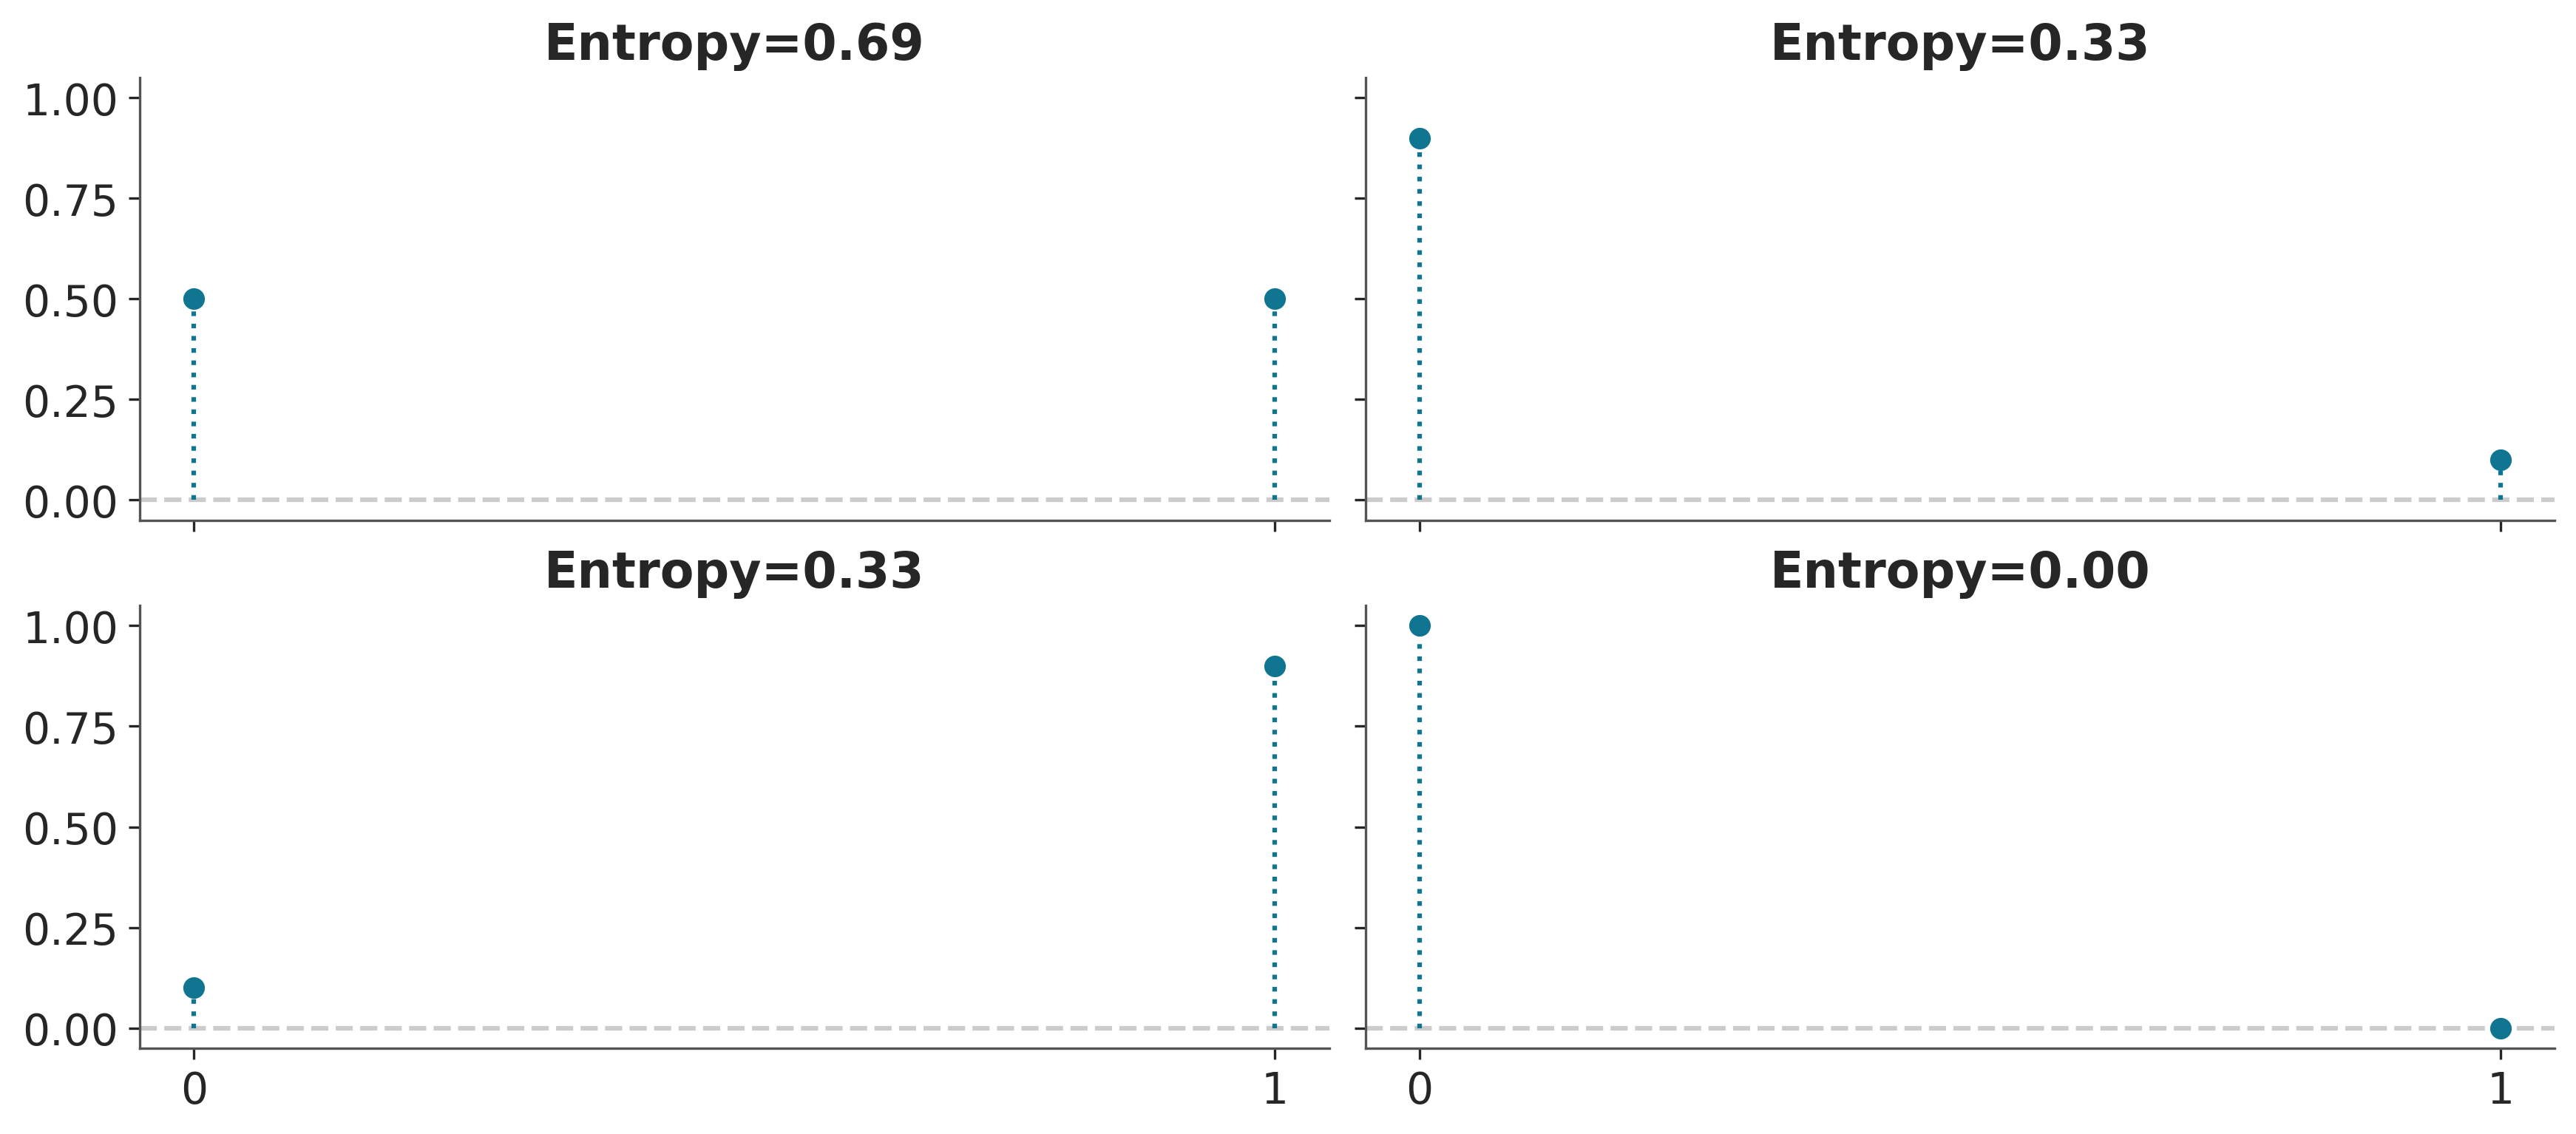

In [ ]:
_, axes = plt.subplots(2, 2, sharex=True, sharey=True)

for p, ax in zip([0.5, 0.1, 0.9, 0.0001], axes.ravel()):
    dist = pz.Bernoulli(p=p)
    dist.plot_pdf(ax=ax, legend=False)
    ax.set_title(f"Entropy={dist.entropy():.2f}")
    ax.set_ylim(-0.05, 1.05)

La entropía es un concepto que aparece en distintos contextos dentro de la estadística. Por ejemplo, puede utilizarse al momento de construir distribuciones a priori. En ese caso, una posible estrategia consiste en buscar, entre las distribuciones compatibles con la información disponible, aquella que posea la mayor entropía posible. Herramientas como maxent de PreliZ permiten trabajar con esta idea. La entropía también cumple un papel importante en la comparación de modelos.

Para avanzar en esta dirección, supongamos que existe una distribución objetivo $q$ que nos interesa representar, pero que no conocemos o con la que no podemos trabajar directamente. Disponemos, en cambio, de otra distribución $p$ y queremos determinar qué tan bien logra aproximar a $q$. Si $p$ pertenece a una familia paramétrica, el problema puede plantearse como la búsqueda de los valores de sus parámetros que produzcan la aproximación más cercana a la distribución objetivo.

Una forma de cuantificar esta diferencia es mediante la divergencia de Kullback-Leibler:

$$
\mathbb{KL}(q \parallel p) =  \overbrace{-\sum_i^N q_i \log{p_i}}^{H(q, p)} -  \overbrace{\left(-\sum_{i}^N q_i \log{q_i}\right)}^{H(q)}
$$

Esta expresión puede interpretarse a partir de dos cantidades. Por un lado aparece la entropía de la distribución objetivo, $H(q)$, y por otro la entropía cruzada $H(q,p)$, que evalúa el costo de utilizar $p$ cuando los datos siguen la distribución $q$.

Aunque esta interpretación puede parecer algo abstracta, la situación es muy cercana a la que encontramos habitualmente al construir modelos estadísticos. Podemos imaginar que observamos $N$ datos generados por algún mecanismo desconocido, representado por $q$, y que proponemos un modelo probabilístico $p(y \mid \theta)$ para aproximarlo. En ese contexto, la divergencia de Kullback-Leibler nos proporciona una forma de medir la discrepancia entre el mecanismo que genera los datos y el modelo que utilizamos para describirlo.

Desde esta perspectiva, la divergencia de KL puede entenderse como la cantidad de información adicional que se pierde o se introduce al reemplazar $q$ por $p$. La misma cantidad puede escribirse de diferentes maneras equivalentes, según cuál resulte más conveniente para el problema que estamos considerando:

$$
\mathbb{KL}(q \parallel p) \quad=\quad- \sum_i^N q_i (\log{p_i} - \log{q_i}) \quad=\quad \mathbb{E}_q[\log{q}] - \mathbb{E}_q[\log{p}] \quad=\quad \sum_i^N q_i \log{\frac{q_i}{p_i}}
$$


Aunque estas expresiones tengan formas diferentes, todas describen la misma noción de discrepancia entre distribuciones. Sin embargo, aparece una dificultad importante: en los problemas reales normalmente no conocemos $q$. Esta distribución podría representar, por ejemplo, el proceso generador de los datos, la población o la denominada distribución verdadera, cantidades a las que en general no tenemos acceso directo.

A primera vista, esto parecería impedirnos utilizar la divergencia de KL. Sin embargo, cuando nuestro objetivo es comparar modelos, no necesitamos conocer todos sus términos de manera explícita. La razón es que la entropía asociada a $q$ permanece constante independientemente del modelo que estemos evaluando.

Podemos representar esta idea al comparar distintos modelos mediante:

$$
\begin{split}
        \mathbb{KL}(q \parallel p_0) =&\; \mathbb{E}[\log{q}] - \mathbb{E}[\log{p(Y \mid \theta_0)}] \\
        \mathbb{KL}(q \parallel p_1) =&\; \mathbb{E}[\log{q}] - \mathbb{E}[\log{p(Y \mid \theta_1)}] \\
        &\cdots \\
        \mathbb{KL}(q \parallel p_m) =&\; \mathbb{E}[\log{q}] - \mathbb{E}[\log{p(Y \mid \theta_m)}]
\end{split}
$$

Como el término asociado a $q$ es el mismo para todas las alternativas, las diferencias entre modelos dependen únicamente de qué tan bien cada uno logra asignar probabilidad a los datos. Por lo tanto, dentro del conjunto de modelos considerados, minimizar la divergencia de Kullback-Leibler equivale a maximizar el término correspondiente al modelo probabilístico.

En otras palabras, podemos comparar modelos sin conocer exactamente cuál es la distribución verdadera que generó los datos.

En la práctica surge todavía otro problema: tampoco conocemos directamente la cantidad $\mathbb{E}[\log{p}]$. Podemos intentar estimarla utilizando los datos disponibles, pero aquí reaparece una dificultad que ya hemos visto. Si utilizamos la misma muestra tanto para ajustar un modelo como para evaluar su desempeño, obtenemos una estimación optimista de su capacidad predictiva.

Por lo tanto, necesitamos algún mecanismo que permita corregir este sesgo. Los criterios de información surgen precisamente como una forma de aproximar la capacidad predictiva de un modelo incorporando una corrección por el hecho de haber utilizado los mismos datos durante el proceso de ajuste y evaluación.

## 3.3. Criterio de información de Akaike

El criterio de información de Akaike, o AIC, es una de las medidas más utilizadas para comparar modelos. Su objetivo es combinar, en una única cantidad, la calidad del ajuste y una penalización asociada con la complejidad del modelo.

Se define como:

$$
AIC = -2 \sum_i^N \log p(y_i \mid \hat{\theta}_{mle}) + 2 k
$$

En esta expresión, $k$ representa el número de parámetros del modelo y $\hat{\theta}_{mle}$ corresponde a la estimación de máxima verosimilitud de $\theta$.

Para facilitar la comparación con los criterios que introduciremos más adelante, omitiremos la constante $-2$ y escribiremos:

$$
AIC = \sum_i^N \log p(y_i \mid \hat{\theta}_{mle}) - k
$$

Esta forma permite identificar con mayor claridad los dos componentes principales del criterio. El primer término está relacionado con la capacidad del modelo para explicar los datos: valores de mayor verosimilitud indican un mejor ajuste. El segundo término introduce una penalización que aumenta con el número de parámetros.

La intuición detrás de esta corrección resulta razonable. En general, al incorporar más parámetros, un modelo adquiere mayor capacidad para adaptarse a los datos. Sin embargo, una mayor flexibilidad también aumenta el riesgo de sobreajuste. Por este motivo, el AIC no evalúa únicamente qué tan bien ajusta un modelo, sino que busca compensar esa ventaja penalizando la complejidad adicional.

De todos modos, esta penalización no es simplemente una elección arbitraria basada en la intuición. El término $k$ surge de una derivación teórica vinculada con la aproximación de la divergencia de Kullback-Leibler.

Aunque el AIC resulta muy útil en numerosos contextos, presenta algunas limitaciones desde una perspectiva bayesiana. Una de las principales es que resume toda la incertidumbre sobre $\theta$ mediante una única estimación puntual, $\hat{\theta}_{mle}$. De esta manera, no utiliza directamente la distribución a posteriori.

Además, el AIC no incorpora de manera explícita la información contenida en los priors. Esto puede resultar especialmente problemático cuando utilizamos distribuciones a priori informativas o ligeramente informativas. En estos casos, la complejidad efectiva de un modelo no necesariamente coincide con su número nominal de parámetros.

Por ejemplo, un prior puede restringir considerablemente los valores plausibles de un parámetro. De manera similar, las estructuras jerárquicas permiten compartir información entre diferentes componentes del modelo. En ambos casos, el modelo puede contener muchos parámetros, pero su flexibilidad efectiva ser menor que la sugerida por su simple conteo. Este efecto está relacionado con la idea de regularización y con el concepto de número efectivo de parámetros.

Esto nos lleva a una pregunta natural:

<font color="pink"> **¿podemos construir un criterio similar al AIC, pero que utilice directamente la distribución a posteriori y represente mejor la complejidad efectiva de un modelo bayesiano?**

### WAIC

Widely Applicable Information Criterion

Para construir una versión más compatible con el enfoque bayesiano, debemos reconsiderar primero cómo medimos la capacidad predictiva del modelo.

En el caso del AIC, el ajuste se resume mediante la log-verosimilitud evaluada en una única estimación de los parámetros:

$$
\sum_i^N \log p(y_i \mid \hat{\theta}_{mle})
$$

Sin embargo, en un modelo bayesiano no trabajamos con un único valor de $\theta$. Después de observar los datos obtenemos una distribución a posteriori que representa nuestra incertidumbre sobre los parámetros. Por lo tanto, resulta más natural integrar las predicciones sobre todos los valores posibles de $\theta$ ponderados por su probabilidad posterior:

$$
\sum_i^N \log
    \int \ p(y_i \mid \theta) \; p(\theta \mid y) d\theta
$$

Esta expresión corresponde a una medida de capacidad predictiva basada en la distribución posterior. El inconveniente es que, para la mayoría de los modelos, esta integral no puede calcularse de manera analítica.

Afortunadamente, si contamos con muestras de la distribución a posteriori, como las obtenidas mediante MCMC, podemos aproximarla utilizando dichas muestras:

$$
\sum_i^N \log \left(\frac{1}{S} \sum_{j}^S p(y_i \mid \theta^j) \right)
$$

A esta cantidad la llamaremos ELPD (Expected Log Predictive Density). En términos generales, valores más altos indican una mayor capacidad del modelo para asignar probabilidad a los datos.

Hasta aquí tenemos una medida relacionada con el ajuste predictivo. Sin embargo, todavía necesitamos corregir el optimismo que aparece al evaluar el modelo utilizando los mismos datos que participaron en su ajuste.

El Widely Applicable Information Criterion, o WAIC, incorpora una corrección para este problema:

$$
WAIC = \sum_i^N \log \left(\frac{1}{S} \sum_{j}^S p(y_i \mid \theta^j) \right) - \sum_i^N  \left( V_{j}^S \log p(y_i \mid \theta^j) \right)
$$


El primer término mide la capacidad predictiva dentro de la muestra. El segundo actúa como una penalización y se obtiene a partir de la varianza de la log-verosimilitud calculada sobre las $S$ muestras de la distribución posterior.

Esta corrección está relacionada con la complejidad efectiva del modelo. Si las diferentes muestras posteriores producen valores muy distintos de la log-verosimilitud, existe una mayor variabilidad en las predicciones y el modelo recibe una penalización más grande.

Para desarrollar intuición, consideremos un modelo lineal:

$$
Y = \alpha + \beta X
$$

Si fijamos $β=0$, desaparece la dependencia respecto de $X$ y obtenemos un modelo con una estructura más restrictiva. Por el contrario, permitir que $β$ pueda variar aumenta la cantidad de relaciones que el modelo puede representar.

Sin embargo, la flexibilidad no depende únicamente de si un parámetro está presente o no. Un modelo en el que $β$ se encuentra fuertemente concentrado alrededor de ciertos valores tiene menos libertad efectiva que otro en el que puede adoptar un rango mucho más amplio. Esto muestra por qué, en un contexto bayesiano, contar simplemente el número de parámetros no siempre proporciona una buena descripción de la complejidad del modelo.

WAIC intenta capturar precisamente esta diferencia utilizando la variabilidad posterior para estimar una penalización adaptada a la complejidad efectiva.

### LOO y CV


Existe otra forma de corregir el optimismo del término:

$$
\sum_i^N \log \left(\frac{1}{S} \sum_{s=1}^S p(y_i \mid \theta^s) \right)
$$

En lugar de evaluar la capacidad predictiva utilizando una distribución posterior ajustada con todos los datos, podemos preguntarnos qué tan bien predice cada observación un modelo que no utilizó esa observación durante su ajuste.

Esto nos lleva a considerar:

$$
\sum_i^N \log
    \left( \frac{1}{S}\sum_j^S \mathbin{{p(y_i \mid \theta_{-i}^j)}} \right)
$$

Aquí, el subíndice $-i$ indica que la distribución posterior fue obtenida excluyendo la observación $i$. Así, cada dato se evalúa como una observación fuera de la muestra.

Este procedimiento corresponde conceptualmente a la validación cruzada leave-one-out o LOO-CV. Si lo implementáramos de forma directa, necesitaríamos ajustar el modelo una vez por cada observación disponible. Es decir, para un conjunto con $N$ datos deberíamos obtener $N$ distribuciones posteriores diferentes.

Para modelos sencillos esto podría ser factible, pero en modelos bayesianos complejos el costo computacional puede resultar considerable. Afortunadamente, no siempre es necesario realizar todos estos ajustes desde cero.

Podemos aproximar las distribuciones posteriores obtenidas al eliminar cada observación mediante una técnica conocida como muestreo de importancia (importance sampling).

Antes de ver cómo se aplica esta idea a LOO, conviene detenernos brevemente para introducir el concepto.

#### **Muestreo de importancia:**



El muestreo de importancia es una técnica que permite obtener estimaciones sobre una distribución objetivo $f$ a partir de muestras generadas desde otra distribución $g$.

La estrategia resulta particularmente útil cuando podemos generar muestras fácilmente de $g$, pero obtenerlas directamente de $f$ es difícil o costoso. En lugar de volver a muestrear, asignamos a cada observación un peso que corrige la diferencia entre ambas distribuciones.

Si disponemos de muestras $x_i$ provenientes de $g$ y podemos evaluar tanto $g$ como $f$ en esos puntos, definimos los pesos de importancia como:

\begin{equation}
     w_i = \frac{f(x_i)}{g(x_i)}
\end{equation}

Estos pesos permiten dar mayor relevancia a las muestras que son más representativas de $f$ y menor relevancia a aquellas que son menos compatibles con la distribución objetivo.

El procedimiento puede resumirse de la siguiente manera:

Generamos $N$ muestras $x_i$ a partir de $g$.
Evaluamos la densidad $g(x_i)$ para cada una de ellas.
Calculamos también $f(x_i)$ en esos mismos puntos.
Obtenemos los pesos de importancia mediante $w_i=f(x_i)/g(x_i)$.

Una vez calculados estos pesos, podemos utilizarlos para aproximar distintas propiedades de la distribución objetivo $f$, como momentos, cuantiles, probabilidades o incluso su densidad.

A continuación veremos un ejemplo sencillo en el que $g$ corresponde a una distribución Normal y $f$ a una distribución Gamma. Utilizaremos las muestras generadas desde $g$ para aproximar la distribución objetivo mediante muestreo de importancia.

En este ejemplo conocemos perfectamente la densidad de una Gamma, por lo que no sería necesario recurrir a esta técnica. El objetivo es únicamente ilustrar el mecanismo. En aplicaciones reales, la distribución objetivo puede ser mucho más compleja y no resultar práctico generar muestras directamente desde ella.

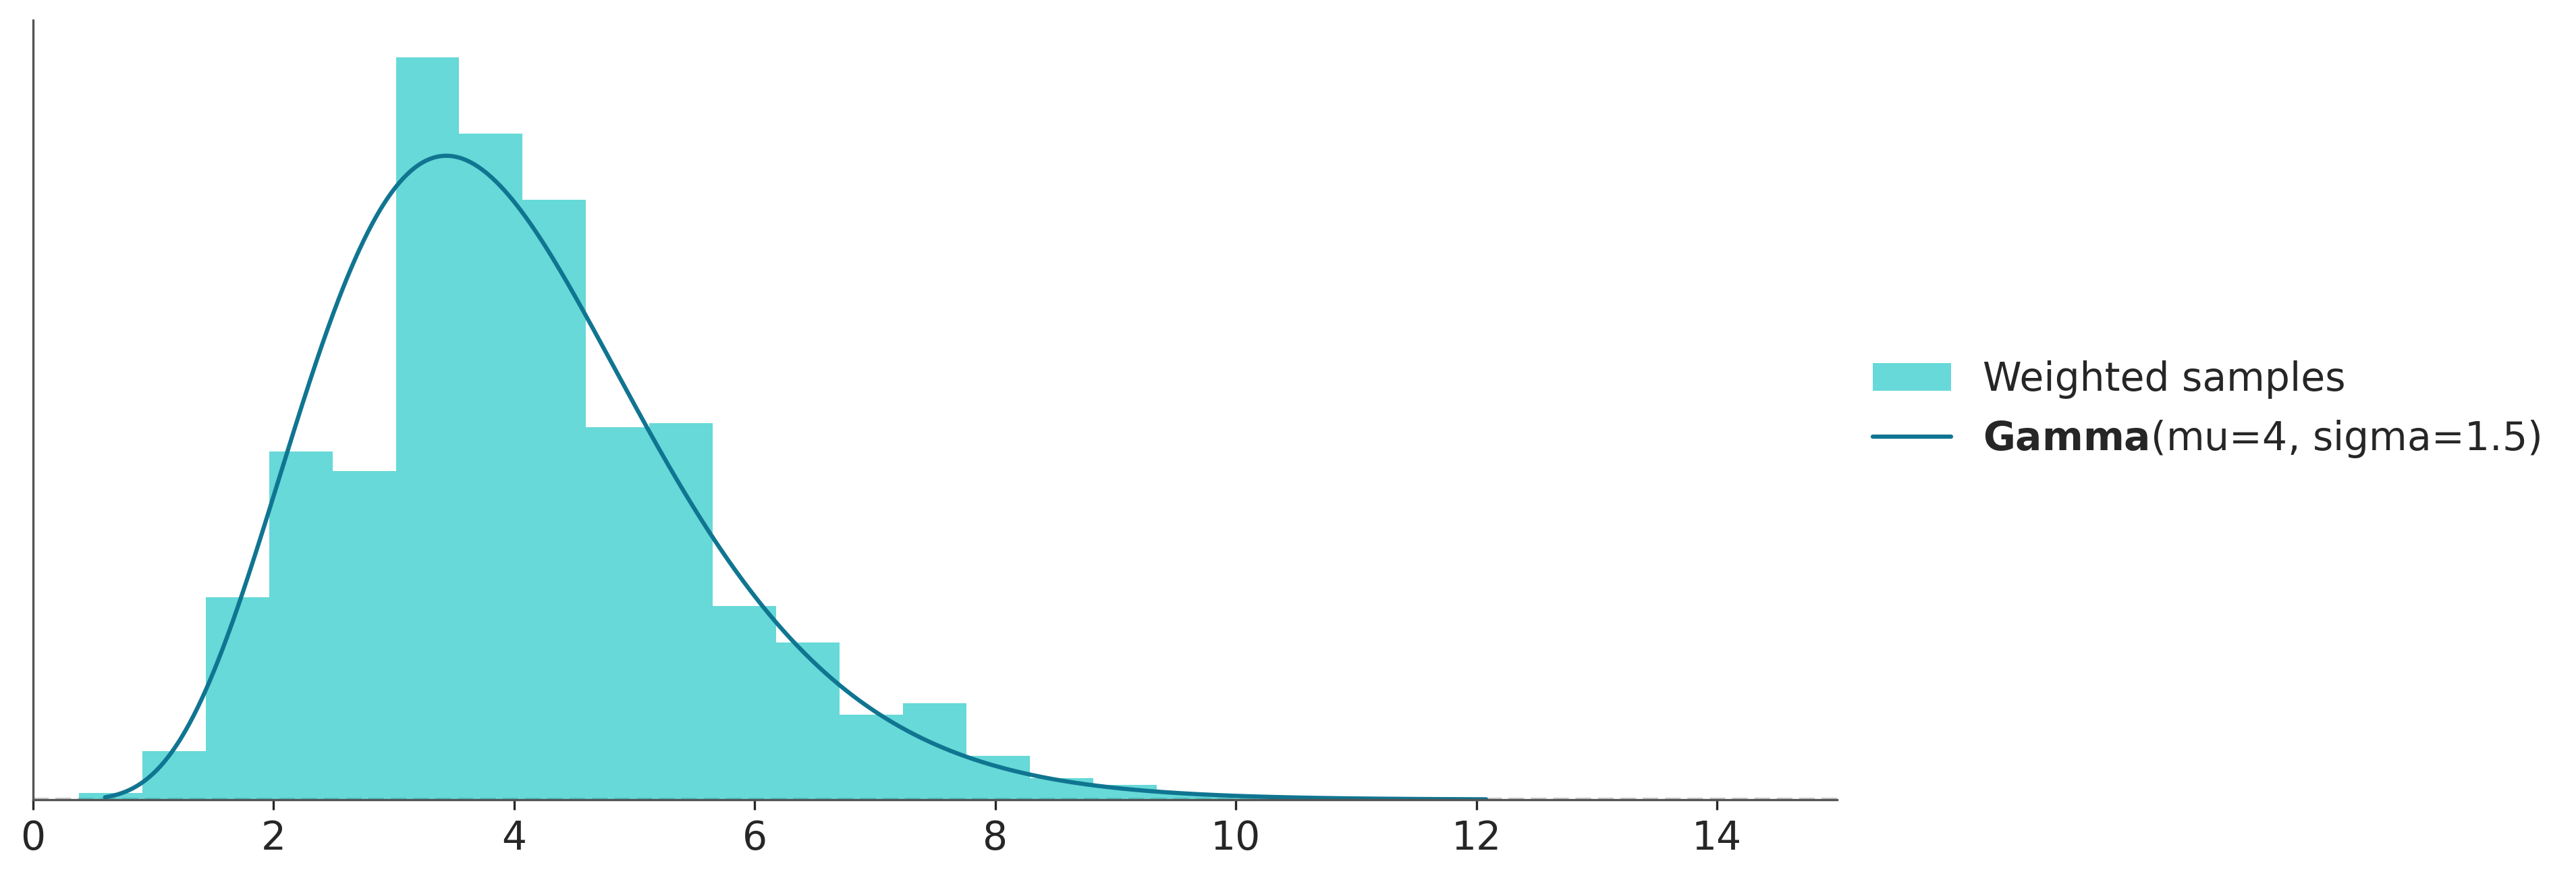

In [ ]:
g = pz.Normal(0, 10)
samples = g.rvs(1000)
f = pz.Gamma(mu=4, sigma=1.5)

w = f.pdf(samples) / g.pdf(samples)

plt.hist(samples, bins=100, density=True, weights=w, alpha=0.6, color='C1', label='Weighted samples')
plt.xlim(0, 15)


f.plot_pdf();

*Observación:*

al aplicar muestreo de importancia, cuanto más similares sean las distribuciones $g$ y $f$, mejores serán, en general, los resultados obtenidos. En la práctica, las inferencias tienden a ser más confiables cuando g tiene un soporte mayor que $f$, es decir, cuando es una distribución más “ancha”. Intuitivamente, buscamos que las muestras generadas a partir de $g$ cubran adecuadamente todo el soporte relevante de $f$, o al menos aquellas regiones donde $f$ concentra mayor densidad. De esta manera, evitamos que existan regiones importantes de $f$ que queden poco representadas o directamente sin muestras provenientes de $g$. Si esto ocurre, algunos pesos de importancia pueden adquirir valores extremadamente grandes y hacer que las estimaciones sean inestables.

*Nota:*

Dado que logramos una mejor idea de afrontar un muestreo por importancia, veamos como proceder:

la distribución que conocemos es la distribución a posteriori, y quisiéramos aproximar mediante muestreo de importancia a la distribución a posteriori dejando uno afuera $p(y_i \mid \theta_{-i}^j)$.

Lo que los pesos de importancia que nos interesa calcular son:

$$
w_i^j = \frac{p(\theta^j \mid y_{-i} )}{p(\theta^j \mid y)} \propto \frac{p(\theta) \prod_{i\not=-i}^n p(y_i \mid \theta)}{p(\theta) \prod_i^n p(y_i \mid \theta)} \propto \frac{1}{p(y_i \mid \theta^j)}
$$

Al comparar el numerador y el denominador, podemos observar que la mayoría de los términos que aparecen en ambos se eliminan entre sí. El único término que permanece es el likelihood asociado a la observación que estamos dejando fuera. Por otra parte, los pesos obtenidos de esta manera están definidos únicamente hasta una constante de proporcionalidad. Esto no representa una dificultad, ya que podemos obtener los pesos normalizados dividiendo cada uno de ellos por la suma de todos los pesos.

Este resultado resulta especialmente útil, ya que permite obtener el ELPD correspondiente a una validación cruzada leave-one-out sin necesidad de realizar un nuevo ajuste del modelo para cada observación. En otras palabras, es posible aproximar todo el procedimiento a partir de un único ajuste del modelo sobre el conjunto completo de datos. Además, para realizar este cálculo solo necesitamos disponer de los valores del log-likelihood, cuyo costo computacional suele ser relativamente pequeño.

Sin embargo, aparece un inconveniente importante. La distribución $p(\theta^j \mid y_{-i})$ se obtiene utilizando una observación menos que $p(\theta^j \mid y)$. Por este motivo, es razonable esperar que sea más dispersa o “ancha” que la distribución posterior completa. Esta situación es justamente la opuesta a la que resulta conveniente para el muestreo de importancia.

En algunos problemas, quitar una única observación modifica muy poco la distribución a posteriori, por lo que esta diferencia puede ser prácticamente despreciable. El problema aparece cuando la observación eliminada tiene una influencia considerable sobre el ajuste. En ese caso, ambas distribuciones pueden diferir de manera importante y esto se refleja en los pesos de importancia: algunos adquieren valores mucho mayores que los demás y terminan teniendo una influencia desproporcionada sobre la estimación.

Una alternativa sencilla consiste en limitar los valores de los pesos que resultan excesivamente grandes. Sin embargo, esta estrategia introduce nuevas dificultades que no consideraremos aquí. Una opción más fundamentada consiste en utilizar el comportamiento teórico de estos pesos. Bajo determinadas condiciones, los valores extremos de los pesos pueden modelarse mediante una distribución de Pareto. Así, en lugar de eliminar directamente los pesos grandes, podemos ajustar una distribución de Pareto a su comportamiento y reemplazar los valores extremos por valores suavizados obtenidos a partir de dicho ajuste.

Este procedimiento permite reducir la influencia de los pesos extremadamente grandes y, por lo tanto, obtener una estimación más estable mediante muestreo de importancia. Al combinar esta estrategia de suavizado con el procedimiento leave-one-out, obtenemos el método denominado *Pareto-Smooth Importance Sampling Leave-One-Out Cross Validation*, conocido habitualmente como PSIS-LOO-CV.

*Nota:* Como el nombre completo y su sigla resultan bastante largos, de aquí en adelante simplemente nos referiremos al método como **LOO** (pronunciado “lu”).




### Trabajamos con LOO y WAIC

Tanto LOO como WAIC buscan estimar el desempeño predictivo fuera de la muestra y, bajo determinadas condiciones y cuando el tamaño de la muestra es suficientemente grande, ambos métodos convergen hacia el mismo resultado. Por este motivo, desde un punto de vista teórico, pueden considerarse métodos asintóticamente equivalentes.

Sin embargo, que dos métodos coincidan en el límite no significa que tengan necesariamente el mismo comportamiento en aplicaciones concretas. En la práctica, LOO suele presentar un comportamiento más robusto. Una de sus principales ventajas es que, mediante el diagnóstico basado en la distribución de Pareto, podemos identificar observaciones para las cuales la aproximación utilizada podría no ser adecuada.

Por esta razón, cuando tenemos disponible la opción de utilizar ambos métodos, suele ser conveniente trabajar con LOO, ya que además de proporcionar una estimación del desempeño predictivo nos ofrece información adicional sobre la calidad de la aproximación.

### Cálculo de LOO

Después de todo el desarrollo anterior, calcular LOO resulta relativamente sencillo desde el punto de vista computacional. ArviZ proporciona la función loo, a la que debemos pasar un objeto InferenceData que contenga los valores del `log_likelihood`.

Hay que tener en cuenta que, por defecto, PyMC no incorpora este grupo al resultado de pm.sample. Por lo tanto, debemos solicitar explícitamente que se almacene el log-likelihood durante el muestreo.

In [ ]:
with modelo_cat:
    pm.compute_log_likelihood(idata_cat,
                              extend_inferencedata=True,  # actualizamos "in-place"
                              progressbar=False,
                             )

In [ ]:
loo_p = az.loo(idata_cat)
loo_p

/usr/local/lib/python3.12/dist-packages/arviz/stats/stats.py:797: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


,0
elpd_loo,-171.370524
se,7.873294
p_loo,3.077105
n_samples,2000
n_data_points,111
warning,True
loo_i,[<xarray.DataArray 'loo_i' ()> Size: 8B\narray...
pareto_k,[<xarray.DataArray 'pareto_shape' ()> Size: 8B...
scale,log
good_k,0.697064


Una vez realizado el cálculo, obtenemos, entre otros resultados, una estimación del ELPD mediante LOO junto con su error estándar. También aparece `p_loo`, que puede interpretarse como una medida del número efectivo de parámetros del modelo. No necesariamente coincide con el número de parámetros que escribimos explícitamente en el modelo, ya que se trata de una cantidad que refleja la complejidad efectiva del modelo desde el punto de vista predictivo. En el ejemplo de `modelo_cat`, por ejemplo, su valor coincide aproximadamente con 3, que es el número de parámetros del modelo.

**Diagnóstico mediante Pareto $k$:**

Además de la estimación del ELPD, LOO proporciona información sobre la calidad de la aproximación utilizada para cada observación. Para esto se emplea el parámetro $k$, obtenido a partir del ajuste de una distribución de Pareto a los pesos de importancia.

Recordemos que en el procedimiento LOO estamos intentando aproximar lo que ocurriría si ajustáramos el modelo nuevamente dejando una observación fuera, pero sin tener que realizar un nuevo ajuste para cada dato. Para conseguirlo utilizamos muestreo de importancia. El problema es que, cuando una observación tiene una influencia muy grande sobre el ajuste, algunos pesos pueden adquirir valores extremadamente elevados. En esos casos, la aproximación puede volverse poco confiable.

El parámetro $k$ permite detectar justamente este tipo de situaciones. Como se realiza este diagnóstico para cada observación, obtenemos un valor de $k$ asociado a cada dato. Por lo tanto, los valores de $k$ cumplen una doble función: permiten identificar observaciones particularmente influyentes y, al mismo tiempo, señalan aquellas observaciones para las cuales la aproximación utilizada por LOO podría presentar dificultades.

En ArviZ, estos resultados pueden aparecer acompañados por un mensaje de advertencia cuando se detectan valores problemáticos.

Como referencia práctica, podemos utilizar la siguiente clasificación:

Si $k < 0.7$, la aproximación suele considerarse adecuada.
Si $0.7 \leq k < 1$, la estimación puede presentar problemas y conviene analizar con mayor cuidado la observación correspondiente.
Si $k \geq 1$, la aproximación mediante muestreo de importancia resulta particularmente problemática.

El límite de $0.7$, sin embargo, no debe interpretarse como una constante universal. El umbral depende también de la cantidad de muestras disponibles de la distribución a posteriori. En el ejemplo, trabajamos con 4000 muestras, y para tamaños de muestra superiores a aproximadamente 2000 el valor de referencia se encuentra cercano a $0.7$. Por este motivo, en aplicaciones prácticas suele ser conveniente trabajar con varios miles de muestras posteriores.

Una posible estrategia para mejorar una situación problemática consiste en aumentar la cantidad de draws utilizada en pm.sample. Al disponer de más muestras, el comportamiento de los pesos puede estimarse con mayor precisión y algunos valores de $k$ pueden disminuir. Sin embargo, esto no garantiza que el problema desaparezca y, en determinadas situaciones, sería necesario utilizar una cantidad de muestras tan grande que el costo computacional dejaría de ser razonable.

Los valores de $k$ también pueden inspeccionarse gráficamente mediante `plot_khat`.

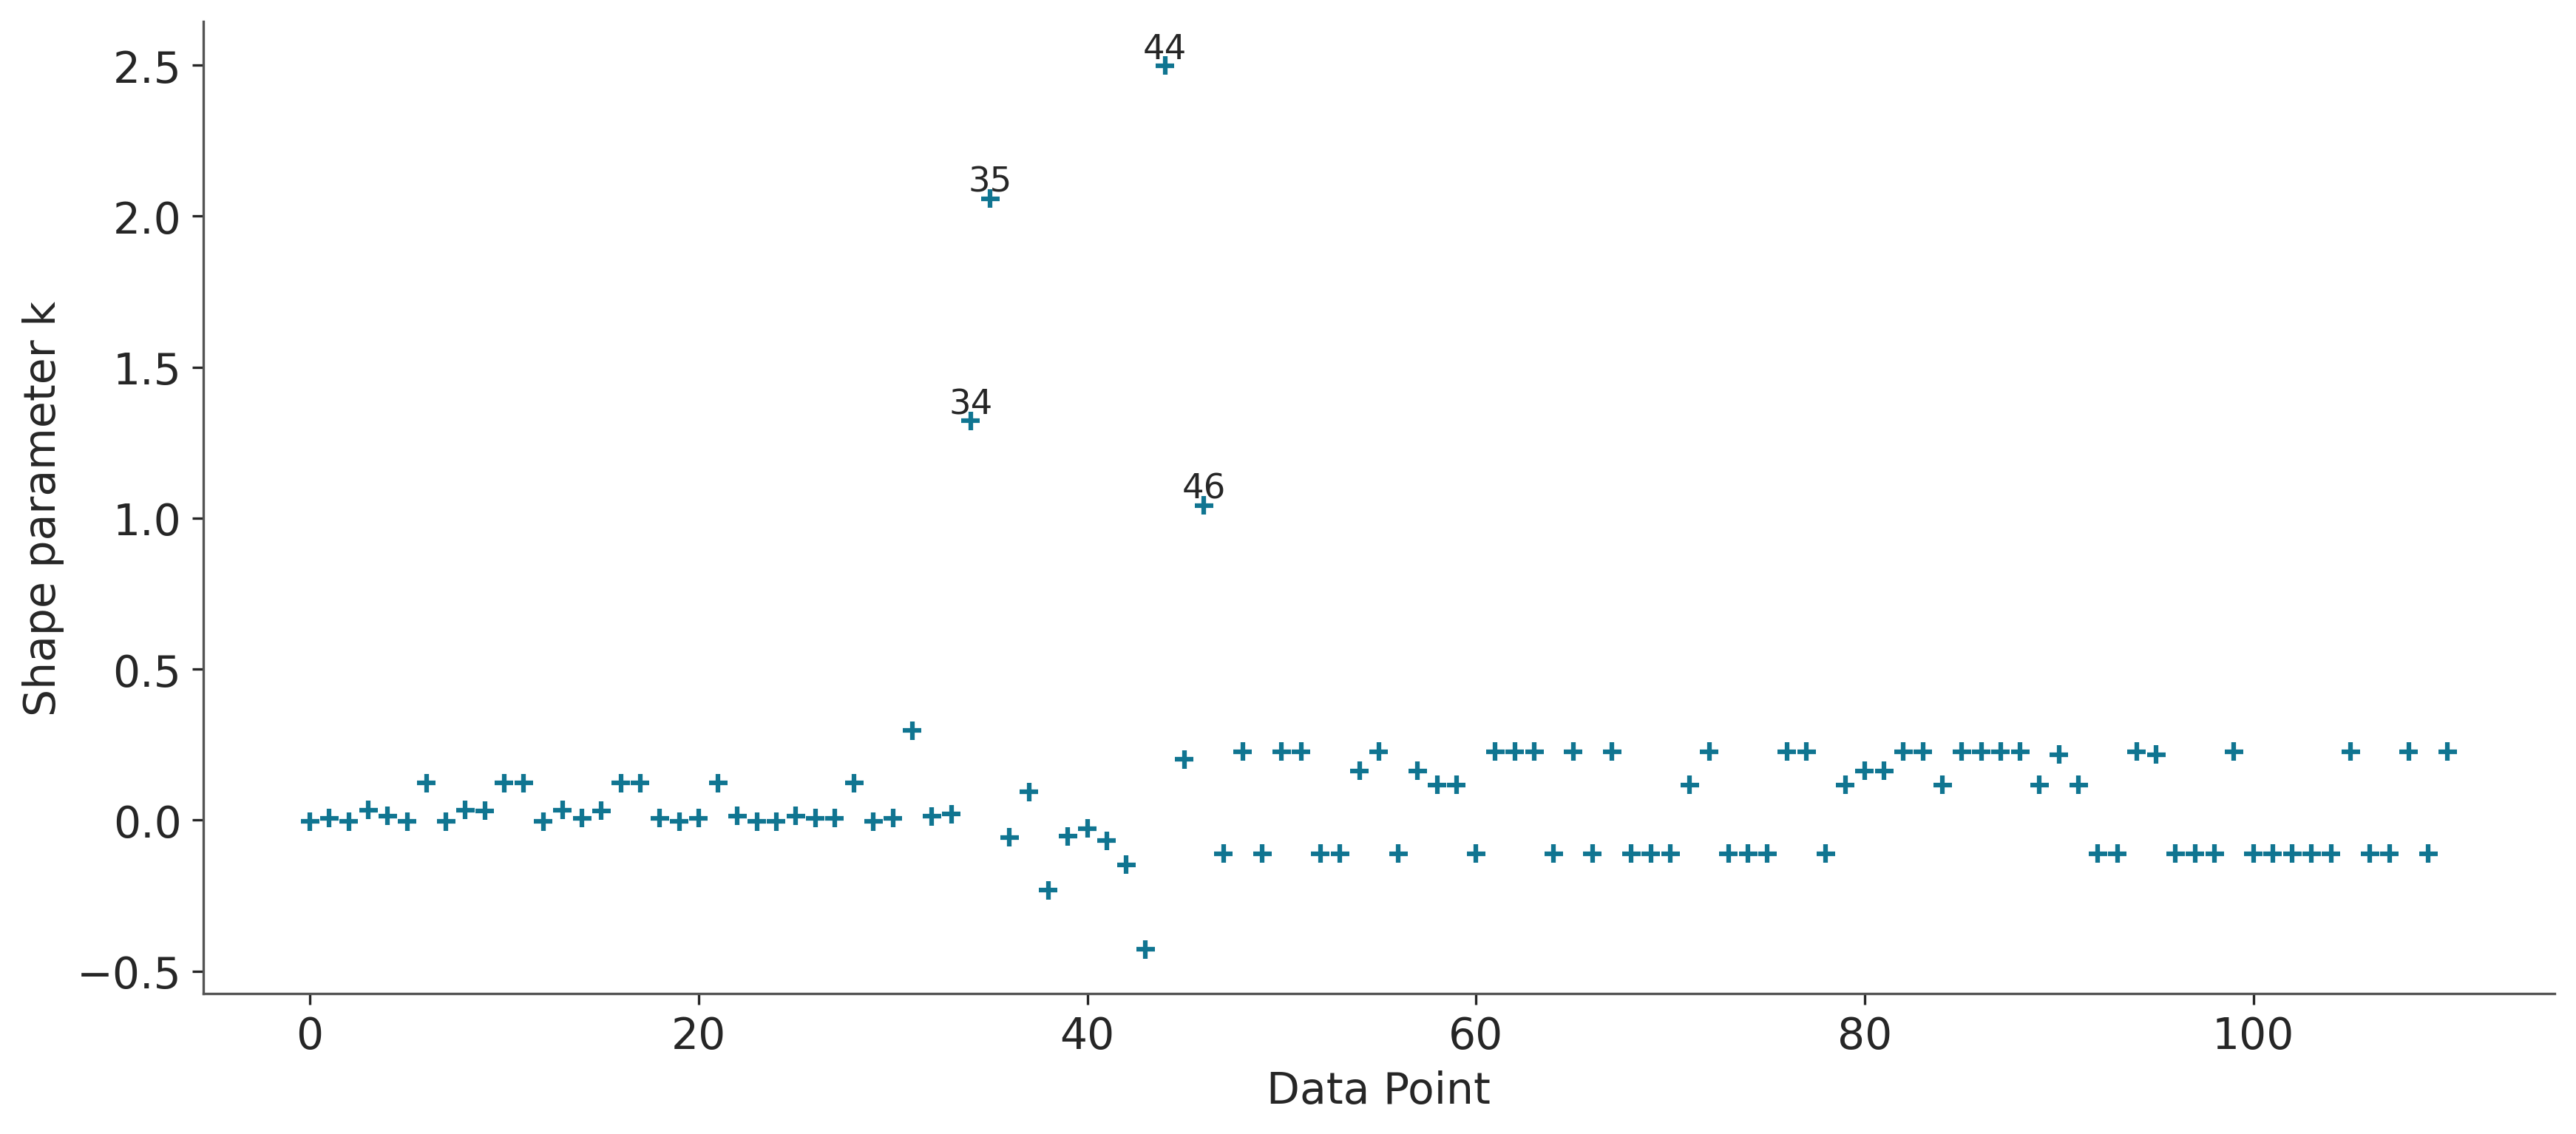

In [ ]:
az.plot_khat(loo_p, threshold=0.7);

***¿Qué nos dicen las observaciones con $k$ alto?:***

Aunque una de las principales aplicaciones de LOO es la comparación entre modelos, el diagnóstico de Pareto resulta útil incluso cuando estamos trabajando con un único modelo. Una observación con un $k$ elevado merece ser investigada, ya que puede estar indicando algo relevante sobre los datos o sobre la forma en que hemos planteado el modelo.

Por ejemplo, podría tratarse de un problema durante la recolección o el registro de los datos. También puede ocurrir que el dato sea completamente correcto, pero que resulte particularmente inesperado desde la perspectiva del modelo. En ese caso, la observación puede estar revelando que el modelo tiene dificultades para representar alguna característica de los datos.

Cuando aparece un valor $k > 0.7$, el $p_{loo}$ puede aportar información adicional. Si $p$ representa el número total de parámetros del modelo, podemos comparar $p_loo$ con $p$ para obtener indicios sobre la relación entre la complejidad del modelo y su comportamiento predictivo.

Si $p_{loo} << p$, puede existir un problema de especificación del modelo. Esta situación debería contrastarse también mediante las comprobaciones predictivas a posteriori. Una posibilidad es que el modelo utilizado sea demasiado restrictivo y no consiga representar adecuadamente la variabilidad de los datos. En ese caso puede ser necesario introducir una estructura más flexible. Por ejemplo, podríamos reemplazar una distribución Poisson por una NegativaBinomial, una ZeroInflatedPoisson o una HurdlePoisson, o utilizar una distribución $T$ de Student en lugar de una Normal. También podría ser necesario incorporar términos no lineales u otras fuentes de estructura que el modelo actual no contempla.
Si $p_{loo} < p$ y además el número de observaciones es pequeño en relación con la cantidad de parámetros, por ejemplo $p>N/5$, puede existir un modelo excesivamente flexible o con priors demasiado poco informativos. Esta situación puede aparecer, por ejemplo, en modelos jerárquicos cuando tenemos muy pocas observaciones por grupo, en splines con una cantidad elevada de nudos o en Procesos Gaussianos con valores de escala demasiado pequeños.
Si $p_{loo} > p$, la situación requiere especial atención, ya que puede estar señalando problemas importantes en el modelo. Cuando $p<< N$, es esperable que las comprobaciones predictivas a posteriori también revelen dificultades. En cambio, cuando el número de parámetros es grande en relación con el tamaño de la muestra, por ejemplo $p>N/5$, las comprobaciones predictivas a posteriori pueden no detectar necesariamente el problema.

Estas reglas no deben interpretarse como pruebas automáticas de que el modelo es correcto o incorrecto. Más bien constituyen señales que nos ayudan a decidir dónde conviene investigar con mayor profundidad.



**LOO-PIT**

Finalmente, LOO puede utilizarse para evaluar el comportamiento predictivo de un único modelo, incluso cuando no tenemos otro modelo con el cual compararlo. Para esto podemos utilizar la función `plot_loo_pit`.

El gráfico puede resultar familiar si lo comparamos con los gráficos utilizados anteriormente para los valores p-Bayesianos marginales. La idea general es similar: estamos comparando la distribución predictiva con los datos observados. La diferencia es que ahora la distribución predictiva se construye mediante un procedimiento leave-one-out.

En particular, LOO-PIT considera

$$p\left(\tilde{y}_i \leq y_i \mid y_{-i}\right)$$

Es decir, para cada observación evaluamos la probabilidad predictiva acumulada de obtener un valor menor o igual que el valor observado, utilizando para construir esa predicción la información disponible en los datos restantes, $y_{-i}$.

En términos intuitivos, estamos preguntando qué tan bien puede el modelo anticipar una observación que no utilizó para ajustarse. De esta manera, LOO-PIT permite analizar visualmente si las distribuciones predictivas generadas por el modelo son compatibles con los datos que efectivamente observamos.

Si el comportamiento del gráfico se aleja de lo esperado, esto puede indicar problemas en la distribución predictiva del modelo, como falta de dispersión, exceso de dispersión o dificultades para representar determinadas regiones de los datos.

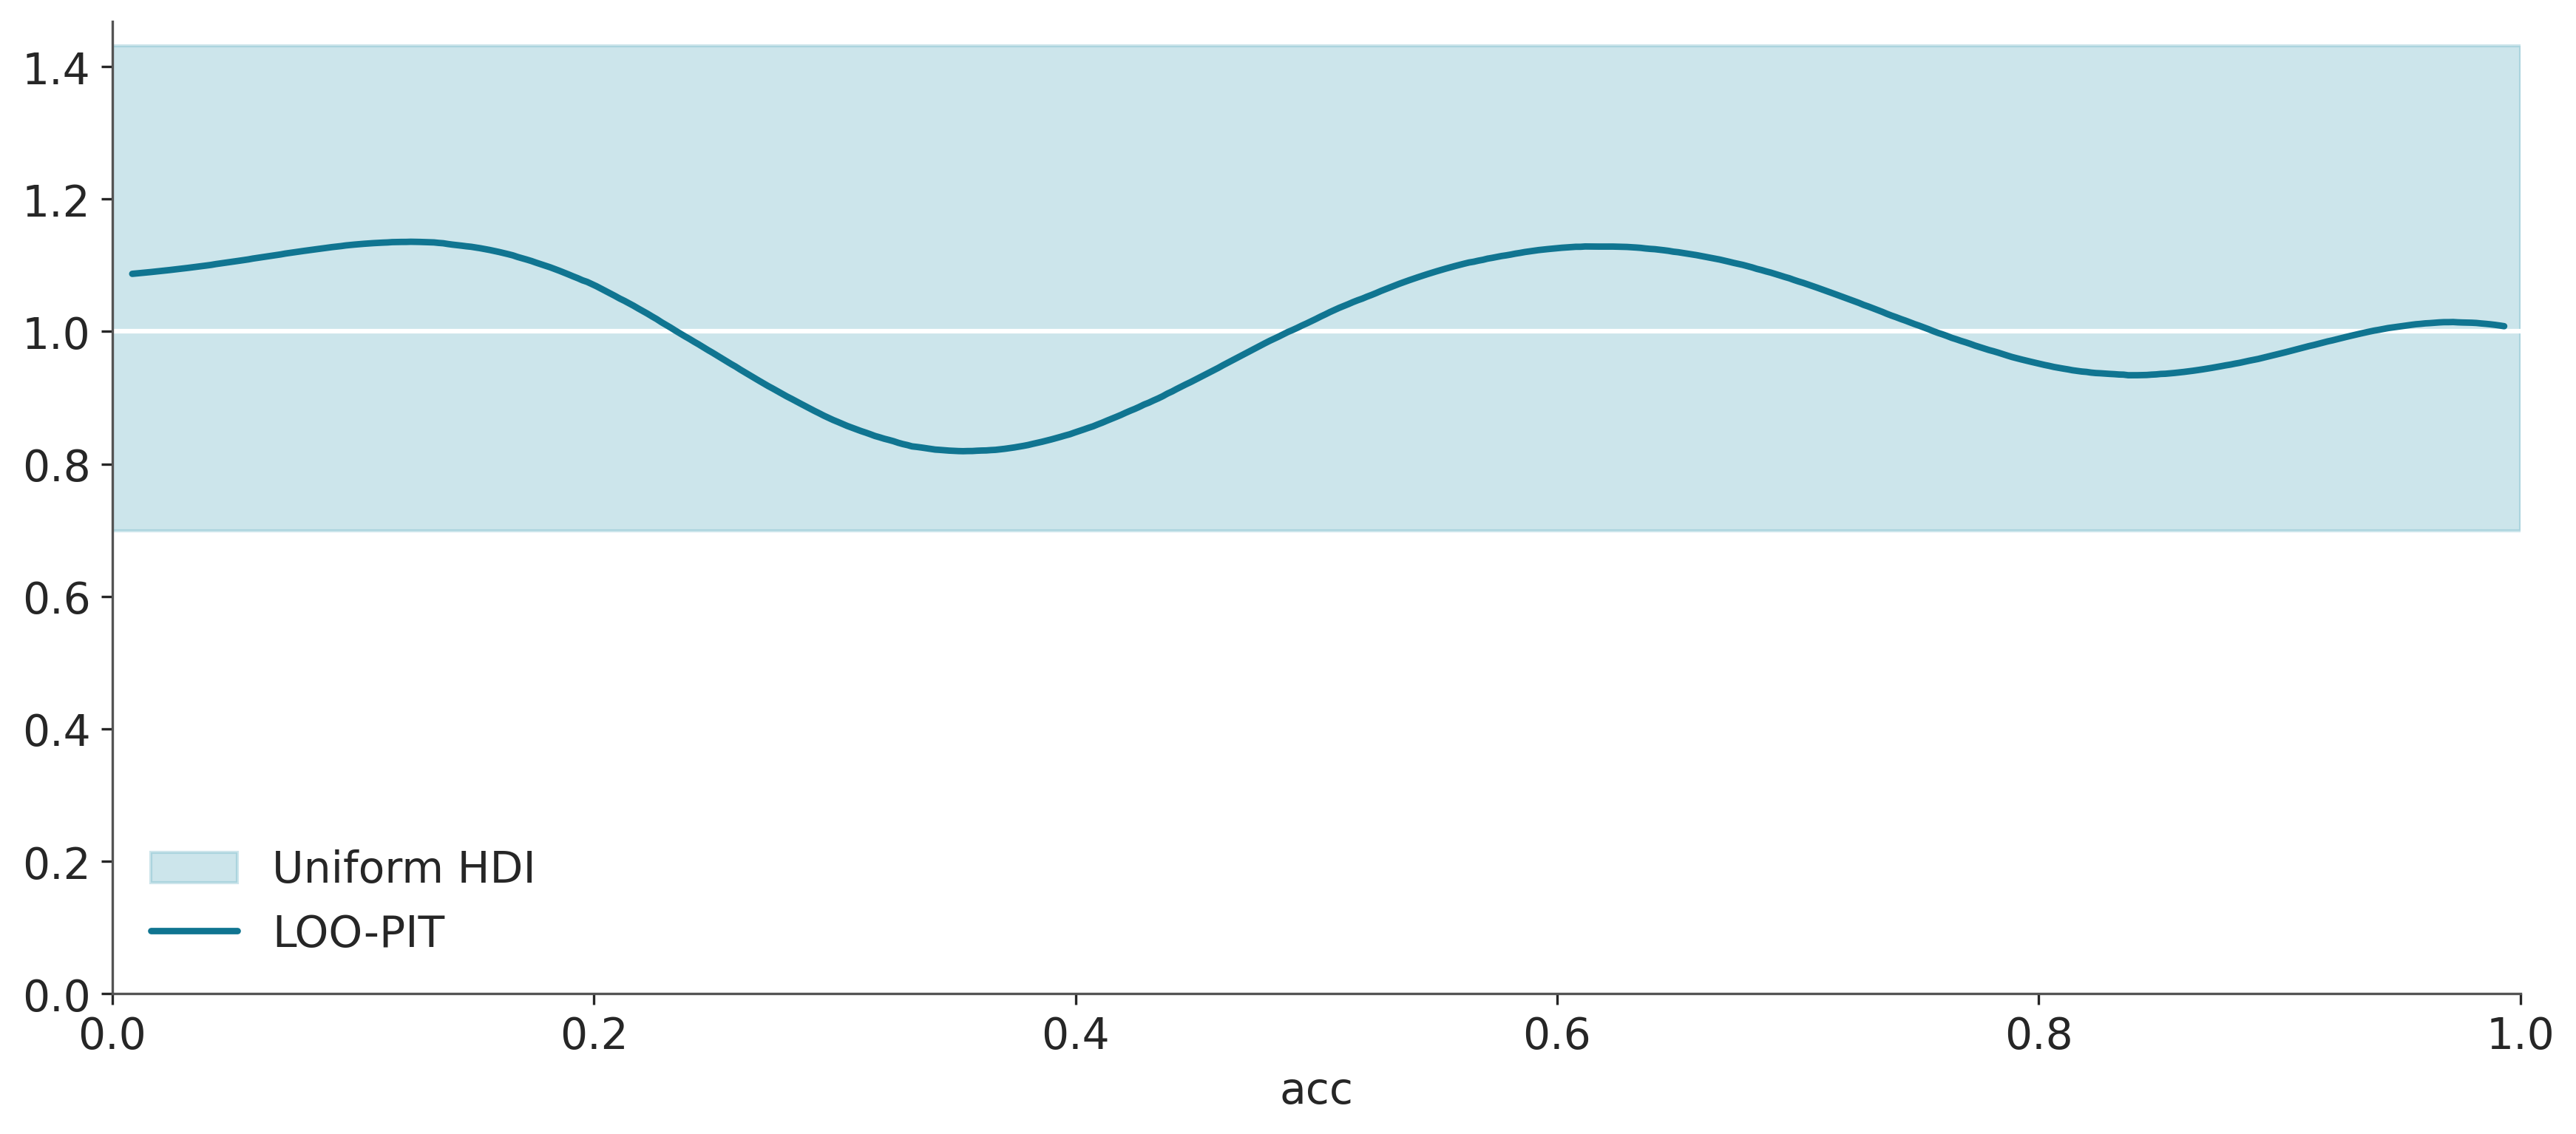

In [ ]:
az.plot_loo_pit(idata_cat, y="acc", use_hdi=True);

#### Otros criterios de información

**DIC y BIC**

DIC (Deviance Information Criterion) es otro criterio que puede utilizarse para comparar modelos. Si siguiéramos la escala informal del bayesómetro™, podría ubicarse en un punto intermedio: tiene una base más cercana al enfoque bayesiano que AIC, aunque está lejos de aprovechar completamente las ventajas de criterios como WAIC o LOO.

A pesar de que DIC todavía aparece con frecuencia en algunas aplicaciones, actualmente suele preferirse el uso de WAIC y, especialmente, de LOO. Estos métodos cuentan con mejores propiedades tanto desde el punto de vista teórico como en evaluaciones empíricas, por lo que no recomendamos utilizar DIC como criterio principal para la comparación de modelos.

Por otro lado, también existe el BIC (Bayesian Information Criterion). Sin embargo, su nombre puede llevar a cierta confusión: que incluya la palabra Bayesian no significa necesariamente que se trate de un método plenamente bayesiano. Al igual que ocurre con la regresión logística o con la sopa seca de mi madre, el nombre puede resultar un tanto engañoso.

El BIC fue introducido, entre otras razones, para corregir algunas limitaciones de AIC, y su autor proporcionó una justificación basada en ideas bayesianas. Sin embargo, en su formulación habitual, BIC utiliza una estimación puntual obtenida mediante máxima verosimilitud y se deriva bajo supuestos equivalentes a considerar priors planos. Por esta razón, no utiliza toda la información contenida en una distribución posterior.

Además, la diferencia fundamental entre BIC y criterios como AIC, WAIC o LOO está en qué problema intentan resolver. AIC, WAIC y LOO están orientados a evaluar la capacidad predictiva de un modelo, es decir, qué tan bien podría generalizar a nuevos datos. BIC, en cambio, está más relacionado con la identificación del modelo generador de los datos, o del modelo correcto dentro del conjunto de modelos considerados.

En este sentido, BIC guarda una relación conceptual más cercana con los factores de Bayes que con criterios predictivos como WAIC o LOO. Más adelante veremos con mayor detalle los factores de Bayes y las diferencias entre estos dos enfoques para comparar modelos.

In [ ]:
target = pz.StudentT(nu=4, mu=0, sigma=1).rvs(200)

with pm.Model() as modelo_n:
    μ = pm.Normal("μ", 0, 1)
    σ = pm.HalfNormal("σ", 1)
    pm.Normal("y", μ, σ, observed=target)
    idata_n = pm.sample(idata_kwargs={"log_likelihood":True})

with pm.Model() as modelo_t:
    μ = pm.Normal("μ", 0, 1)
    σ = pm.HalfNormal("σ", 1)
    ν = pm.Exponential("ν", scale=30)
    pm.StudentT("y", nu=ν, mu=μ, sigma=σ, observed=target)
    idata_t = pm.sample(idata_kwargs={"log_likelihood":True})

Output()

Output()

In [ ]:
cmp_df = az.compare({'modelo_n':idata_n, 'modelo_t':idata_t})
cmp_df

,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
modelo_t,0,-333.632599,3.251625,0.000000,1.0,13.757052,0.000000,False,log
modelo_n,1,-342.448144,3.389341,8.815545,0.0,16.076116,5.228716,False,log


Interpretación de `az.compare()`

La tabla presenta un resumen de la comparación entre los modelos considerados. Cada fila corresponde a un modelo diferente y las columnas contienen distintas medidas asociadas a su desempeño:

**rank:** indica la posición que ocupa cada modelo en el ordenamiento. El modelo ubicado en el primer lugar es el que presenta el mejor desempeño según el criterio utilizado.

**elpd:** corresponde a la estimación puntual del expected log predictive density obtenida mediante LOO. En general, valores más altos indican una mejor capacidad predictiva esperada.

**p:** representa el número efectivo de parámetros del modelo.

**elpd_diff:** muestra cuánto difiere el ELPD de cada modelo respecto del modelo que ocupa la primera posición.

**weight:** representa el peso asignado a cada modelo. Esto resulta especialmente útil si, en lugar de seleccionar un único modelo, queremos realizar predicciones combinando varios de ellos. En ese caso, estos pesos indican la contribución relativa de cada modelo. Aquí observamos que model_t concentra prácticamente todo el peso.

**se:** es el error estándar asociado a la estimación del ELPD.

**dse:** indica el error estándar de las diferencias entre los valores de ELPD de los modelos.

**warning:** señala si se detectaron valores problemáticos del parámetro k durante el cálculo de PSIS-LOO.

**scale:** especifica la escala en la que se expresan los valores del ELPD.

Esta misma comparación puede visualizarse gráficamente mediante:

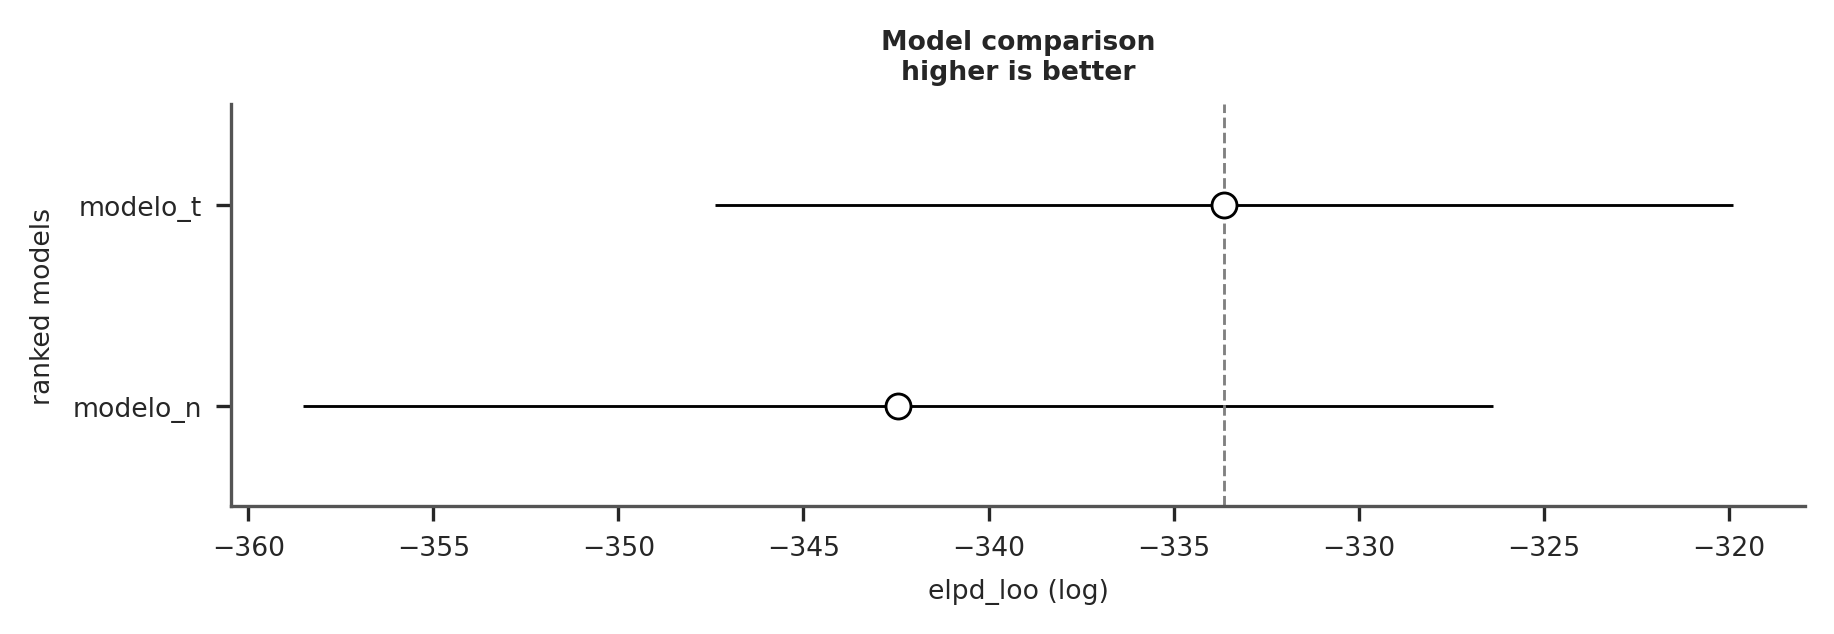

In [ ]:
az.plot_compare(cmp_df, plot_ic_diff=False);

En el gráfico de comparación, los círculos vacíos indican las estimaciones puntuales del ELPD para cada modelo, mientras que las líneas negras representan la incertidumbre asociada a esas estimaciones mediante sus errores estándar.

Además, una línea vertical gris discontinua marca el valor correspondiente al modelo con el ELPD más alto. Esta referencia permite observar con mayor facilidad qué tan alejados se encuentran los demás modelos respecto del mejor resultado.

Una estrategia simple para comparar modelos consiste en seleccionar aquel que presente el mayor valor de ELPD, ya que, según este criterio, sería el modelo con mejor capacidad predictiva esperada sobre nuevos datos.

Si aplicamos esta regla en este ejemplo, el modelo cuadrático sería el candidato preferido. Además, la diferencia observada parece ser suficientemente clara: al considerar la incertidumbre asociada a las estimaciones, los intervalos de error estándar no se superponen, lo que aporta evidencia de que el desempeño predictivo de los modelos no es equivalente.

Por supuesto, no siempre la elección será tan clara. Si las diferencias entre los ELPD fueran pequeñas en relación con sus errores estándar, o si las barras de incertidumbre se solaparan considerablemente, sería necesario interpretar la comparación con más cautela. En esas situaciones, puede no haber evidencia suficiente para afirmar que un modelo predice mejor que otro.

## 3.4. Métodos numéricos de Inferencia Bayesiana

**Introducción a los lenguajes de programación probabilista:**

La inferencia bayesiana proporciona un marco muy general y coherente para el análisis de datos, además de permitir construir modelos con gran flexibilidad. Sin embargo, esta flexibilidad tiene un costo: en muchos problemas reales, las distribuciones posteriores resultantes no pueden obtenerse mediante una expresión analítica sencilla.

Por este motivo, la aplicación práctica de los métodos bayesianos suele requerir el uso de métodos numéricos que permitan aproximar las cantidades de interés. En este contexto surgen los lenguajes de programación probabilista (LPP), cuyo propósito es facilitar la construcción y el ajuste de modelos probabilísticos.

La idea central de estos lenguajes es integrar las herramientas propias de la programación de propósito general con la especificación de modelos estadísticos. De esta manera, quien analiza los datos puede concentrarse principalmente en plantear el modelo, realizar inferencias e interpretar los resultados, sin necesidad de implementar desde cero todos los algoritmos matemáticos y computacionales necesarios para obtener la distribución posterior.

La posibilidad de aplicar modelos bayesianos complejos de forma relativamente accesible es, en realidad, un desarrollo bastante reciente. Esto ha sido posible gracias, principalmente, a dos avances: el incremento sostenido de la capacidad de cómputo y el desarrollo de algoritmos capaces de realizar inferencia automática.

Para comprender por qué estos métodos computacionales son necesarios, conviene volver al teorema de Bayes y observar dónde aparece una de las principales dificultades del cálculo de la distribución posterior.

$$
\underbrace{p(\boldsymbol{\theta} \mid \boldsymbol{Y})}_{\text{posterior}} = \frac{\overbrace{p(\boldsymbol{Y} \mid \boldsymbol{\theta})}^{\text{likelihood}}\; \overbrace{p(\boldsymbol{\theta})}^{\text{prior}}}{\underbrace{{p(\boldsymbol{Y})}}_{\text{marginal likelihood}}}
$$

Observen la siguiente siguación:

$$
{p(\boldsymbol{Y}) = \int_{\boldsymbol{\Theta}} p(\boldsymbol{Y} \mid \boldsymbol{\theta})p(\boldsymbol{\theta}) d\boldsymbol{\theta}}
$$

el likelihood marginal toma la forma de una integral, entonces surge otro problema:

**La dificultad de calcular la posterior:**

El término que actúa como constante de normalización de la distribución posterior, implica que se deba integrar sobre todos los posibles valores que puede tomar el parámetro $θ:$

$$p(y)=∫p(y∣θ)p(θ)dθ.$$

No es tan sencillo resolver esta integral, incluso si queremos hacerlo de manera computacional... la dificultad depende, entre otras cosas, de la cantidad de parámetros del modelo. Si θ representa un único parámetro desconocido, como ocurre en un modelo beta-binomial, debemos resolver una integral en una dimensión. Si el modelo contiene dos parámetros, la integración debe realizarse sobre un espacio bidimensional. En general, el número de dimensiones de la integral coincide con el número de parámetros desconocidos que debemos integrar.

A medida que aumenta esta dimensionalidad, el cálculo se vuelve considerablemente más complejo. Este fenómeno es una de las razones por las cuales la inferencia bayesiana puede resultar difícil de implementar directamente en modelos más realistas.

Una alternativa consiste en evitar explorar de manera uniforme todo el espacio de parámetros y concentrar el esfuerzo computacional en aquellas regiones donde la distribución posterior tiene mayor densidad. Dicho de otra forma, resulta más útil estudiar los valores de θ para los cuales la información aportada conjuntamente por el prior y el likelihood produce valores relativamente altos de la posterior.

Este es, a grandes rasgos, el principio detrás de muchos métodos numéricos utilizados en inferencia bayesiana, como los métodos MCMC: explorar de manera eficiente las regiones más relevantes de la distribución posterior y utilizarlas para aproximar las cantidades de interés.

Sin embargo, esta estrategia no es adecuada para todos los problemas. En particular, concentrarse únicamente en las regiones de mayor densidad puede producir aproximaciones deficientes cuando queremos calcular el likelihood marginal, ya que este requiere tener en cuenta la contribución de todo el espacio de valores posibles del parámetro, y no solamente de las regiones donde la posterior alcanza sus valores más altos.

$$
p(\theta \mid y) \propto \operatorname{Beta}(\alpha_{a priori} + y, \beta_{a priori} + N - y)
$$

Para esos casos suele ser posible también calcular el marginal likelihood de forma analítica.

Pero en general no tenemos expresiones analíticas y entonces debemos confiar en métodos numéricos.

### Método Markov Chain Monte Carlo (MCMC)

Los métodos Markov Chain Monte Carlo (MCMC) constituyen una amplia familia de algoritmos utilizados para resolver distintos problemas mediante simulación. En el contexto bayesiano, uno de sus principales objetivos es obtener muestras que permitan aproximar la distribución posterior.

Una forma intuitiva de entenderlos es pensar que comparten cierta lógica con el método de la grilla. En ambos casos podemos evaluar el prior y el likelihood para distintos valores de los parámetros. Sin embargo, existe una diferencia fundamental: mientras que en el método de la grilla debemos definir de antemano los puntos que vamos a evaluar, los métodos MCMC exploran el espacio de parámetros de forma adaptativa.

A medida que avanza el algoritmo, las evaluaciones tienden a concentrarse en las regiones más relevantes de la distribución posterior. El resultado final no es simplemente una colección de puntos con sus respectivas probabilidades, sino un conjunto de muestras cuya frecuencia es proporcional a la probabilidad posterior.

Por ejemplo, si una determinada región del espacio de parámetros tiene aproximadamente tres veces más probabilidad posterior que otra, esperamos observar, en promedio, unas tres veces más muestras en esa región.

De manera muy general, un algoritmo MCMC comienza en algún punto inicial y construye progresivamente una secuencia de estados. En cada iteración podemos pensar que ocurren dos acciones principales:

A partir del estado actual, se propone un nuevo punto mediante algún mecanismo de perturbación o generación.
El algoritmo decide, de acuerdo con una regla probabilística, si acepta la propuesta o si permanece en el punto actual.

Esta es la idea básica que comparten los distintos algoritmos de la familia MCMC. Lo que diferencia a un método de otro es, precisamente, la forma en que se generan las propuestas y la regla utilizada para decidir si estas deben ser aceptadas.

A continuación veremos uno de los algoritmos más sencillos para comprender esta lógica: el método de Metropolis-Hastings.

### Metropolis-Hastings

Metropolis-Hastings no es un algoritmo muy moderno o particularmente eficiente, pero Metropolis-Hastings es simple de entender y también proporciona una base para comprender métodos más sofisticados y poderosos.

El algoritmo Metropolis-Hasting se define de la siguiente manera:

1. Inicialice el valor del parámetro $\boldsymbol{X}$ en $x_i$
2. Utilice una distribución de propuesta $q(x_{i + 1} \mid x_i)$ para generar un nuevo valor $x_{i + 1}$
3. Calcule la probabilidad de aceptar el nuevo valor como:

$$
p_a (x_{i + 1} \mid x_i) = \min \left(1, \frac{p(x_{i + 1}) \; q(x_i \mid x_{i + 1})} {p(x_i) \; q (x_{i + 1} \mid x_i)} \right)
$$

4. Si $p_a > R$ donde $R \sim \mathcal{U}(0, 1)$, guarde el nuevo valor; de lo contrario, guarde el anterior.
5. Iterar de 2 a 4 hasta que se haya generado una muestra *suficientemente grande*


El algoritmo de Metropolis-Hastings es un método de propósito general y no está restringido exclusivamente a problemas bayesianos. Sin embargo, en nuestro caso podemos interpretar $p(x_i)$ como la densidad de la distribución posterior evaluada en el estado actual $x_i$. El algoritmo genera una propuesta $x_{i+1}$ a partir del punto actual mediante una distribución propuesta q. La probabilidad de aceptar este nuevo estado depende de una comparación entre la densidad de interés en ambos puntos y, en el caso general, también de las probabilidades asociadas al mecanismo de propuesta. Una forma de simplificar un poco el método es notar que si $q$ es una distribución simétrica, los términos $q(x_i \mid x_{i + 1})$ y $q(x_{i + 1} \mid x_i)$ se cancelarán (conceptualmente significa que es igualmente probable que vayamos de $x_{i+1}$ a $x_i$ o de $x_{i}$ a $x_{i+1}$), dejando solo un cociente entre el posterior evaluado en dos puntos. Este algoritmo siempre aceptará moverse de una región de baja probabilidad a una más alta y aceptará probabilísticamente moverse de una región de alta a una baja probabilidad.

Es importante tener presente que Metropolis-Hastings no busca optimizar una función. El objetivo del algoritmo no es localizar el valor del parámetro que maximiza p, sino generar muestras que nos permitan representar y recorrer toda la distribución objetivo.

Para lograrlo, la cadena no permanece necesariamente en las regiones de mayor probabilidad. Aunque los movimientos hacia zonas de mayor densidad son favorecidos, el algoritmo también puede aceptar, con cierta probabilidad, propuestas que lo lleven hacia regiones menos probables. Esta característica es justamente la que permite explorar la distribución en lugar de simplemente converger hacia su máximo.

Desde un punto de vista teórico, una de las propiedades fundamentales de Metropolis-Hastings es que su mecanismo de transición satisface la condición de balance detallado, que puede expresarse como:

$$
p_i t_{ij} = p_j t_{ji}
$$

La fórmula anterior nos dice que la probabilidad de estar en un estado $i$ por la probabilidad de moverse del estado $i$ al $j$, resulta igual a la probabilidad de estar en el estado $j$ y moverse del $j$ al $i$.

Esta condición de balance detallado, nos resultará suficiente para garantizar que un algoritmo de MCMC es capaz de muestrear de forma correcta de una distribución arbitraria dada una cantidad infinita de pasos.

Podemos probar que un algortimo de muestreo es teóricamente válido demostrando que cumple con el balance detallado.

veamos el ejemplo del modelo Beta-Binomial:

\begin{aligned}
    \theta \sim &\; \text{Beta}(\alpha, \beta) \\
    Y \sim &\; \text{Bin}(n=1, p=\theta)
\end{aligned}

Trabajaremos directamente con Python:

In [ ]:
def post(θ, Y, α=1, β=1):
    if 0 <= θ <= 1:
        prior = pz.Beta(α, β).pdf(θ)
        like  = pz.Bernoulli(θ).pdf(Y).prod()
        prob = like * prior
    else:
        prob = -np.inf
    return prob

También necesitamos datos, por lo que generaremos algunos datos falsos aleatorios para este propósito.

In [ ]:
Y = pz.Bernoulli(0.7).rvs(20, random_state=123)

Y finalmente ejecutamos nuestra implementación del algoritmo Metropolis-Hastings:

In [ ]:
n_iters = 1000
can_sd = 0.05
α = β =  1
θ = np.array([0.5])
trace = {"θ":np.zeros(n_iters)}
p2 = post(θ, Y, α, β)

for iter in range(n_iters):
    θ_can = pz.Normal(θ, can_sd).rvs(1)
    p1 = post(θ_can, Y, α, β)
    pa = p1 / p2

    if pa > pz.Uniform(0, 1).rvs(1):
        θ = θ_can
        p2 = p1

    trace["θ"][iter] = θ.item()

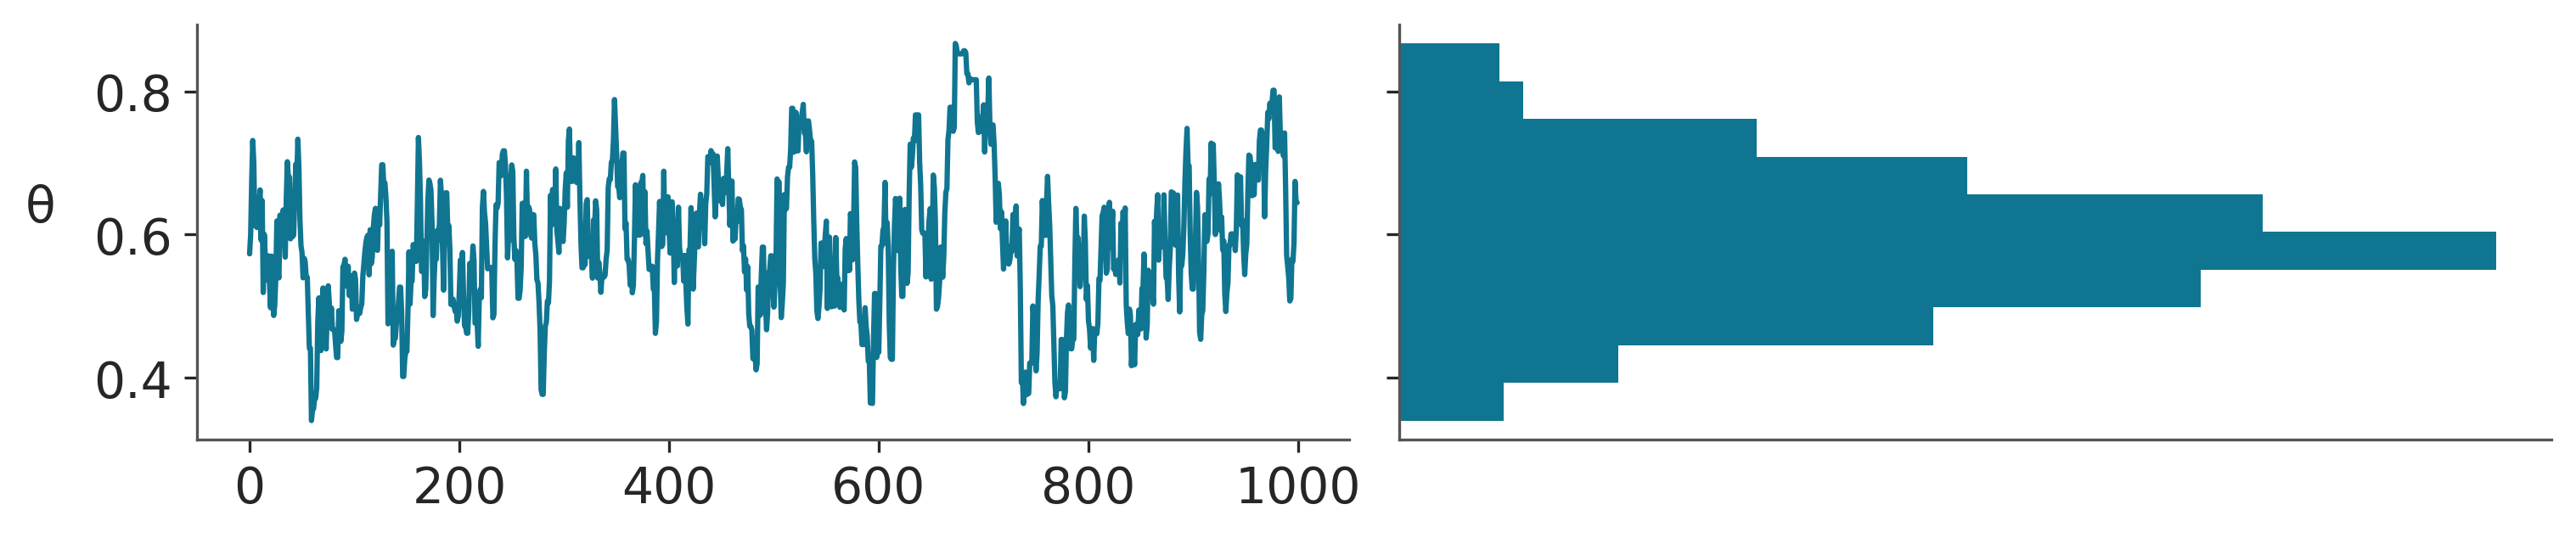

In [ ]:
_, axes = plt.subplots(1, 2, figsize=(10, 2), sharey=True)
axes[0].plot(trace['θ'])
axes[0].set_ylabel('θ', rotation=0, labelpad=15)
axes[1].hist(trace['θ'], orientation="horizontal", density=True)
axes[1].set_xticks([]);

El primer panel de la figura anterior, nos muestra cada uno de los valores muestreados en cada paso, y el panel de la derecha el histograma de esos valores.

### MH adaptativo

Las garantías teóricas de Metropolis-Hastings y otros métodos MCMC se establecen en el límite en que el número de iteraciones tiende a infinito. En ese escenario, la distribución de propuesta y el punto inicial no afectan el resultado final. Sin embargo, en la práctica trabajamos con un número finito de muestras, por lo que estas elecciones pueden tener un impacto importante en la eficiencia del algoritmo.

En particular, una distribución de propuesta que funciona bien para un problema puede resultar muy ineficiente para otro, ya que su desempeño depende de la geometría de la distribución posterior. Por esta razón, no existe una única distribución de propuesta que sea adecuada para todos los modelos.

Los métodos de MH adaptativo incorporan una fase inicial de tuning en la que se ajustan los parámetros de la distribución de propuesta para mejorar la eficiencia del muestreo. Por ejemplo, puede utilizarse una distribución gaussiana cuya varianza o matriz de covarianza se modifica durante esta etapa. Como referencia, algunos resultados teóricos sugieren tasas de aceptación cercanas a 0.4 en problemas unidimensionales y a 0.234 en dimensiones altas.

Es importante destacar que las muestras generadas durante la fase de ajuste generalmente se descartan. Al modificar la distribución de propuesta mientras el algoritmo está corriendo, dejan de cumplirse temporalmente las condiciones que garantizan las propiedades teóricas del método.

En definitiva, la adaptación permite que los métodos MCMC se ajusten a distintas distribuciones posteriores y puedan aplicarse a una gran variedad de problemas. Esta separación entre la especificación del modelo y el procedimiento utilizado para realizar la inferencia es una idea central de la programación probabilista. Sin embargo, los métodos MCMC no funcionan correctamente en todos los casos, por lo que es fundamental contar con herramientas que permitan diagnosticar la calidad del muestreo.

# **4. Evaluamos el muestreo realizado**


La idea de esta sección es poder evaluar las propiedades esperadas de una muestra y lo que nos puede indicar sobre posibles desviaciones entre lo observado y lo predicho por la teoría. Si el diagnóstico encuentra un problema, en general es que hay un problema. Pero si el diagnóstico no encuentra un problema, no quiere decir, estrictamente, que este no exista. Además, como veremos no existe un criterio claro de demarcación. Es el problema del pelado. Se estima que un humano tienen alrededor de 150000 cabellos en su cabeza. Alguien con 0 pelos es claramente un pelado. Pero es dificil establecer un número único y no arbitrario que divida pelados de no pelados.


### Trace plots

Uno de los diagnósticos más habituales para evaluar una simulación MCMC es el trace plot. Este gráfico muestra, para cada parámetro, los valores generados por la cadena a lo largo de las iteraciones.

En una cadena que ha explorado adecuadamente la distribución objetivo, esperamos observar variaciones aparentemente aleatorias alrededor de una región estable, sin tendencias claras ni períodos prolongados en los que la cadena permanezca atrapada en una misma zona.

Por el contrario, ciertos patrones pueden indicar problemas en el muestreo. Por ejemplo, una cadena puede moverse lentamente entre distintas regiones de la distribución, mostrar una tendencia sostenida que sugiera que todavía no alcanzó una región estable o quedar ocasionalmente atrapada en determinadas zonas del espacio de parámetros. Estos comportamientos pueden ser consecuencia de una exploración ineficiente o de características complejas de la distribución posterior.

Por esta razón, en general se recomienda ejecutar varias cadenas independientes, comenzando desde diferentes puntos iniciales. Si todas han explorado correctamente la distribución posterior, no deberíamos observar diferencias sistemáticas entre ellas.

En ArviZ, los trace plots pueden generarse mediante la función az.`plot_trace()`. Para variables continuas, la visualización suele combinar la trayectoria de las cadenas con una estimación de su distribución mediante KDE; en el caso de variables discretas, se utiliza un histograma.

Estas distribuciones marginales también son útiles como herramienta de diagnóstico: esperamos que las distintas cadenas produzcan distribuciones similares, salvo por las pequeñas diferencias esperables debido al número finito de muestras.

### Rank plots

Los trace plots son una herramienta clásica para evaluar cadenas MCMC, pero existen otros diagnósticos que permiten comparar las cadenas de una manera diferente, como los rank plots.

La idea consiste en tomar todas las muestras de un parámetro, independientemente de la cadena de la que provengan, y ordenarlas de menor a mayor. A cada muestra se le asigna entonces un rango. Una vez hecho esto, se recupera la cadena de origen de cada observación y se construye un histograma de los rangos para cada cadena.

Si todas las cadenas estuvieran muestreando correctamente la misma distribución, no debería existir ninguna razón para que una de ellas concentre más valores en los rangos bajos, medios o altos. Por lo tanto, esperaríamos que los histogramas de las distintas cadenas fueran aproximadamente uniformes y similares entre sí.


### $\hat R$ para el ajuste

Los gráficos permiten detectar visualmente ciertos problemas, pero cuando trabajamos con muchos parámetros resulta conveniente contar también con medidas numéricas que permitan evaluar rápidamente la calidad del muestreo.

Una de las más utilizadas es $\hat{R}$, que intenta responder una pregunta sencilla: ¿las distintas cadenas parecen haber convergido hacia la misma distribución?

Este diagnóstico también puede aparecer en la literatura como Gelman-Rubin, en referencia a sus autores originales. Sin embargo, las implementaciones actuales utilizan versiones más generales y robustas que las formulaciones iniciales.

La idea fundamental consiste en comparar la variabilidad entre las cadenas con la variabilidad dentro de cada cadena. Si todas las cadenas están explorando la misma distribución, ambas fuentes de variabilidad deberían ser similares y, en consecuencia,

$$\hat{R}≈1$$

Como regla práctica, suele considerarse satisfactorio obtener valores cercanos a 1, por ejemplo,

$$\hat{R}≲1.01$$

Este umbral, sin embargo, no debe interpretarse como una frontera absoluta. Es una regla práctica basada en evidencia empírica y su utilidad depende del contexto. Por ejemplo, durante las primeras etapas del modelado pueden tolerarse valores algo mayores. Además, cuando un modelo contiene una gran cantidad de parámetros, es más probable encontrar alguno con un $\hat{R}$ superior a 1.01.


En ArviZ podemos calcular este diagnóstico mediante:

Usando ArviZ podemos obtener $\hat R$ usando `az.rhat(⋅)`, `az.summary(⋅)` y `az.plot_forest(⋅, r_hat=True)`

### Gráfico de autocorrelación

Las muestras MCMC están correlacionadas, ya que la probabilidad de aceptar el paso $i$ depende del paso $i-1$, y lo ideal en un experimento como estos es poder trabajar con muestras iid, en particular estas muestras poseen con baja autocorrelación.

En ArviZ obtenemos este gráfico con la función `az.plot_autocorr()`

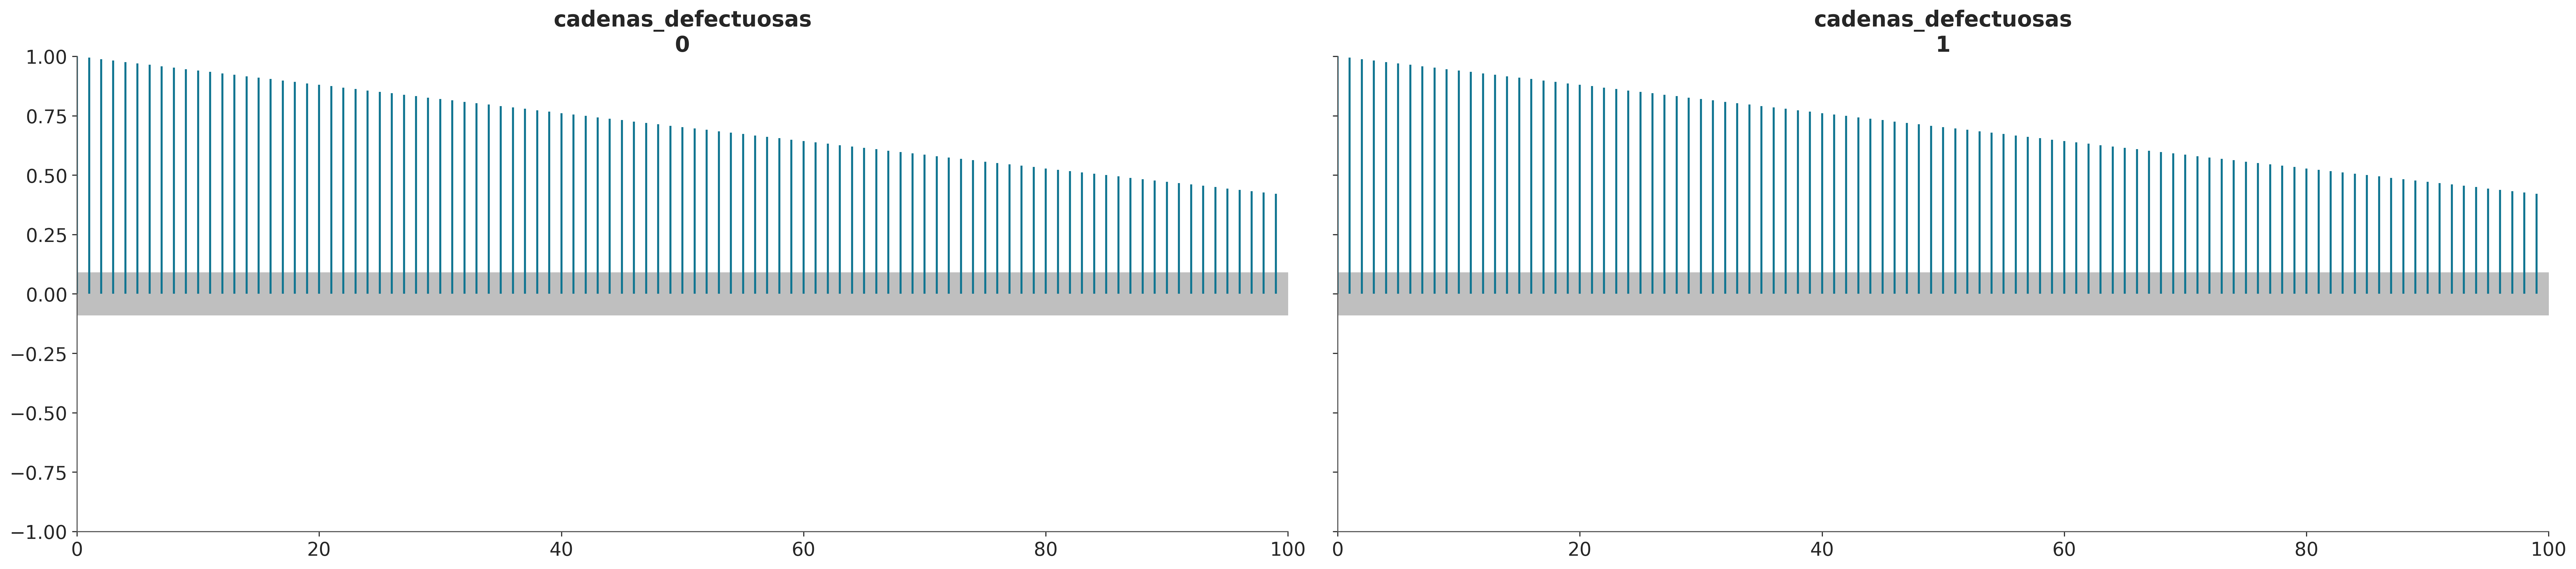

In [ ]:
cadenas_defectuosas = {"cadenas_defectuosas": np.linspace(0, 1, 1000).reshape(2, -1)}
az.plot_autocorr(cadenas_defectuosas);

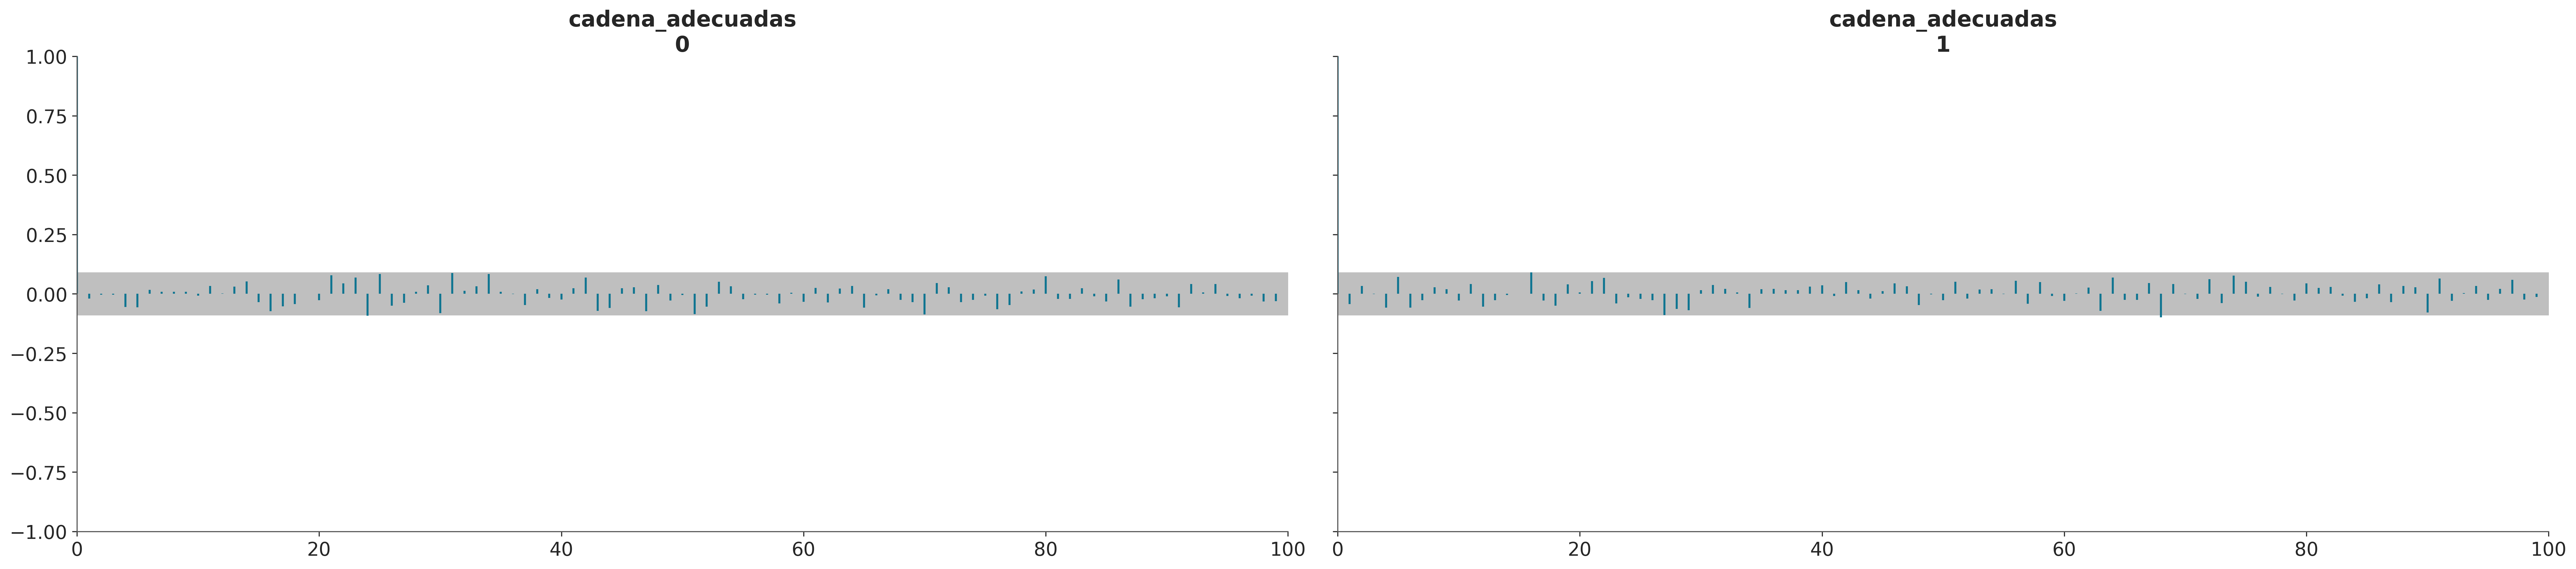

In [ ]:
cadenas_adecuadas = {"cadena_adecuadas": pz.Uniform(0, 1).rvs(size=(2, 500))}
az.plot_autocorr(cadenas_adecuadas);

### Tamaño de muestra efectivo (ESS)

Una característica importante de las muestras obtenidas mediante MCMC es que no son independientes. Las observaciones consecutivas de una cadena suelen presentar autocorrelación, por lo que 1000 muestras MCMC no contienen necesariamente tanta información como 1000 observaciones independientes.

El tamaño de muestra efectivo *(Effective Sample Size, ESS)* permite expresar esta idea en términos de un tamaño equivalente: indica aproximadamente cuántas observaciones independientes proporcionarían una cantidad de información comparable a la obtenida mediante las muestras correlacionadas de MCMC.

Por lo tanto, el ESS nos ayuda a evaluar si la cantidad de muestras obtenidas es suficiente para representar adecuadamente la distribución posterior.

Como regla práctica, suele recomendarse un ESS mayor que 100 por cadena. Así, si trabajamos con cuatro cadenas, sería deseable obtener un ESS total superior a aproximadamente 400.

Con ArviZ podemos obtenerlo `az.ess(⋅)`, `az.summary(⋅)` y `az.plot_forest(⋅, ess=True)`

In [ ]:
pd.concat((az.ess(cadenas_defectuosas).to_pandas(),
           az.ess(cadenas_adecuadas).to_pandas()))

,0
cadenas_defectuosas,2.282878
cadena_adecuadas,1071.060708


Cuando aplicamos `az.summary(⋅)` obtenemos dos valores del ESS: `ess_bulk` y `ess_tail`. Esto ocurre porque distintas regiones del espacio de los parámetros pueden tener distinto valor de ESS. Esto se debe a que no todas las regiones son muestreadas con la misma eficiencia.

In [ ]:
pd.concat([az.summary(cadenas_adecuadas, kind="diagnostics"),
           az.summary(cadenas_defectuosas, kind="diagnostics")])

,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
cadena_adecuadas,0.009,0.004,1071.0,1015.0,1.00
cadenas_defectuosas,0.198,0.079,2.0,11.0,3.05


Si las muestras de MCMC las vamos a usar para calcular valores centrales como medias o medianas entonces tenemos que asegurarnos que el `ess_bulk` sea lo suficientemente algo, en cambio, si queremos calcular intervalos como un HDI 95% hay que asegurarse que `ess_tail` sea adecuado. Si queremos evaluar el desempeño del sampler para varias regiones al mismo tiempo podemos usar la función `az.plot_ess`.

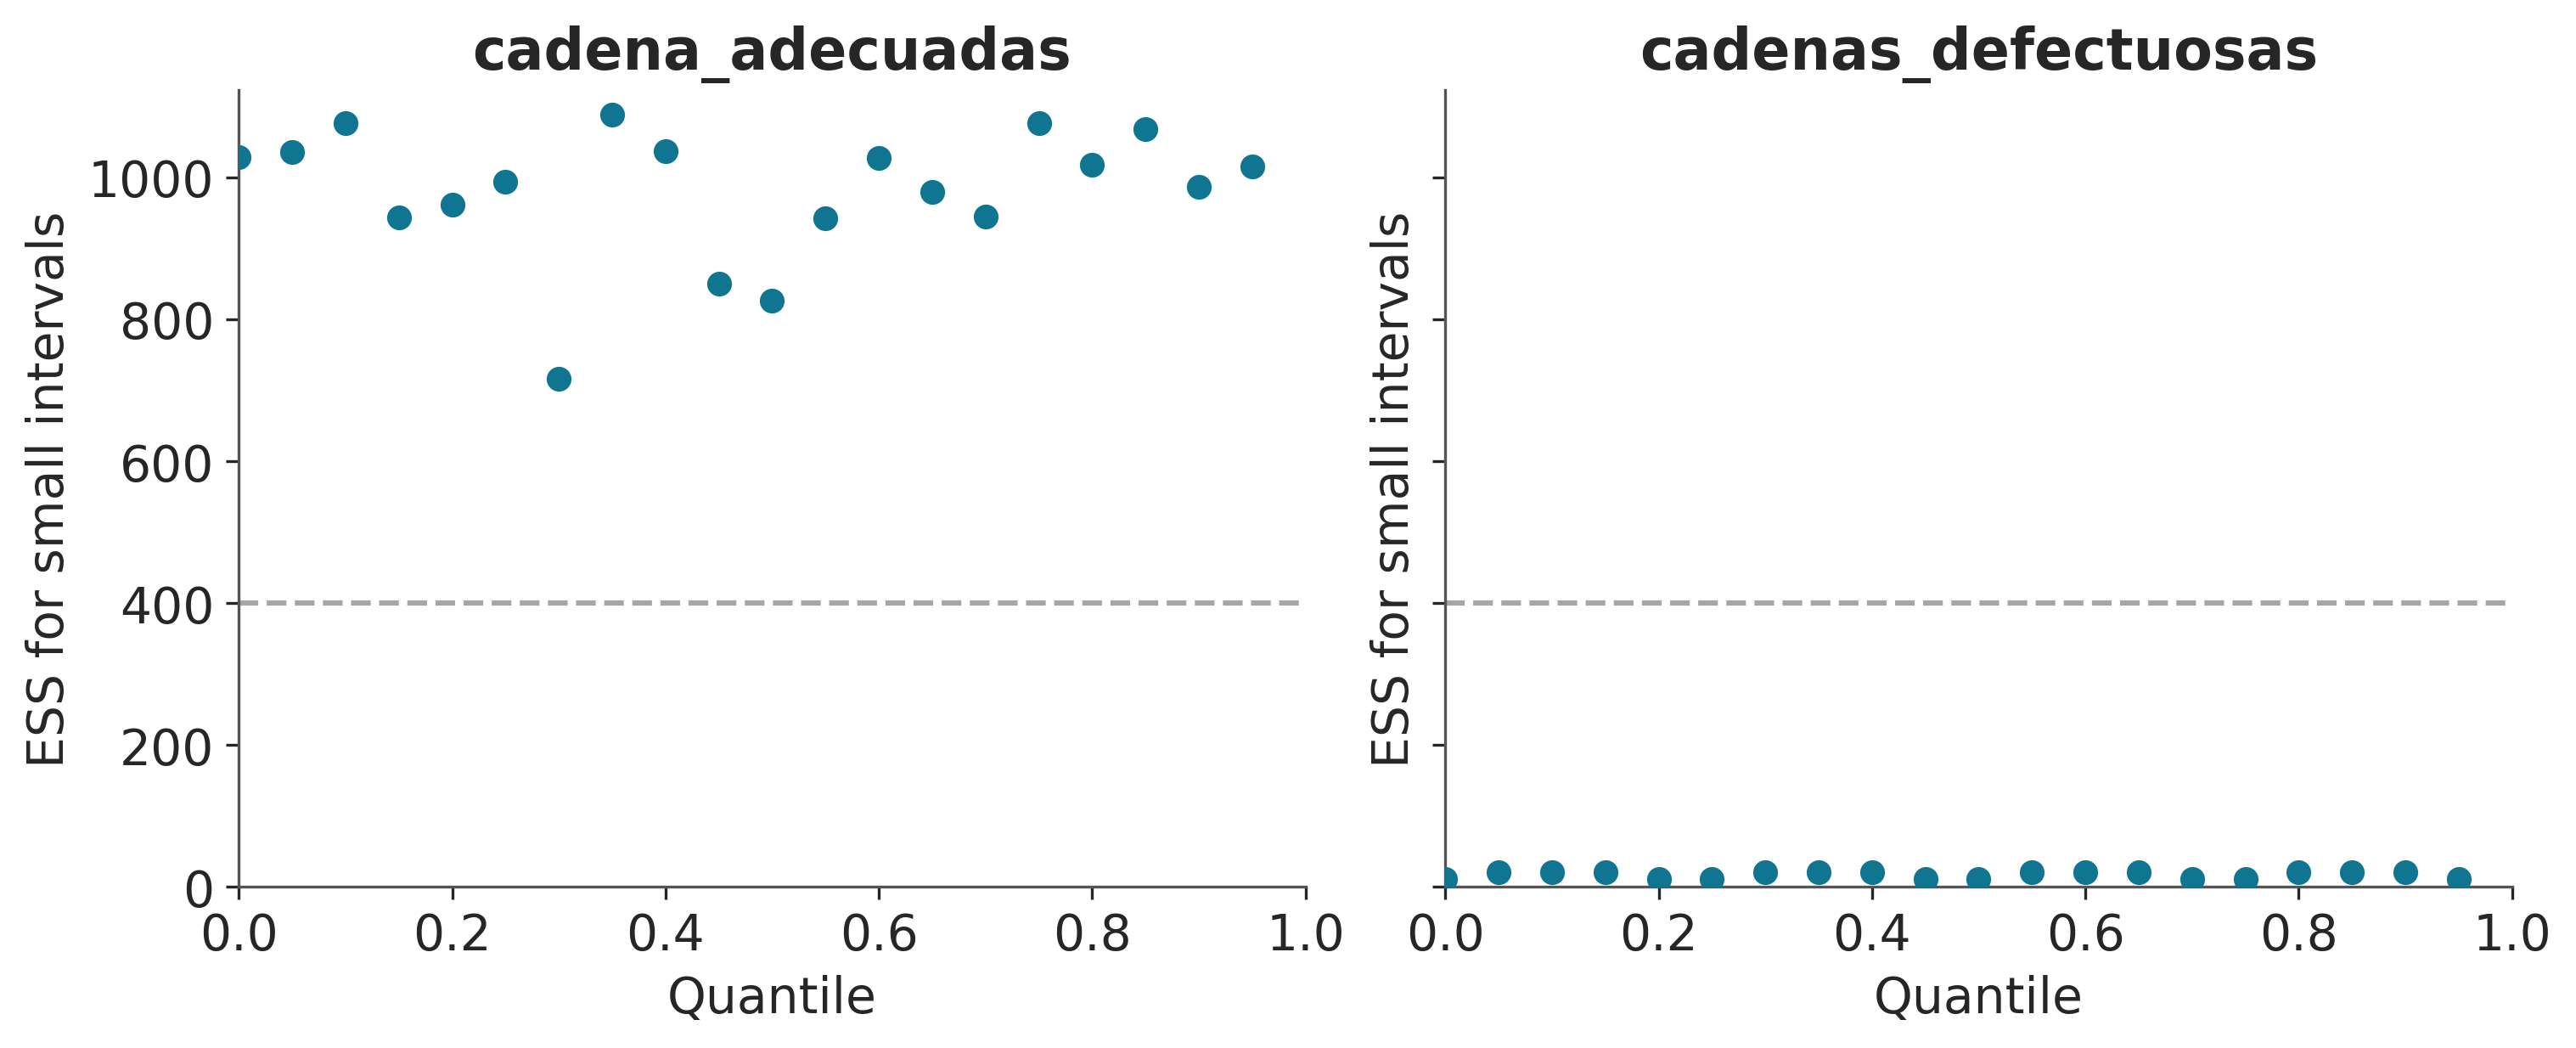

In [ ]:
_, axes = plt.subplots(1, 2, figsize=(10,4), sharey=True)
az.plot_ess(cadenas_adecuadas, ax=axes[0])
az.plot_ess(cadenas_defectuosas, ax=axes[1]);

Una forma simple de aumentar el ESS es aumentar la cantidad de muestras, pero podría darse el caso que el ESS crezca muy lento con el número de muestras, por lo que aún si aumentáramos 10 veces la cantidad de muestras estaríamos por debajo de lo requerido. Una forma de estimar "cuanto nos falta" es usar `az.plot_ess(⋅, kind="evolution")`. Este gráfico nos muestra como fue cambiando el ESS con cada muestra, lo que nos permite hacer proyecciones. En el siguiente ejemplo vemos que para `cadenas_adecuadas` el ESS crece linealmente con el número de muestras mientras que para `cadenas_defectuosas` no crece para nada. Este último caso no hay esperanzas de mejorar el ESS simplemente aumentando la cantidad de muestras.

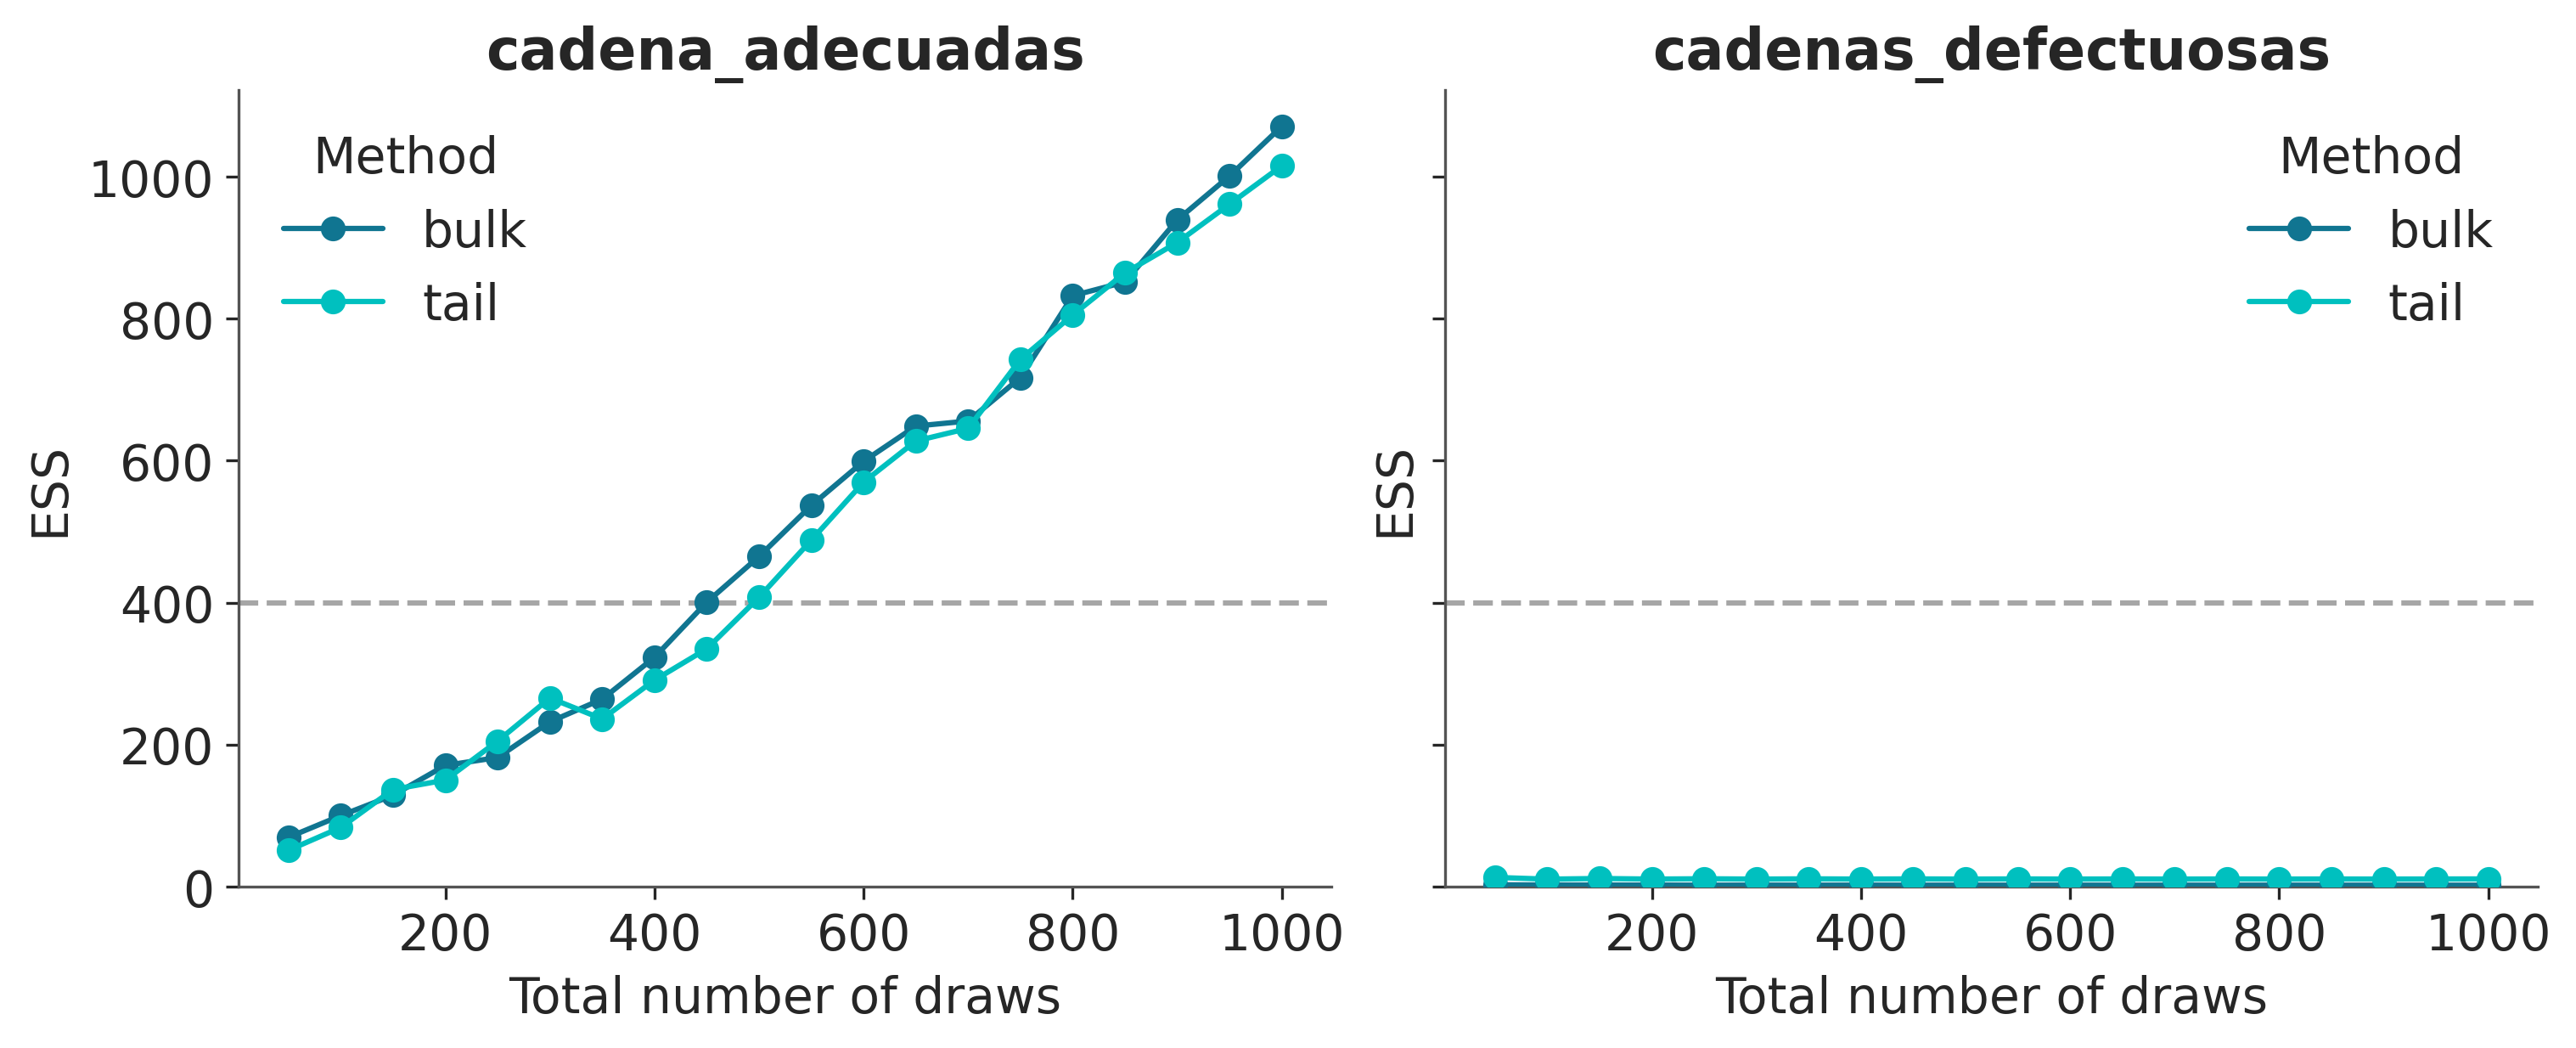

In [ ]:
_, axes = plt.subplots(1, 2, figsize=(10,4), sharey=True)
az.plot_ess(cadenas_adecuadas, kind="evolution", ax=axes[0])
az.plot_ess(cadenas_defectuosas,  kind="evolution", ax=axes[1]);

### Error estándar del Monte Carlo (MCSE)

Error estándar del Monte Carlo (MCSE)

Una de las ventajas del ESS es que no depende de la escala del parámetro. Un ESS de 400 tiene el mismo significado tanto para un parámetro que toma valores entre 0.1 y 0.2 como para otro que varía entre −2000 y 5000. Esto resulta especialmente útil cuando trabajamos con modelos que tienen muchos parámetros, ya que permite detectar rápidamente cuáles presentan un muestreo menos eficiente.

Sin embargo, el ESS no nos dice directamente cuán precisa es nuestra estimación en la escala del parámetro. Para eso podemos utilizar el error estándar de Monte Carlo (MCSE), que cuantifica la incertidumbre introducida por el hecho de estimar una cantidad mediante un número finito de muestras MCMC.

Una característica importante es que el error disminuye aproximadamente como

$$MCSE∝\frac{1}{\sqrt{ESS}}$$

Por lo tanto, multiplicar por 10 la cantidad de muestras no reduce el error diez veces, sino aproximadamente por un factor de $\sqrt{10}≈3$.16. Esto explica por qué aumentar indefinidamente el número de iteraciones no es una solución eficiente cuando existen problemas importantes de muestreo: eventualmente, el costo computacional crece mucho más rápido que la mejora obtenida en precisión.

Además, como las muestras MCMC están correlacionadas, para calcular el MCSE no podemos considerar simplemente el número total de muestras N, sino que debemos utilizar el ESS, que representa la cantidad equivalente de observaciones independientes.

Finalmente, el MCSE también nos ayuda a decidir con qué precisión tiene sentido reportar los resultados. Si, por ejemplo, el MCSE de una media es 0.1, reportarla como 3.15 transmite una precisión que las muestras no permiten sostener. En general, la cantidad de decimales reportados debería ser coherente con la precisión que realmente podemos obtener del muestreo.

Una de las cantidades devueltas por `az.summary(⋅)` es *mc_error*.

### Montecarlo Hamiltoniano (HMC):

Para entender la idea detrás de HMC podemos imaginar una partícula moviéndose sobre una superficie. Su movimiento puede describirse mediante la mecánica hamiltoniana, que permite representar la energía total del sistema como la suma de energía cinética y energía potencial.

La energía potencial depende de la posición de la partícula, mientras que la energía cinética depende de su movimiento. Si colocamos una partícula en el punto más bajo de una superficie en forma de U y no le damos velocidad inicial, permanecerá allí indefinidamente.

Para que explore la superficie necesitamos proporcionarle momentum. La partícula comenzará a desplazarse, transformando progresivamente energía cinética en potencial a medida que asciende. Cuando alcanza un punto suficientemente alto, su velocidad disminuye hasta detenerse momentáneamente; a partir de allí comienza a descender, convirtiendo nuevamente energía potencial en cinética.

Si no existe fricción, la energía total permanece constante: las variaciones de energía cinética se compensan con variaciones de energía potencial.

La idea de HMC consiste en aprovechar este comportamiento físico para construir trayectorias que permitan recorrer eficientemente el espacio de parámetros de la distribución posterior.

### Propuestas aleatorias vs hamiltonianos:


Una diferencia fundamental entre MH y HMC es la manera en que exploran el espacio de parámetros.

En Metropolis-Hastings, las propuestas se generan de manera esencialmente local y aleatoria. Es como intentar recorrer una habitación completamente a oscuras: podemos avanzar, pero no tenemos información sobre lo que encontraremos a continuación.

HMC, en cambio, utiliza información sobre la geometría de la distribución, obtenida mediante sus derivadas. Es como recorrer esa misma habitación con una linterna: podemos utilizar información local para decidir hacia dónde avanzar y realizar movimientos mucho más grandes y eficientes.

Las derivadas indican cómo cambia la densidad y permiten construir trayectorias que recorren regiones de alta probabilidad. Sin embargo, gracias al momentum, el algoritmo no queda atrapado buscando únicamente los máximos de la distribución. Puede atravesarlos y continuar explorando otras regiones.

Esto es justamente lo que necesitamos en inferencia bayesiana: no queremos encontrar solamente el máximo de la posterior, sino obtener una representación de toda la distribución.

### HMC dinámico y adaptativo:


Para que HMC funcione eficientemente es necesario elegir adecuadamente varios hiperparámetros. Entre ellos se encuentran el tamaño de paso utilizado para aproximar la trayectoria y su duración. Pasos demasiado grandes producen una aproximación poco precisa, mientras que pasos demasiado pequeños hacen que el algoritmo sea innecesariamente costoso. Por otro lado, una trayectoria demasiado corta explora poco la distribución, mientras que una demasiado larga puede terminar regresando cerca del punto de partida.

Además, los valores adecuados dependen de la geometría de la distribución posterior. Por esta razón, HMC incorpora una fase de adaptación durante la cual estima automáticamente parámetros como la matriz de masa. Las muestras obtenidas durante esta etapa suelen descartarse.

Cuando estos parámetros están bien ajustados, HMC puede explorar la posterior de manera mucho más eficiente que métodos basados en propuestas aleatorias.

NUTS (No-U-Turn Sampler), el algoritmo utilizado por defecto en PyMC, extiende HMC de manera dinámica y adaptativa. En lugar de fijar previamente la longitud de cada trayectoria, detecta cuándo esta comienza a regresar hacia la región de partida y detiene la simulación. De esta forma evita invertir recursos en trayectorias que simplemente vuelven sobre sí mismas.

### Divergencias en el tratamiento con NUTS

Una característica muy útil de NUTS es que detecta cuándo tiene dificultades para explorar ciertas regiones de la posterior. Esto puede ocurrir, por ejemplo, cuando la geometría cambia bruscamente entre regiones de distinta curvatura. En esas situaciones, las trayectorias numéricas pueden alejarse de la trayectoria correcta y producir divergencias.

Las divergencias son, por lo tanto, una señal especialmente sensible de que existe alguna región problemática para el muestreo. El algoritmo puede explorar correctamente parte de la distribución y fallar al ingresar en otra zona; lo importante es que, al menos, nos advierte que existe un problema de muestreo en esa región.